# Adversarial Search: Playing Dots and Boxes


## Instructions

Total Points: Undegraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play the game Dots and Boxes:

> "Dots and Boxes is a pencil-and-paper game for two players. The game starts with an empty grid of dots. Usually two players take turns adding a single horizontal or vertical line between two unjoined adjacent dots. A player who completes the fourth side of a 1x1 box earns one point and takes another turn. A point is typically recorded by placing a mark that identifies the player in the box, such as an initial. The game ends when no more lines can be placed. The winner is the player with the most points. The board may be of any size grid." (see [Dots and Boxes on Wikipedia](https://en.wikipedia.org/wiki/Dots_and_Boxes))

You can play Dots and Boxes [here](https://www.math.ucla.edu/~tom/Games/dots&boxes.html).

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Your code/answer goes here.

import functools, itertools, math, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ---- Quy ước biểu diễn (đúng như ô code của đề ở Task 2) ----
# size = (số HÀNG chấm, số CỘT chấm). Một đường là bộ ba (orientation, row, col):
#   ('h', r, c): đoạn nằm ngang nối chấm (r, c) với chấm (r, c+1)    -> 0 <= r < R,   0 <= c < C-1
#   ('v', r, c): đoạn thẳng đứng nối chấm (r, c) với chấm (r+1, c)   -> 0 <= r < R-1, 0 <= c < C
# Ô (r, c) có góc trên-trái là chấm (r, c), 0 <= r < R-1, 0 <= c < C-1, và bốn cạnh là
#   ('h', r, c), ('h', r+1, c), ('v', r, c), ('v', r, c+1).

@functools.lru_cache(maxsize = None)
def all_lines(size):
    """Mọi đường hợp lệ của bàn cờ `size` (ngang trước, dọc sau; thứ tự cố định)."""
    R, C = size
    return tuple([("h", r, c) for r in range(R) for c in range(C - 1)] + [("v", r, c) for r in range(R - 1) for c in range(C)])

@functools.lru_cache(maxsize = None)
def line_set(size):
    return frozenset(all_lines(size))

def n_lines(size):
    R, C = size
    return R * (C - 1) + (R - 1) * C

def n_boxes(size):
    R, C = size
    return (R - 1) * (C - 1)

def box_sides(box):
    r, c = box
    return (("h", r, c), ("h", r + 1, c), ("v", r, c), ("v", r, c + 1))

def boxes_of_line(size, line):
    """Các ô kề với một đường (1 ô nếu đường nằm ở rìa bàn, 2 ô nếu ở bên trong)."""
    R, C = size
    o, r, c = line
    cand = [(r - 1, c), (r, c)] if o == "h" else [(r, c - 1), (r, c)]
    return [(i, j) for i, j in cand if 0 <= i < R - 1 and 0 <= j < C - 1]

# ---- Biểu diễn bằng bit (dùng cho các thuật toán tìm kiếm ở các phần sau) ----
# Mỗi đường là một bit; một tập đường đã vẽ là một số nguyên. Bit i <-> all_lines(size)[i].
if hasattr(int, "bit_count"):
    popcount = int.bit_count
else:                                                # Python < 3.10
    popcount = lambda x: bin(x).count("1")

class Geom:
    """Hình học bit của bàn cờ: mặt nạ bit của từng ô và danh sách ô kề với từng đường."""
    def __init__(self, size):
        self.size = size
        self.L, self.B = n_lines(size), n_boxes(size)
        self.lines = all_lines(size)
        self.index = {l: i for i, l in enumerate(self.lines)}
        self.full = (1 << self.L) - 1
        R, C = size
        self.box_list = [(r, c) for r in range(R - 1) for c in range(C - 1)]
        self.box_mask = [sum(1 << self.index[s] for s in box_sides(b)) for b in self.box_list]
        self.adj = [[] for _ in range(self.L)]       # adj[i] = mặt nạ của các ô kề với đường i
        for b, m in zip(self.box_list, self.box_mask):
            for s in box_sides(b):
                self.adj[self.index[s]].append(m)

    def mask(self, board):
        """Bàn cờ (dict) -> số nguyên các đường đã vẽ."""
        m = 0
        for l in board["lines"]:
            m |= 1 << self.index[l]
        return m

@functools.lru_cache(maxsize = None)
def geom(size):
    return Geom(size)

def human_bytes(n):
    for unit in ["B", "KiB", "MiB", "GiB", "TiB", "PiB"]:
        if n < 1024:
            return f"{n:.0f} {unit}" if n >= 100 or unit == "B" else f"{n:.1f} {unit}"
        n /= 1024
    return f"{n:.1e} PiB"

# ---- Kích thước một số bàn cờ ----
rows = []
for size in [(2, 2), (3, 3), (4, 4), (5, 5), (6, 6)]:
    rows.append({"Bàn (hàng × cột chấm)": f"{size[0]} × {size[1]}", "Số chấm": size[0] * size[1], "Số ô": n_boxes(size),
                 "Số đường (= số hành động ở bàn rỗng = số nước đi của một ván)": n_lines(size)})
display(pd.DataFrame(rows))
print("Bàn trong ô code của đề (size = (4, 4)): 16 chấm, 9 ô, 24 đường;  bàn 'chuẩn' (5, 5) của phần nâng cao: 25 chấm, 16 ô, 40 đường.")

,Bàn (hàng × cột chấm),Số chấm,Số ô,Số đường (= số hành động ở bàn rỗng = số nước đi của một ván)
0,2 × 2,4,1,4
1,3 × 3,9,4,12
2,4 × 4,16,9,24
3,5 × 5,25,16,40
4,6 × 6,36,25,60


Bàn trong ô code của đề (size = (4, 4)): 16 chấm, 9 ô, 24 đường;  bàn 'chuẩn' (5, 5) của phần nâng cao: 25 chấm, 16 ô, 40 đường.


How big is the state space? Give an estimate and explain it.

In [2]:
# Your code/ answer goes here.

# ---- Ước lượng số trạng thái ----
# Trạng thái = (tập đường đã vẽ, chủ của từng ô đã đóng, người đến lượt).
# Ước lượng: mỗi đường có 2 khả năng (vẽ / chưa) -> 2^L tập đường; với một tập đường có c ô đã đóng thì mỗi ô đó có
# 2 khả năng về chủ -> số cấu hình = Σ_S 2^c(S). Nếu mỗi ô "đóng" với xác suất ≈ 1/16 một cách độc lập thì
# Σ_S 2^c(S) ≈ 2^L · (1 + 1/16)^B = 2^L · (17/16)^B.
def exact_config_count(size):
    """Σ_S 2^c(S) trên MỌI tập đường S (đếm chính xác bằng numpy; dùng được tới ~24 đường)."""
    g = geom(size)
    masks = np.arange(1 << g.L, dtype = np.uint32)
    closed = np.zeros(1 << g.L, dtype = np.uint8)
    for m in g.box_mask:
        closed += ((masks & np.uint32(m)) == np.uint32(m)).astype(np.uint8)
    hist = np.bincount(closed, minlength = g.B + 1)
    return sum(int(hist[k]) * 2 ** k for k in range(g.B + 1))

def reachable_states(size):
    """Số trạng thái (đường, chủ ô, người đến lượt) THỰC SỰ đạt được từ bàn rỗng (duyệt toàn bộ đồ thị trạng thái)."""
    g = geom(size)
    start = (0, 0, 1)
    seen, stack = {start}, [start]
    while stack:
        lines, own, p = stack.pop()
        if lines == g.full:
            continue
        for l in range(g.L):
            bit = 1 << l
            if lines & bit:
                continue
            nl, nown, gain = lines | bit, own, 0
            for i, m in enumerate(g.box_mask):
                if (m >> l) & 1 and nl & m == m:
                    gain += 1
                    if p == 1:
                        nown |= 1 << i
            st = (nl, nown, p if gain else -p)
            if st not in seen:
                seen.add(st); stack.append(st)
    return len(seen)

STATE_EXACT = [(2, 2), (2, 3), (3, 3), (2, 4), (3, 4)]          # các bàn đếm chính xác
STATE_REACH = [(2, 2), (2, 3), (3, 3), (2, 4)]          # các bàn duyệt đồ thị trạng thái
state_rows, state_info = [], {}
for size in STATE_EXACT:
    g = geom(size)
    t0 = time.perf_counter()
    exact = exact_config_count(size)
    approx = 2 ** g.L * (17 / 16) ** g.B
    reach = reachable_states(size) if size in STATE_REACH else None
    state_info[size] = dict(L = g.L, B = g.B, exact = exact, approx = approx, reach = reach)
    state_rows.append({"Bàn": f"{size[0]} × {size[1]}", "Số đường L": g.L, "Số ô B": g.B, "2^L (chỉ tập đường)": f"{2 ** g.L:,}",
                       "Σ 2^c (đếm chính xác)": f"{exact:,}", "2^L·(17/16)^B (ước lượng)": f"{approx:,.0f}", "tỉ lệ ước lượng / đúng": round(approx / exact, 3),
                       "Số trạng thái đạt được (duyệt)": f"{reach:,}" if reach else "–", "đạt được / Σ 2^c": round(reach / exact, 3) if reach else "–"})
display(pd.DataFrame(state_rows))

big_rows = []
for size in [(4, 4), (5, 5), (6, 6)]:
    L, B = n_lines(size), n_boxes(size)
    big_rows.append({"Bàn": f"{size[0]} × {size[1]}", "L": L, "B": B, "2^L": f"{2 ** L:.2e}", "Ước lượng số trạng thái 2^L·(17/16)^B": f"{2 ** L * (17 / 16) ** B:.2e}",
                     "Bộ nhớ nếu 8 byte/trạng thái": human_bytes(2 ** L * (17 / 16) ** B * 8)})
display(pd.DataFrame(big_rows))

,Bàn,Số đường L,Số ô B,2^L (chỉ tập đường),Σ 2^c (đếm chính xác),2^L·(17/16)^B (ước lượng),tỉ lệ ước lượng / đúng,Số trạng thái đạt được (duyệt),đạt được / Σ 2^c
0,2 × 2,4,1,16,17,17,1.000,16,0.941
1,2 × 3,7,2,128,145,144,0.997,143,0.986
2,3 × 3,12,4,"4,096","5,297","5,220",0.985,"5,559",1.049
3,2 × 4,10,3,"1,024","1,237","1,228",0.993,"1,261",1.019
4,3 × 4,17,6,"131,072","193,597","188,575",0.974,–,–


,Bàn,L,B,2^L,Ước lượng số trạng thái 2^L·(17/16)^B,Bộ nhớ nếu 8 byte/trạng thái
0,4 × 4,24,9,1.68e+07,2.90e+07,221 MiB
1,5 × 5,40,16,1.10e+12,2.90e+12,21.1 TiB
2,6 × 6,60,25,1.15e+18,5.25e+18,3.6e+01 PiB


In [3]:
sizes_ = list(state_info)
ratio_lo = min(v["approx"] / v["exact"] for v in state_info.values())
ratio_hi = max(v["approx"] / v["exact"] for v in state_info.values())
reach_ratios = [v["reach"] / v["exact"] for v in state_info.values() if v["reach"]]
s44, s55, s66 = 2 ** 24 * (17 / 16) ** 9, 2 ** 40 * (17 / 16) ** 16, 2 ** 60 * (17 / 16) ** 25
display(Markdown(f"""
**Ước lượng số trạng thái: cỡ 2^L · (17/16)^B** (L = số đường, B = số ô), tức là **≈ {s44:.1e} trạng thái cho bàn 4 × 4 chấm** (24 đường, 9 ô), **≈ {s55:.1e} cho bàn 5 × 5 chấm** (40 đường, 16 ô) và ≈ {s66:.0e} cho bàn 6 × 6 chấm.

Cách ước lượng:
1. **Chỉ xét các đường đã vẽ:** mỗi đường ở một trong hai trạng thái (đã vẽ / chưa) nên có **2^L** tập đường. Đây là cận dưới tự nhiên của số trạng thái, và cũng là số "thế cờ" mà một bảng chuyển vị phải nhớ khi chỉ tính *phần còn lại* của ván (giá trị tương lai không phụ thuộc ai đã đóng ô nào).
2. **Chủ của các ô đã đóng:** trong trạng thái đầy đủ mỗi ô đã đóng còn có 2 khả năng về chủ (người 1 hay người −1). Một ô có đủ 4 cạnh với xác suất ≈ 1/16 (mỗi cạnh được vẽ với xác suất 1/2); ô đó đóng góp hệ số 2 vào số cấu hình nếu đã đóng và hệ số 1 nếu chưa, tức trung bình (15/16) · 1 + (1/16) · 2 = 17/16. Với B ô ta được ≈ **2^L · (17/16)^B** cấu hình (đường, chủ ô).
3. **Người đến lượt:** khác Tic-Tac-Toe, người đến lượt *gần như* được xác định bởi bàn cờ: đổi lượt chỉ khi nước đi không đóng ô, nên chỉ cần biết số đường đã vẽ và số lần đóng ô. Chỉ khi có đường đóng *hai* ô cùng lúc mới còn chút mơ hồ. Vì vậy không có hệ số ×2.
4. **Kiểm chứng:** bảng trên đếm chính xác Σ 2^c trên mọi tập đường của các bàn nhỏ và *duyệt toàn bộ đồ thị trạng thái* để đếm trạng thái thực sự đạt được. Công thức ước lượng chỉ lệch tối đa {100 * max(abs(ratio_lo - 1), abs(ratio_hi - 1)):.1f} % so với số đếm chính xác (hơi nhỏ hơn vì hai ô kề nhau dùng chung một đường nên không "đóng" hoàn toàn độc lập), còn số trạng thái đạt được xấp xỉ {min(reach_ratios):.2f} – {max(reach_ratios):.2f} lần Σ 2^c: người đến lượt gần như được xác định bởi cấu hình nên **không có hệ số ×2**.

**Ý nghĩa:** số trạng thái **tăng gấp ≈ 2 lần mỗi đường thêm vào**. Bàn 4 × 4 chấm (≈ {s44 / 1e6:.0f} triệu trạng thái) còn nằm vừa trong bộ nhớ nên có thể giải chính xác nhờ bảng chuyển vị, nhưng bàn 5 × 5 chấm đã cần cỡ **{human_bytes(s55 * 8)}** nếu mỗi trạng thái 8 byte: không thể lập bảng mọi trạng thái, và với 6 × 6 chấm thì hoàn toàn bất khả thi.
"""))


**Ước lượng số trạng thái: cỡ 2^L · (17/16)^B** (L = số đường, B = số ô), tức là **≈ 2.9e+07 trạng thái cho bàn 4 × 4 chấm** (24 đường, 9 ô), **≈ 2.9e+12 cho bàn 5 × 5 chấm** (40 đường, 16 ô) và ≈ 5e+18 cho bàn 6 × 6 chấm.

Cách ước lượng:
1. **Chỉ xét các đường đã vẽ:** mỗi đường ở một trong hai trạng thái (đã vẽ / chưa) nên có **2^L** tập đường. Đây là cận dưới tự nhiên của số trạng thái, và cũng là số "thế cờ" mà một bảng chuyển vị phải nhớ khi chỉ tính *phần còn lại* của ván (giá trị tương lai không phụ thuộc ai đã đóng ô nào).
2. **Chủ của các ô đã đóng:** trong trạng thái đầy đủ mỗi ô đã đóng còn có 2 khả năng về chủ (người 1 hay người −1). Một ô có đủ 4 cạnh với xác suất ≈ 1/16 (mỗi cạnh được vẽ với xác suất 1/2); ô đó đóng góp hệ số 2 vào số cấu hình nếu đã đóng và hệ số 1 nếu chưa, tức trung bình (15/16) · 1 + (1/16) · 2 = 17/16. Với B ô ta được ≈ **2^L · (17/16)^B** cấu hình (đường, chủ ô).
3. **Người đến lượt:** khác Tic-Tac-Toe, người đến lượt *gần như* được xác định bởi bàn cờ: đổi lượt chỉ khi nước đi không đóng ô, nên chỉ cần biết số đường đã vẽ và số lần đóng ô. Chỉ khi có đường đóng *hai* ô cùng lúc mới còn chút mơ hồ. Vì vậy không có hệ số ×2.
4. **Kiểm chứng:** bảng trên đếm chính xác Σ 2^c trên mọi tập đường của các bàn nhỏ và *duyệt toàn bộ đồ thị trạng thái* để đếm trạng thái thực sự đạt được. Công thức ước lượng chỉ lệch tối đa 2.6 % so với số đếm chính xác (hơi nhỏ hơn vì hai ô kề nhau dùng chung một đường nên không "đóng" hoàn toàn độc lập), còn số trạng thái đạt được xấp xỉ 0.94 – 1.05 lần Σ 2^c: người đến lượt gần như được xác định bởi cấu hình nên **không có hệ số ×2**.

**Ý nghĩa:** số trạng thái **tăng gấp ≈ 2 lần mỗi đường thêm vào**. Bàn 4 × 4 chấm (≈ 29 triệu trạng thái) còn nằm vừa trong bộ nhớ nên có thể giải chính xác nhờ bảng chuyển vị, nhưng bàn 5 × 5 chấm đã cần cỡ **21.1 TiB** nếu mỗi trạng thái 8 byte: không thể lập bảng mọi trạng thái, và với 6 × 6 chấm thì hoàn toàn bất khả thi.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [4]:
# Your code/ answer goes here.

# ---- Kích thước cây trò chơi mà Minimax duyệt ----
# Mỗi nước đi vẽ thêm đúng MỘT đường và ván kết thúc khi hết đường, nên mọi ván có đúng L nước đi (dù ai đi cũng vậy: luật
# "được đi tiếp" chỉ đổi người, không đổi số nước). Ở độ sâu k có L·(L−1)···(L−k+1) = L!/(L−k)! nút.
def tree_nodes(L):
    """Tổng số nút của cây đầy đủ: Σ_{k=0..L} L!/(L-k)!  (≈ e · L!)"""
    total, term = 0, 1
    for k in range(L + 1):
        total += term
        term *= (L - k)
    return total

def count_tree_nodes(size):
    """Đếm nút bằng cách DUYỆT THẬT cây Minimax (không cắt tỉa, không bảng chuyển vị) - chỉ dùng cho bàn rất nhỏ."""
    g = geom(size)
    count = 0
    def rec(lines):
        nonlocal count
        count += 1
        if lines == g.full:
            return
        for l in range(g.L):
            if not (lines >> l) & 1:
                rec(lines | (1 << l))
    rec(0)
    return count

TREE_CHECK = [(2, 2), (2, 3)]
tree_rows = []
for size in TREE_CHECK:
    L = n_lines(size)
    counted, formula = count_tree_nodes(size), tree_nodes(L)
    tree_rows.append({"Bàn": f"{size[0]} × {size[1]}", "L": L, "Số nút đếm khi duyệt thật": f"{counted:,}", "Σ L!/(L−k)!": f"{formula:,}", "khớp": counted == formula})
display(pd.DataFrame(tree_rows))

big_tree = []
for size in [(3, 3), (3, 4), (4, 4), (5, 5), (6, 6)]:
    L, B = n_lines(size), n_boxes(size)
    states = 2 ** L * (17 / 16) ** B
    big_tree.append({"Bàn": f"{size[0]} × {size[1]}", "L": L, "Số nút cây đầy đủ ≈ e·L!": f"{tree_nodes(L):.2e}", "Số trạng thái khác nhau ≈ 2^L·(17/16)^B": f"{states:.2e}",
                     "nút / trạng thái": f"{tree_nodes(L) / states:.1e}"})
display(pd.DataFrame(big_tree))

,Bàn,L,Số nút đếm khi duyệt thật,Σ L!/(L−k)!,khớp
0,2 × 2,4,65,65,True
1,2 × 3,7,"13,700","13,700",True


,Bàn,L,Số nút cây đầy đủ ≈ e·L!,Số trạng thái khác nhau ≈ 2^L·(17/16)^B,nút / trạng thái
0,3 × 3,12,1.30e+09,5.22e+03,2.5e+05
1,3 × 4,17,9.67e+14,1.89e+05,5.1e+09
2,4 × 4,24,1.69e+24,2.90e+07,5.8e+16
3,5 × 5,40,2.22e+48,2.90e+12,7.6e+35
4,6 × 6,60,2.26e+82,5.25e+18,4.3e+63


In [5]:
t44, t55, t66 = tree_nodes(24), tree_nodes(40), tree_nodes(60)
s44, s55 = 2 ** 24 * (17 / 16) ** 9, 2 ** 40 * (17 / 16) ** 16
display(Markdown(f"""
**Cây trò chơi mà Minimax duyệt có ≈ e · L! nút**: **≈ {t44:.1e} nút cho bàn 4 × 4 chấm** (L = 24), **≈ {t55:.1e} nút cho bàn 5 × 5 chấm** (L = 40) và ≈ {t66:.0e} cho bàn 6 × 6 chấm.

Giải thích:
1. **Độ sâu cố định:** mỗi nước đi vẽ đúng một đường và ván chỉ kết thúc khi mọi đường đã được vẽ, nên **mọi ván dài đúng L nước** – kể cả khi một người đi liên tiếp nhiều nước nhờ đóng ô (luật đó chỉ đổi *người* đi, không đổi *số* nước).
2. **Hệ số nhánh giảm dần:** ở độ sâu k còn L − k đường chưa vẽ nên có L − k nước đi hợp lệ (không có nước nào bị "cấm" như ở Connect 4 khi cột đầy, và không ván nào kết thúc sớm). Số nút ở độ sâu k là L!/(L − k)!, số lá là L! và **tổng số nút là Σ_k L!/(L − k)! ≈ e · L!**.
3. **Kiểm chứng:** bảng trên duyệt thật cây Minimax (không cắt tỉa) của các bàn nhỏ: số nút đếm được **trùng khớp từng nút** với công thức.
4. **Cây lớn hơn rất nhiều so với số trạng thái:** cùng một tập k đường đã vẽ có thể đạt được bằng k! thứ tự khác nhau (các hoán vị của chúng), nên với bàn 4 × 4 chấm cây có tới {t44 / s44:.1e} nút cho mỗi trạng thái khác nhau. Đây chính là lý do **bảng chuyển vị** hiệu quả đến vậy ở bài này: Minimax thuần phải duyệt cây cỡ L!, còn thuật toán chỉ cần tính ≈ 2^L trạng thái.

Ngay cả khi Alpha-Beta cắt tỉa lý tưởng (chỉ duyệt cỡ √ số nút của cây ≈ {t44 ** 0.5:.0e} nút cho bàn 4 × 4 chấm) thì vẫn không khả thi, nên bắt buộc phải dùng bảng chuyển vị, sắp xếp nước đi và (cho các bàn lớn hơn) cắt độ sâu cùng hàm heuristic.
"""))


**Cây trò chơi mà Minimax duyệt có ≈ e · L! nút**: **≈ 1.7e+24 nút cho bàn 4 × 4 chấm** (L = 24), **≈ 2.2e+48 nút cho bàn 5 × 5 chấm** (L = 40) và ≈ 2e+82 cho bàn 6 × 6 chấm.

Giải thích:
1. **Độ sâu cố định:** mỗi nước đi vẽ đúng một đường và ván chỉ kết thúc khi mọi đường đã được vẽ, nên **mọi ván dài đúng L nước** – kể cả khi một người đi liên tiếp nhiều nước nhờ đóng ô (luật đó chỉ đổi *người* đi, không đổi *số* nước).
2. **Hệ số nhánh giảm dần:** ở độ sâu k còn L − k đường chưa vẽ nên có L − k nước đi hợp lệ (không có nước nào bị "cấm" như ở Connect 4 khi cột đầy, và không ván nào kết thúc sớm). Số nút ở độ sâu k là L!/(L − k)!, số lá là L! và **tổng số nút là Σ_k L!/(L − k)! ≈ e · L!**.
3. **Kiểm chứng:** bảng trên duyệt thật cây Minimax (không cắt tỉa) của các bàn nhỏ: số nút đếm được **trùng khớp từng nút** với công thức.
4. **Cây lớn hơn rất nhiều so với số trạng thái:** cùng một tập k đường đã vẽ có thể đạt được bằng k! thứ tự khác nhau (các hoán vị của chúng), nên với bàn 4 × 4 chấm cây có tới 5.8e+16 nút cho mỗi trạng thái khác nhau. Đây chính là lý do **bảng chuyển vị** hiệu quả đến vậy ở bài này: Minimax thuần phải duyệt cây cỡ L!, còn thuật toán chỉ cần tính ≈ 2^L trạng thái.

Ngay cả khi Alpha-Beta cắt tỉa lý tưởng (chỉ duyệt cỡ √ số nút của cây ≈ 1e+12 nút cho bàn 4 × 4 chấm) thì vẫn không khả thi, nên bắt buộc phải dùng bảng chuyển vị, sắp xếp nước đi và (cho các bàn lớn hơn) cắt độ sâu cùng hàm heuristic.


## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [6]:
board = {
    'size': (4, 4),  ### number of rows and columns of dots
    'lines': dict(), ### keys are the set of drawn lines
    'boxes': dict    ### keys are the boxes and the value is the player who completed each box
}

def draw_line(board, orientation, row, col):
    """
    Place a line on an exiting board.
       
    Parameters
    ----------
    board: dict
        the board
    orientation: str
        either 'h' or 'v' for horizontal or vertical
    row, col: int
        index of the starting dot for the line (starting with 0)
    
    """
    
    if orientation not in ['h', 'v']:
        return False
        
    if row < 0 or col < 0:
        return False
        
    if row >= board['size'][0] + (orientation == 'v') or col >= board['size'][1] + (orientation == 'h'):
        return False
        
    if (orientation, row, col) in board['lines']:
        return False
            
    board["lines"][(orientation, row, col)] = True
    return True
    

print(draw_line(board, "h", 1, 1))
print(draw_line(board, "v", 1, 1))

# this should not work
print(draw_line(board, "h", 1, 1))

board

True
True
False


{'size': (4, 4),
 'lines': {('h', 1, 1): True, ('v', 1, 1): True},
 'boxes': dict}

**Lưu ý về hàm `draw_line` của đề.** Ô code ở trên giữ nguyên theo đề. Khi dùng thử ta thấy phần kiểm tra biên của nó chưa chặt: với `size = (4, 4)` (tức 4 hàng × 4 cột chấm) thì đường ngang `('h', r, c)` chỉ hợp lệ với `0 ≤ c ≤ 2` và đường dọc `('v', r, c)` chỉ hợp lệ với `0 ≤ r ≤ 2`, nhưng hàm vẫn chấp nhận `c` (hoặc `r`) bằng 3 và 4, tức các đường nằm *ngoài* bàn cờ; ngoài ra `'boxes': dict` lưu *lớp* `dict` chứ không phải một dict rỗng `dict()`. Vì vậy, các phần sau **không dùng `draw_line`** mà dùng hàm `result` (kiểm tra hợp lệ chặt, xem bên dưới) nhưng **giữ nguyên cách biểu diễn của đề** (`size`, `lines`, `boxes`) để các agent vẫn có thể đấu với nhau.

Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

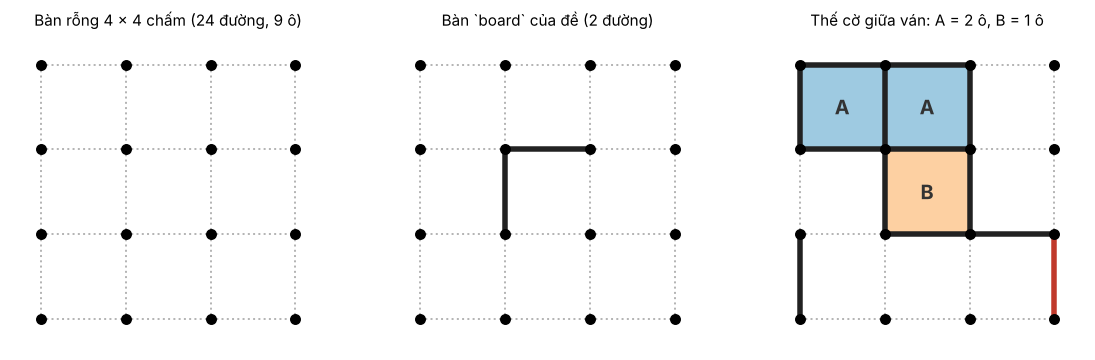

In [7]:
# Your code/ answer goes here.

# ---- Hiển thị bàn cờ ----
OWNER_COLOR = {1: "#9ecae1", -1: "#fdd0a2"}      # người +1: xanh, người -1: cam
OWNER_NAME = {1: "A", -1: "B"}                   # chữ cái ghi trong ô đã đóng

def draw_board(board, ax = None, title = None, mark = None, values = None, fontsize = 9, last = None):
    """Vẽ bàn cờ. Chấm = ●; đường đã vẽ = nét đậm; đường chưa vẽ = nét chấm mờ; ô đã đóng được tô màu + chữ cái của chủ ô.
    mark:   {đường: màu}  tô màu một số đường (ví dụ nước đi tối ưu);   values: {đường: số}  ghi một số lên đường chưa vẽ;
    last:   đường vừa vẽ (nếu có) được tô viền đỏ."""
    R, C = board["size"]
    own_fig = ax is None
    if own_fig:
        _, ax = plt.subplots(figsize = (0.9 + 0.85 * (C - 1), 0.7 + 0.85 * (R - 1)), dpi = 110)
    boxes = board["boxes"] if isinstance(board["boxes"], dict) else {}      # 'boxes': dict (lớp) trong ô code của đề -> coi như rỗng
    for (r, c), p in boxes.items():
        ax.add_patch(plt.Rectangle((c, -r - 1), 1, 1, color = OWNER_COLOR[p], zorder = 0))
        ax.text(c + 0.5, -r - 0.5, OWNER_NAME[p], ha = "center", va = "center", fontsize = fontsize + 4, fontweight = "bold", color = "#333")
    for line in all_lines(board["size"]):
        o, r, c = line
        (x0, y0), (x1, y1) = ((c, -r), (c + 1, -r)) if o == "h" else ((c, -r), (c, -r - 1))
        if line in board["lines"]:
            ax.plot([x0, x1], [y0, y1], "-", color = "#c0392b" if line == last else "#222", lw = 3.6, solid_capstyle = "round", zorder = 3)
        else:
            col = (mark or {}).get(line)
            ax.plot([x0, x1], [y0, y1], "-" if col else ":", color = col or "#b5b5b5", lw = 4.2 if col else 1.3, solid_capstyle = "round", zorder = 2 if col else 1)
            if values is not None and line in values:
                ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{values[line]:+d}", ha = "center", va = "center", fontsize = fontsize - 1, zorder = 5,
                        bbox = dict(boxstyle = "round,pad=0.12", fc = "white", ec = col or "#b5b5b5", lw = 0.8))
    ax.scatter([c for r in range(R) for c in range(C)], [-r for r in range(R) for c in range(C)], s = 38, color = "black", zorder = 4)
    ax.set_xlim(-0.35, C - 0.65); ax.set_ylim(-(R - 1) - 0.35, 0.35)
    ax.set_aspect("equal"); ax.axis("off")
    if title:
        ax.set_title(title, fontsize = fontsize + 1)
    if own_fig:
        plt.tight_layout(); plt.show()

# Ví dụ 1: bàn `board` của đề (2 đường đã vẽ; 'boxes' của đề là lớp dict nên hàm coi như chưa có ô nào).
# Ví dụ 2: một thế cờ tự dựng trên bàn 4 × 4 chấm: A đã đóng 2 ô, B đã đóng 1 ô.
demo_lines = [("h", 0, 0), ("h", 1, 0), ("v", 0, 0), ("v", 0, 1), ("h", 0, 1), ("h", 1, 1), ("v", 0, 2),
              ("h", 2, 1), ("v", 1, 1), ("v", 1, 2), ("h", 2, 2), ("v", 2, 0), ("v", 2, 3)]
demo_board = {"size": (4, 4), "lines": {l: True for l in demo_lines}, "boxes": {(0, 0): 1, (0, 1): 1, (1, 1): -1}}
empty_44 = {"size": (4, 4), "lines": {}, "boxes": {}}

fig, axes = plt.subplots(1, 3, figsize = (10.5, 3.3), dpi = 110)
draw_board(empty_44, ax = axes[0], title = "Bàn rỗng 4 × 4 chấm (24 đường, 9 ô)")
draw_board(board, ax = axes[1], title = "Bàn `board` của đề (2 đường)")
draw_board(demo_board, ax = axes[2], title = "Thế cờ giữa ván: A = 2 ô, B = 1 ô", last = ("v", 2, 3))
plt.tight_layout(); plt.show()

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [8]:
# Your code/ answer goes here.

# ---- Mô hình chuyển trạng thái, kiểm tra kết thúc, lợi ích, hành động (dùng cho bàn cờ có kích thước bất kỳ) ----
def new_board(rows = 4, cols = 4):
    """Bàn rỗng, cùng cấu trúc với đề: size = (số hàng chấm, số cột chấm); lines = {đường: True}; boxes = {(r, c): người đóng ô}."""
    return {"size": (rows, cols), "lines": dict(), "boxes": dict()}

def copy_board(board):
    return {"size": board["size"], "lines": dict(board["lines"]), "boxes": dict(board["boxes"])}

def actions(board):
    """actions(s): mọi đường chưa vẽ (danh sách rỗng khi ván đã kết thúc)."""
    drawn = board["lines"]
    return [l for l in all_lines(board["size"]) if l not in drawn]

def result(board, player, action):
    """result(s, a): bàn cờ MỚI sau khi `player` (+1/-1) vẽ đường `action`. Mọi ô vừa có đủ 4 cạnh được ghi vào board['boxes']
    dưới dạng (row, col): player. Nước đi không hợp lệ (ngoài bàn / đã vẽ) ném ValueError."""
    if action not in line_set(board["size"]) or action in board["lines"]:
        raise ValueError(f"Nước đi không hợp lệ: {action}")
    new = copy_board(board)
    new["lines"][action] = True
    for box in boxes_of_line(board["size"], action):
        if box not in new["boxes"] and all(side in new["lines"] for side in box_sides(box)):
            new["boxes"][box] = player
    return new

def next_player(board, new_board_, player):
    """Luật đi tiếp: nếu nước vừa rồi đóng được ít nhất một ô thì `player` đi tiếp, ngược lại đến lượt đối thủ."""
    return player if len(new_board_["boxes"]) > len(board["boxes"]) else -player

def terminal(board):
    """terminal(s): ván kết thúc khi mọi đường đã được vẽ (khi đó mọi ô đều đã có chủ)."""
    return len(board["lines"]) == n_lines(board["size"])

def score(board, player):
    """Số ô `player` đã đóng."""
    return sum(1 for p in board["boxes"].values() if p == player)

def utility(board, player):
    """utility(s) với trạng thái kết thúc: HIỆU SỐ Ô (số ô của `player` − số ô của đối thủ). Dấu cho kết quả thắng (+) / hòa (0) / thua (−).
    (Với trạng thái chưa kết thúc, hàm trả về hiệu số ô hiện tại.)"""
    return score(board, player) - score(board, -player)

In [9]:
def run_unit_tests():
    """Kiểm tra các hàm trên những tình huống đã biết trước đáp án (in 'OK' nếu tất cả đều đúng)."""
    # 1. Đóng ô -> được đi tiếp; nước không đóng ô -> đổi lượt
    b = new_board(3, 3)
    for a in [("h", 0, 0), ("v", 0, 0), ("v", 0, 1)]:
        nb = result(b, 1, a); assert next_player(b, nb, 1) == -1; b = nb
    nb = result(b, 1, ("h", 1, 0))
    assert nb["boxes"] == {(0, 0): 1} and next_player(b, nb, 1) == 1 and b["boxes"] == {}, "đóng ô: chủ ô = người vẽ, người này đi tiếp, bàn cũ không đổi"
    # 2. Một đường đóng HAI ô cùng lúc
    b = new_board(3, 3)
    for a in [("h", 0, 0), ("h", 1, 0), ("v", 0, 0), ("h", 0, 1), ("h", 1, 1), ("v", 0, 2)]:
        b = result(b, 1, a)
    nb = result(b, -1, ("v", 0, 1))
    assert nb["boxes"] == {(0, 0): -1, (0, 1): -1} and next_player(b, nb, -1) == -1, "đường chung đóng 2 ô"
    # 3. Nước đi không hợp lệ bị từ chối (kể cả những đường ngoài bàn mà draw_line của đề chấp nhận)
    b = new_board(3, 3)
    for bad in [("h", 0, 2), ("v", 2, 0), ("h", 3, 0), ("x", 0, 0), ("h", -1, 0)]:
        try:
            result(b, 1, bad); raise AssertionError(f"{bad} phải bị từ chối")
        except ValueError:
            pass
    try:
        result(result(b, 1, ("h", 0, 0)), -1, ("h", 0, 0)); raise AssertionError("đường đã vẽ phải bị từ chối")
    except ValueError:
        pass
    # 4. Mọi ván chơi ngẫu nhiên: đúng L nước, mọi ô có chủ, tổng điểm = số ô, utility đối xứng
    rng = random.Random(0)
    for size in [(2, 2), (2, 5), (3, 3), (4, 4), (5, 3)]:
        b, p, moves = new_board(*size), 1, 0
        while not terminal(b):
            a = rng.choice(actions(b)); nb = result(b, p, a); p = next_player(b, nb, p); b = nb; moves += 1
        assert moves == n_lines(size) and len(b["boxes"]) == n_boxes(size) and actions(b) == []
        assert score(b, 1) + score(b, -1) == n_boxes(size) and utility(b, 1) == -utility(b, -1)
    print("OK: result / next_player / terminal / utility / actions đúng trên mọi tình huống kiểm tra.")
    tmp = {"size": (3, 3), "lines": dict(), "boxes": dict()}
    print("Đối chiếu: draw_line của đề chấp nhận ('h', 0, 2) trên bàn 3 × 3 chấm (ngoài bàn)?", draw_line(tmp, "h", 0, 2),
          "| hàm result của ta:", "từ chối" if ("h", 0, 2) not in line_set((3, 3)) else "chấp nhận")

run_unit_tests()

OK: result / next_player / terminal / utility / actions đúng trên mọi tình huống kiểm tra.
Đối chiếu: draw_line của đề chấp nhận ('h', 0, 2) trên bàn 3 × 3 chấm (ngoài bàn)? True | hàm result của ta: từ chối


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [10]:
# Your code/ answer goes here.

def random_player(board, player = None):
    """Agent ngẫu nhiên: nhận bàn cờ (percept) và trả về một đường chưa vẽ, chọn đều ngẫu nhiên."""
    return random.choice(actions(board))

# kiểm tra nhanh: nước đi trả về luôn hợp lệ
_b = new_board(4, 4)
assert all(random_player(_b) in actions(_b) for _ in range(100))
print("random_player trả về nước đi hợp lệ:", random_player(_b))

random_player trả về nước đi hợp lệ: ('v', 1, 3)


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

,Bàn (chấm),Số ô,Số ván,Người 1 (đi trước) thắng,Người −1 thắng,Hòa,Hiệu số ô TB (người 1 − người −1),Số lần đổi lượt TB
0,3 × 3,4,1000,411,413,176,-0.002,9.6
1,4 × 4,9,1000,511,489,0,0.080,17.7
2,5 × 5,16,1000,485,446,69,0.148,28.4


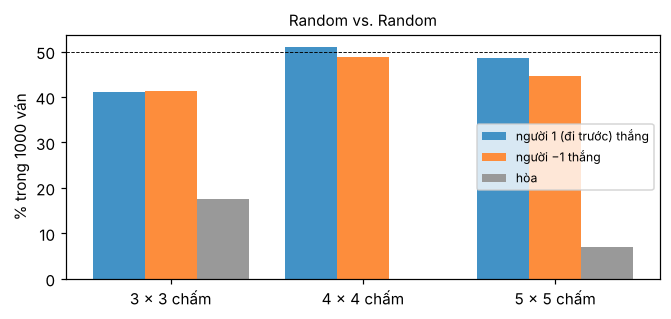

In [11]:
# Your code/ answer goes here.

# ---- Môi trường: cho hai agent chơi với nhau ----
def play(agent_1, agent_2, size = (4, 4), board = None, player = 1):
    """Một ván đấu. agent_1 điều khiển người +1 (đi trước), agent_2 điều khiển người -1.
    Mỗi agent là hàm agent(board, player) -> đường. Luật đi tiếp: người vừa đóng ô được đi tiếp (next_player).
    Trả về dict: winner (+1/-1/0), margin (= ô của +1 trừ ô của -1), moves, turns (số lần đổi lượt + 1), thời gian và số lần gọi của từng agent."""
    board = new_board(*size) if board is None else board
    agents, spent, calls = {1: agent_1, -1: agent_2}, {1: 0.0, -1: 0.0}, {1: 0, -1: 0}
    turns = 1
    while not terminal(board):
        t0 = time.perf_counter()
        action = agents[player](board, player)
        spent[player] += time.perf_counter() - t0; calls[player] += 1
        new = result(board, player, action)               # ném ValueError nếu agent trả về nước không hợp lệ
        nxt = next_player(board, new, player)
        turns += (nxt != player)
        board, player = new, nxt
    margin = utility(board, 1)
    return dict(winner = (margin > 0) - (margin < 0), margin = margin, moves = sum(calls.values()), turns = turns,
                t1 = spent[1], t2 = spent[-1], n1 = calls[1], n2 = calls[-1], board = board)

def run_games(agent_1, agent_2, n, size = (4, 4), seed = None):
    if seed is not None:
        random.seed(seed)
    return [play(agent_1, agent_2, size) for _ in range(n)]

def summarize(games):
    """Gộp kết quả nhiều ván: số ván thắng của người +1 / người -1 / hòa, hiệu số ô trung bình, thời gian trung bình mỗi nước của mỗi agent (ms)."""
    n = len(games)
    w1, w2 = sum(g["winner"] == 1 for g in games), sum(g["winner"] == -1 for g in games)
    return dict(n = n, win1 = w1, win2 = w2, draw = n - w1 - w2, margin = float(np.mean([g["margin"] for g in games])),
                ms1 = 1000 * sum(g["t1"] for g in games) / max(1, sum(g["n1"] for g in games)),
                ms2 = 1000 * sum(g["t2"] for g in games) / max(1, sum(g["n2"] for g in games)),
                turns = float(np.mean([g["turns"] for g in games])))

N_RANDOM = 1000
random_summary = {}
for size in [(3, 3), (4, 4), (5, 5)]:
    random_summary[size] = summarize(run_games(random_player, random_player, N_RANDOM, size, seed = 2026))

main_size = (4, 4)           # bàn trong ô code của đề
display(pd.DataFrame([{"Bàn (chấm)": f"{s[0]} × {s[1]}", "Số ô": n_boxes(s), "Số ván": r["n"], "Người 1 (đi trước) thắng": r["win1"], "Người −1 thắng": r["win2"], "Hòa": r["draw"],
                       "Hiệu số ô TB (người 1 − người −1)": round(r["margin"], 3), "Số lần đổi lượt TB": round(r["turns"], 1)} for s, r in random_summary.items()]))

fig, ax = plt.subplots(figsize = (6.2, 3.0), dpi = 110)
xs = np.arange(len(random_summary))
vals = {k: [100 * r[k] / r["n"] for r in random_summary.values()] for k in ("win1", "win2", "draw")}
for i, (k, lab, col) in enumerate([("win1", "người 1 (đi trước) thắng", "#4292c6"), ("win2", "người −1 thắng", "#fd8d3c"), ("draw", "hòa", "#999999")]):
    ax.bar(xs + (i - 1) * 0.27, vals[k], 0.27, label = lab, color = col)
ax.axhline(50, color = "k", lw = 0.6, ls = "--")
ax.set_xticks(xs); ax.set_xticklabels([f"{s[0]} × {s[1]} chấm" for s in random_summary]); ax.set_ylabel(f"% trong {N_RANDOM} ván"); ax.legend(fontsize = 8)
ax.set_title("Random vs. Random", fontsize = 10); plt.tight_layout(); plt.show()

In [12]:
def binom_p(k, n):
    """p-value hai phía của kiểm định nhị thức (xác suất 1/2) - tính chính xác."""
    if n == 0:
        return 1.0
    tail = sum(math.comb(n, i) for i in range(0, min(k, n - k) + 1)) / 2 ** n
    return min(1.0, 2 * tail)

r44 = random_summary[main_size]
dec44 = r44["win1"] + r44["win2"]
p44 = binom_p(r44["win1"], dec44)
sig = [(s, binom_p(r["win1"], r["win1"] + r["win2"])) for s, r in random_summary.items()]
sig_txt = ", ".join(f"{s[0]} × {s[1]}: p = {p:.2f}" for s, p in sig)
r33, r55 = random_summary[(3, 3)], random_summary[(5, 5)]
sd44 = float(np.std([g["margin"] for g in run_games(random_player, random_player, 300, main_size)]))
display(Markdown(f"""
**Kết quả (bàn 4 × 4 chấm, {r44['n']} ván):** người 1 (đi trước) thắng **{r44['win1']}** ván ({100 * r44['win1'] / r44['n']:.1f} %), người −1 thắng **{r44['win2']}** ván ({100 * r44['win2'] / r44['n']:.1f} %), hòa **{r44['draw']}** ván ({100 * r44['draw'] / r44['n']:.1f} %); hiệu số ô trung bình {r44['margin']:+.2f}.

**Kết quả có đúng như mong đợi không? Có.**
* **Không có lợi thế đi trước khi chơi ngẫu nhiên.** Hai agent giống hệt nhau và nước đi hoàn toàn ngẫu nhiên nên không ai có thông tin hơn ai. Kiểm định nhị thức (giả thuyết: mỗi bên thắng với xác suất 1/2 trong các ván phân thắng bại) cho p = {p44:.2f} cho bàn 4 × 4; với cả ba kích thước: {sig_txt}. {'Không kích thước nào bác bỏ được giả thuyết "hai bên ngang nhau" ở mức 5 %.' if all(p > 0.05 for _, p in sig) else 'Có kích thước cho p < 0.05; vì đã thực hiện 3 kiểm định nên một p nhỏ có thể chỉ do ngẫu nhiên (cần nhiều ván hơn để kết luận).'} (Khác Connect 4 thường – nơi người đi trước thắng ≈ 56 % ván ngẫu nhiên – vì ở đây người đóng được ô lại được đi tiếp nên "quyền đi trước" không còn là lợi thế cố định.)
* **Hòa:** bàn 4 × 4 chấm có 9 ô (số lẻ) nên **không thể hòa** ({r44['draw']} ván hòa); bàn 3 × 3 chấm (4 ô) hòa {100 * r33['draw'] / r33['n']:.1f} % và bàn 5 × 5 chấm (16 ô) hòa {100 * r55['draw'] / r55['n']:.1f} % số ván vì số ô chẵn cho phép chia đều.
* Mỗi ván có trung bình {r44['turns']:.1f} lần đổi lượt (so với 24 nếu mỗi người chỉ đi một nước), vì người đóng được ô thì đi tiếp; hiệu số ô của một ván dao động khá mạnh (độ lệch chuẩn ≈ {sd44:.1f} ô). Kết quả này là **đường cơ sở**: một agent thông minh phải thắng Random hầu hết số ván ở cả hai vai.
"""))


**Kết quả (bàn 4 × 4 chấm, 1000 ván):** người 1 (đi trước) thắng **511** ván (51.1 %), người −1 thắng **489** ván (48.9 %), hòa **0** ván (0.0 %); hiệu số ô trung bình +0.08.

**Kết quả có đúng như mong đợi không? Có.**
* **Không có lợi thế đi trước khi chơi ngẫu nhiên.** Hai agent giống hệt nhau và nước đi hoàn toàn ngẫu nhiên nên không ai có thông tin hơn ai. Kiểm định nhị thức (giả thuyết: mỗi bên thắng với xác suất 1/2 trong các ván phân thắng bại) cho p = 0.51 cho bàn 4 × 4; với cả ba kích thước: 3 × 3: p = 0.97, 4 × 4: p = 0.51, 5 × 5: p = 0.21. Không kích thước nào bác bỏ được giả thuyết "hai bên ngang nhau" ở mức 5 %. (Khác Connect 4 thường – nơi người đi trước thắng ≈ 56 % ván ngẫu nhiên – vì ở đây người đóng được ô lại được đi tiếp nên "quyền đi trước" không còn là lợi thế cố định.)
* **Hòa:** bàn 4 × 4 chấm có 9 ô (số lẻ) nên **không thể hòa** (0 ván hòa); bàn 3 × 3 chấm (4 ô) hòa 17.6 % và bàn 5 × 5 chấm (16 ô) hòa 6.9 % số ván vì số ô chẵn cho phép chia đều.
* Mỗi ván có trung bình 17.7 lần đổi lượt (so với 24 nếu mỗi người chỉ đi một nước), vì người đóng được ô thì đi tiếp; hiệu số ô của một ván dao động khá mạnh (độ lệch chuẩn ≈ 5.6 ô). Kết quả này là **đường cơ sở**: một agent thông minh phải thắng Random hầu hết số ván ở cả hai vai.


## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

**Thiết kế.** Ta cài Minimax dạng **negamax** và Alpha-Beta trên biểu diễn bit của bàn cờ (mỗi đường là một bit, một thế cờ là một số nguyên):

* **Giá trị của một thế cờ** là *hiệu số ô thu thêm* trong phần còn lại của ván: (số ô người đến lượt thu thêm) − (số ô đối thủ thu thêm), khi cả hai chơi tối ưu. Giá trị này không phụ thuộc vào ai đã đóng ô nào trước đó, nên **bảng chuyển vị** chỉ cần khoá theo tập đường đã vẽ (≈ 2^L thế cờ, xem Task 1).
* **Luật đi tiếp** là điểm khác Tic-Tac-Toe: nếu nước đi *không* đóng ô thì đến lượt đối thủ, giá trị đổi dấu `v = −search(con)`; nếu nước đi đóng được `g` ô thì **cùng người đó đi tiếp**, giá trị *không* đổi dấu và được cộng thêm `g`: `v = g + search(con)`. Cửa sổ (α, β) cũng được dịch tương ứng (`α − g, β − g`) khi người đi giữ lượt.
* **Bảng chuyển vị** có lưu cận (chính xác / cận dưới / cận trên) vì Alpha-Beta thường chỉ chứng minh được một cận của giá trị.
* **Sắp xếp nước đi** (tham số `ordering`, được so sánh ở mục *Move ordering*). Mặc định: nước **đóng ô** trước, rồi nước **an toàn** (không tạo ô có 3 cạnh – nếu không sẽ biếu ô cho đối thủ), rồi các nước còn lại.
* Tác tử `AlphaBetaPlayer(board, player)` có cùng chữ ký với `random_player`, và **giữ bảng chuyển vị giữa các nước đi** (giá trị của một thế cờ không đổi nên dùng lại được) - nước đi sau thường rẻ hơn nước đầu nhiều.

In [13]:
# Your code/ answer goes here.

# ---- Minimax (negamax) + Alpha-Beta + bảng chuyển vị, có luật "đóng ô được đi tiếp" ----
class TimeUp(Exception):
    """Ném ra khi vượt giới hạn thời gian / bộ nhớ (dùng cho các thí nghiệm trên bàn lớn)."""

class ExactSolver:
    """Giải CHÍNH XÁC một cỡ bàn cờ. Mọi thế cờ là số nguyên `lines` (bit i = 1 <=> đường thứ i đã vẽ).
    search(lines, alpha, beta) = giá trị của thế cờ = (ô người đi thu thêm) − (ô đối thủ thu thêm) với hai bên chơi tối ưu.
      * nước KHÔNG đóng ô:  v = −search(con, −β, −α)               (đổi lượt)
      * nước đóng g ô:      v = g + search(con, α − g, β − g)      (người đó đi tiếp, không đổi dấu)
    ordering: 'natural' (theo chỉ số đường) | 'captures' (nước đóng ô trước) | 'safe' (đóng ô, rồi nước an toàn - không tạo cạnh thứ 3 -, rồi còn lại)
              | 'sacrifice' (như 'safe' nhưng nước biếu ít ô đi trước, nước đóng nhiều ô đi trước)."""
    def __init__(self, size, ordering = "safe", use_tt = True, time_limit = None, max_tt = None):
        self.g = geom(size)
        self.size, self.ordering, self.use_tt = size, ordering, use_tt
        self.time_limit, self.max_tt = time_limit, max_tt
        self.tt = {}                    # lines -> cờ (2 bit thấp: 0 chính xác, 1 cận dưới, 2 cận trên) + (giá trị + 64) << 2
        self.nodes = 0
        self.deadline = None

    def reset(self):
        self.tt.clear(); self.nodes = 0

    def moves(self, lines):
        """Các nước đi (chỉ số đường, số ô đóng được) theo thứ tự đã chọn."""
        g, adj, order = self.g, self.g.adj, self.ordering
        caps, rest, safe, unsafe = [], [], [], []
        for l in range(g.L):
            bit = 1 << l
            if lines & bit:
                continue
            nl = lines | bit
            gain = bad = 0
            for m in adj[l]:
                x = nl & m
                if x == m:
                    gain += 1
                elif popcount(x) == 3:
                    bad += 1
            if order == "natural":
                rest.append((l, gain))
            elif gain:
                caps.append((l, gain))
            elif order == "captures":
                rest.append((l, 0))
            elif bad:
                unsafe.append((bad, l))
            else:
                safe.append((l, 0))
        if order == "natural":
            return rest
        if order == "captures":
            return caps + rest
        if order == "sacrifice":
            unsafe.sort()
            caps.sort(key = lambda t: -t[1])
        return caps + safe + [(l, 0) for _, l in unsafe]

    def check(self):
        if self.deadline is not None and time.perf_counter() > self.deadline:
            raise TimeUp("hết thời gian")
        if self.max_tt is not None and len(self.tt) > self.max_tt:
            raise TimeUp("bảng chuyển vị quá lớn")

    def search(self, lines, alpha, beta):
        self.nodes += 1
        if self.nodes & 8191 == 0:
            self.check()
        if lines == self.g.full:
            return 0
        tt = self.tt
        if self.use_tt:
            e = tt.get(lines)
            if e is not None:
                flag, val = e & 3, (e >> 2) - 64
                if flag == 0:
                    return val
                if flag == 1:
                    if val >= beta:
                        return val
                    if val > alpha:
                        alpha = val
                else:
                    if val <= alpha:
                        return val
                    if val < beta:
                        beta = val
                if alpha >= beta:
                    return val
        a0, best = alpha, -99
        for l, gain in self.moves(lines):
            nl = lines | (1 << l)
            v = gain + self.search(nl, alpha - gain, beta - gain) if gain else -self.search(nl, -beta, -alpha)
            if v > best:
                best = v
                if v > alpha:
                    alpha = v
                    if alpha >= beta:
                        break
        if self.use_tt:
            tt[lines] = (2 if best <= a0 else (1 if best >= beta else 0)) | ((best + 64) << 2)
        return best

    def _start(self):
        self.deadline = time.perf_counter() + self.time_limit if self.time_limit else None

    def solve(self, lines = 0):
        """Giá trị của thế cờ `lines` (đã đếm nút vào self.nodes, bảng chuyển vị được GIỮ LẠI)."""
        self.nodes = 0; self._start()
        return self.search(lines, -99, 99)

    def action_values(self, lines, only = None):
        """{chỉ số đường: giá trị CHÍNH XÁC của nước đó} - cửa sổ đầy đủ cho từng nước (chỉ xét các đường trong `only` nếu có)."""
        self.nodes = 0; self._start()
        out = {}
        for l, gain in self.moves(lines):
            if only is not None and l not in only:
                continue
            nl = lines | (1 << l)
            out[l] = gain + self.search(nl, -99, 99) if gain else -self.search(nl, -99, 99)
        return out

    def best_move(self, lines):
        """(chỉ số đường, giá trị) của nước tốt nhất; thu hẹp alpha dần nên nhanh hơn action_values.
        Khi nhiều nước cùng giá trị, chọn nước đầu tiên theo thứ tự duyệt."""
        self.nodes = 0; self._start()
        alpha, best_l = -99, None
        for l, gain in self.moves(lines):
            nl = lines | (1 << l)
            v = gain + self.search(nl, alpha - gain, 99 - gain) if gain else -self.search(nl, -99, -alpha)
            if best_l is None or v > alpha:
                alpha, best_l = v, l
        return best_l, alpha

class AlphaBetaPlayer:
    """Agent: nhận (board, player) và trả về một đường. Bảng chuyển vị được giữ lại giữa các nước đi (mỗi cỡ bàn một bảng)."""
    def __init__(self, ordering = "safe", use_tt = True, name = None):
        self.ordering, self.use_tt = ordering, use_tt
        self.name = name or f"Alpha-Beta ({ordering}{'' if use_tt else ', không TT'})"
        self.solvers, self.last_nodes, self.last_value = {}, 0, None

    def solver(self, size):
        if size not in self.solvers:
            self.solvers[size] = ExactSolver(size, self.ordering, self.use_tt)
        return self.solvers[size]

    def __call__(self, board, player = None):
        s = self.solver(board["size"])
        l, v = s.best_move(s.g.mask(board))
        self.last_nodes, self.last_value = s.nodes, v
        return s.g.lines[l]

# Thử nhanh: bàn 3 × 3 chấm (2 × 2 ô) từ bàn rỗng
_s = ExactSolver((3, 3))
print("Giá trị bàn rỗng 3 × 3 chấm:", _s.solve(), "| số nút:", _s.nodes, "| mục trong bảng chuyển vị:", len(_s.tt))

Giá trị bàn rỗng 3 × 3 chấm: 2 | số nút: 4961 | mục trong bảng chuyển vị: 1369


**Kiểm chứng bộ giải.** Trước khi dùng kết quả, ta so sánh với một cài đặt Minimax *thuần* độc lập (dùng đúng các hàm `actions`, `result`, `next_player` của Task 2, không bit, không cắt tỉa, chỉ nhớ giá trị theo tập đường). Hai bên phải cho **cùng giá trị** cho bàn rỗng với mọi chiến lược sắp xếp (có và không có bảng chuyển vị), và cùng giá trị cho **từng** nước đi ở nhiều thế cờ ngẫu nhiên.

In [14]:
def reference_values(board):
    """Minimax thuần bằng các hàm của Task 2 (dict, không bit, không cắt tỉa). Trả về (giá trị thế cờ, {nước đi: giá trị nước đó})."""
    memo = {}
    def fut(b):
        key = frozenset(b["lines"])
        if key in memo:
            return memo[key]
        if terminal(b):
            return 0
        best = -99
        for a in actions(b):
            nb = result(b, 1, a)                                    # chủ ô không ảnh hưởng đến giá trị tương lai
            g_ = len(nb["boxes"]) - len(b["boxes"])
            best = max(best, g_ + fut(nb) if g_ else -fut(nb))
        memo[key] = best
        return best
    per_action = {}
    for a in actions(board):
        nb = result(board, 1, a)
        g_ = len(nb["boxes"]) - len(board["boxes"])
        per_action[a] = g_ + fut(nb) if g_ else -fut(nb)
    return (max(per_action.values()) if per_action else 0), per_action

def random_position(size, n_drawn, rng):
    """Thế cờ có n_drawn đường đã vẽ ngẫu nhiên (đường được vẽ lần lượt, người chơi luân phiên theo luật đi tiếp)."""
    b, p = new_board(*size), 1
    for a in rng.sample(list(all_lines(size)), n_drawn):
        nb = result(b, p, a); p = next_player(b, nb, p); b = nb
    return b

XVAL_EMPTY = [(2, 2), (2, 3), (2, 4), (3, 3), (2, 5)]                  # các bàn rỗng được so sánh
XVAL_POS = 15                      # số thế cờ ngẫu nhiên mỗi bàn
rng_x, xrows, bad_total = random.Random(7), [], 0
for size in XVAL_EMPTY:
    ref_val, _ = reference_values(new_board(*size))
    vals = {}
    for ordering in ["natural", "captures", "safe", "sacrifice"]:
        for use_tt in (True, False):
            if not use_tt and n_lines(size) > 10:
                continue                                           # không có bảng chuyển vị thì chỉ thử bàn rất nhỏ
            vals[(ordering, use_tt)] = ExactSolver(size, ordering, use_tt).solve()
    ok_empty = all(v == ref_val for v in vals.values())
    compared = mism = 0
    for _ in range(XVAL_POS):
        b = random_position(size, rng_x.randint(max(1, n_lines(size) // 3), n_lines(size) - 2), rng_x)
        if terminal(b):
            continue
        s = ExactSolver(size, "safe"); g_ = s.g
        _, ref_act = reference_values(b)
        mine = {g_.lines[l]: v for l, v in s.action_values(g_.mask(b)).items()}
        compared += len(ref_act); mism += sum(mine[a] != v for a, v in ref_act.items())
    bad_total += (not ok_empty) + mism
    xrows.append({"Bàn": f"{size[0]} × {size[1]}", "Giá trị bàn rỗng (Minimax thuần)": ref_val, "Số cấu hình bộ giải kiểm tra": len(vals), "Mọi cấu hình cho cùng giá trị": ok_empty,
                  "Số giá trị nước đi so sánh": compared, "Số giá trị khác nhau": mism})
display(pd.DataFrame(xrows))
assert bad_total == 0, "bộ giải Alpha-Beta không khớp Minimax thuần!"
print("OK: Alpha-Beta + bảng chuyển vị cho đúng giá trị Minimax trên mọi bàn / thế cờ kiểm tra.")

,Bàn,Giá trị bàn rỗng (Minimax thuần),Số cấu hình bộ giải kiểm tra,Mọi cấu hình cho cùng giá trị,Số giá trị nước đi so sánh,Số giá trị khác nhau
0,2 × 2,-1,8,True,41,0
1,2 × 3,0,8,True,50,0
2,2 × 4,-1,8,True,73,0
3,3 × 3,2,4,True,80,0
4,2 × 5,0,4,True,88,0


OK: Alpha-Beta + bảng chuyển vị cho đúng giá trị Minimax trên mọi bàn / thế cờ kiểm tra.


In [15]:
class GreedyPlayer:
    """Agent tham lam (đường cơ sở để so sánh): (1) đóng ô nếu có thể (ưu tiên nước đóng nhiều ô); (2) nếu không, vẽ một đường "an toàn"
    (không tạo ô có 3 cạnh); (3) nếu hết, biếu ít ô nhất. Không nhìn trước nên không biết "nhường ô để giữ quyền kiểm soát"."""
    def __init__(self, randomize = True, seed = None):
        self.randomize, self.rng, self.name = randomize, random.Random(seed), "Tham lam (đóng ô / nước an toàn)"

    def __call__(self, board, player = None):
        g = geom(board["size"]); lines = g.mask(board)
        caps, safe, unsafe = [], [], []
        for l in range(g.L):
            bit = 1 << l
            if lines & bit:
                continue
            nl = lines | bit
            gain = bad = 0
            for m in g.adj[l]:
                x = nl & m
                if x == m:
                    gain += 1
                elif popcount(x) == 3:
                    bad += 1
            if gain:
                caps.append((gain, l))
            elif bad:
                unsafe.append((bad, l))
            else:
                safe.append(l)
        if caps:
            best = max(c[0] for c in caps)
            return g.lines[min(l for c, l in caps if c == best)]
        if safe:
            return g.lines[self.rng.choice(safe) if self.randomize else safe[0]]
        return g.lines[min(unsafe)[1]]

Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

**Các bàn thử.** Ta dựng 4 thế cờ trên bàn 3 × 4 chấm (2 × 3 ô), mỗi thế cờ minh họa một tình huống mà agent phải nhận ra. Người đến lượt luôn là A (xanh); ô đã đóng được tô màu và ghi chủ ô (chỉ để minh họa - giá trị tính theo phần còn lại của ván). Trên hình, mỗi đường chưa vẽ ghi **giá trị của nước đó** (hiệu số ô thu thêm của người đi, hai bên chơi tối ưu) và nước tối ưu được tô xanh lá. Để so sánh, agent **tham lam** (đóng ô nếu có thể, nếu không thì vẽ nước an toàn) cũng được thử:

1. **Đóng ô miễn phí:** có thể đóng cả một dây ô; agent phải nhận ra cơ hội.
2. **Nhường ô để giữ quyền kiểm soát (double-dealing):** đóng ô ngay là *sai*; nước đúng là chừa lại hai ô cho đối thủ để buộc họ phải mở dây tiếp theo.
3. **Nước an toàn đúng số lượt:** mọi nước đều "an toàn" nhưng chỉ một nước thắng, vì nó quyết định *ai phải mở dây đầu tiên* (chẵn/lẻ số nước an toàn còn lại).
4. **Hy sinh để thắng:** mọi nước an toàn đều thua nhưng biếu ô đúng chỗ thì thắng.

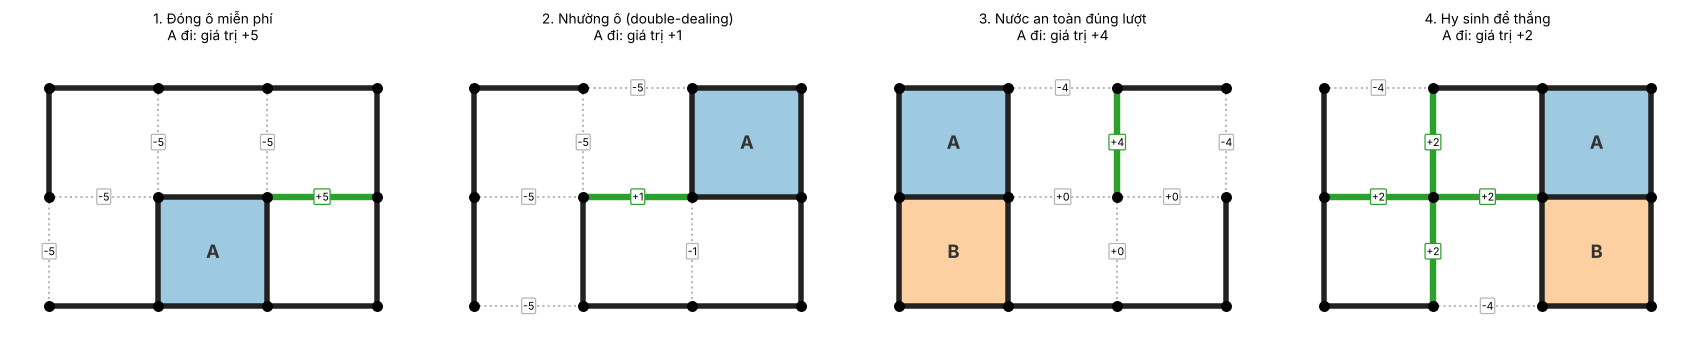

,Bàn,Số đường còn lại,Giá trị tối ưu của A,Nước tối ưu,Alpha-Beta chọn,Tham lam chọn,Giá trị kỳ vọng nếu chọn ngẫu nhiên
0,1. Đóng ô miễn phí,5,5,h12,h12 (+5),h12 (+5),-3.00
1,2. Nhường ô (double-dealing),6,1,h11,h11 (+1),v12 (-1),-3.33
2,3. Nước an toàn đúng lượt,6,4,v02,v02 (+4),h01 (-4),-0.67
3,4. Hy sinh để thắng,6,2,"h10, h11, v01, v11",h10 (+2),h00 (-4),0.00


In [16]:
# Your code/ answer goes here.

def board_from_lines(size, line_list):
    """Dựng bàn cờ từ danh sách đường đã vẽ; ô đã đóng được gán chủ luân phiên (chỉ để hiển thị)."""
    b, owner = new_board(*size), 1
    for a in line_list:
        nb = result(b, owner, a)
        if len(nb["boxes"]) > len(b["boxes"]):
            owner = -owner
        b = nb
    return b

TEST_BOARDS = [
    dict(name = "1. Đóng ô miễn phí", size = (3, 4),
         lines = [("h", 0, 0), ("h", 0, 1), ("h", 0, 2), ("h", 1, 1), ("h", 2, 0), ("h", 2, 1), ("h", 2, 2), ("v", 0, 0), ("v", 0, 3), ("v", 1, 1), ("v", 1, 2), ("v", 1, 3)]),
    dict(name = "2. Nhường ô (double-dealing)", size = (3, 4),
         lines = [("h", 0, 0), ("h", 0, 2), ("h", 1, 2), ("h", 2, 1), ("h", 2, 2), ("v", 0, 0), ("v", 0, 2), ("v", 0, 3), ("v", 1, 0), ("v", 1, 1), ("v", 1, 3)]),
    dict(name = "3. Nước an toàn đúng lượt", size = (3, 4),
         lines = [("h", 0, 0), ("h", 0, 2), ("h", 1, 0), ("h", 2, 0), ("h", 2, 1), ("h", 2, 2), ("v", 0, 0), ("v", 0, 1), ("v", 1, 0), ("v", 1, 1), ("v", 1, 3)]),
    dict(name = "4. Hy sinh để thắng", size = (3, 4),
         lines = [("h", 0, 1), ("h", 0, 2), ("h", 1, 2), ("h", 2, 0), ("h", 2, 2), ("v", 0, 0), ("v", 0, 2), ("v", 0, 3), ("v", 1, 0), ("v", 1, 2), ("v", 1, 3)]),
]

greedy_det = GreedyPlayer(randomize = False)
ab_agent = AlphaBetaPlayer()
manual_rows, manual_info = [], []
fig, axes = plt.subplots(1, len(TEST_BOARDS), figsize = (3.9 * len(TEST_BOARDS), 3.1), dpi = 110)
for ax, tb in zip(np.atleast_1d(axes), TEST_BOARDS):
    b = board_from_lines(tb["size"], tb["lines"]); g = geom(tb["size"])
    s = ExactSolver(tb["size"]); vals = {g.lines[l]: v for l, v in s.action_values(g.mask(b)).items()}
    best = max(vals.values()); optimal = [a for a, v in vals.items() if v == best]
    a_ab, a_gr = ab_agent(b, 1), greedy_det(b, 1)
    info = dict(name = tb["name"], left = len(vals), best = best, optimal = optimal, ab = a_ab, ab_val = vals[a_ab], gr = a_gr, gr_val = vals[a_gr], rand_val = float(np.mean(list(vals.values()))),
                n_opt = len(optimal), board = b)
    manual_info.append(info)
    draw_board(b, ax = ax, title = f"{tb['name']}\nA đi: giá trị {best:+d}", mark = {a: "#2ca02c" for a in optimal}, values = vals, fontsize = 8)
    manual_rows.append({"Bàn": tb["name"], "Số đường còn lại": len(vals), "Giá trị tối ưu của A": best, "Nước tối ưu": ", ".join(f"{o}{r}{c}" for o, r, c in optimal),
                        "Alpha-Beta chọn": f"{a_ab[0]}{a_ab[1]}{a_ab[2]} ({vals[a_ab]:+d})", "Tham lam chọn": f"{a_gr[0]}{a_gr[1]}{a_gr[2]} ({vals[a_gr]:+d})",
                        "Giá trị kỳ vọng nếu chọn ngẫu nhiên": round(info["rand_val"], 2)})
plt.tight_layout(); plt.show()
display(pd.DataFrame(manual_rows))

In [17]:
n_ok = sum(i["ab_val"] == i["best"] for i in manual_info)
n_gr = sum(i["gr_val"] == i["best"] for i in manual_info)
lost = [(i["name"], i["best"] - i["gr_val"]) for i in manual_info if i["gr_val"] < i["best"]]
display(Markdown(f"""
**Nhận xét.** Giá trị của một nước là hiệu số ô A thu thêm khi cả hai chơi tối ưu sau nước đó (số trên hình), nên nước tối ưu là nước có số lớn nhất.
* **Alpha-Beta chọn đúng nước tối ưu ở {n_ok}/{len(manual_info)} bàn**, kể cả những bàn mà nước đúng đi *ngược* trực giác: bàn 2 phải *không* đóng ô, bàn 4 phải biếu ô.
* **Agent tham lam chỉ đúng {n_gr}/{len(manual_info)} bàn**{': ' + '; '.join(f'{n} thiệt {d} ô' for n, d in lost) if lost else ''}. Nó đúng ở bàn đóng ô miễn phí, nhưng sai khi cần nhìn xa: đóng ô ngay (bàn 2) làm mất quyền kiểm soát, và chọn nước "an toàn" đầu tiên (bàn 3) không tính đến chẵn/lẻ số nước an toàn còn lại.
* **Nước chọn ngẫu nhiên rất tệ** ở các thế cờ này: giá trị kỳ vọng {', '.join(f"{i['rand_val']:+.1f}" for i in manual_info)} so với {', '.join(f"{i['best']:+d}" for i in manual_info)} của nước tối ưu - chỉ {sum(i['n_opt'] for i in manual_info)} trên tổng {sum(i['left'] for i in manual_info)} nước là tối ưu.
* Vì tìm kiếm đi tới tận cuối ván nên các kết luận này là **chính xác** (không phải ước lượng), đồng thời được kiểm chứng độc lập bằng Minimax thuần ở trên.
"""))


**Nhận xét.** Giá trị của một nước là hiệu số ô A thu thêm khi cả hai chơi tối ưu sau nước đó (số trên hình), nên nước tối ưu là nước có số lớn nhất.
* **Alpha-Beta chọn đúng nước tối ưu ở 4/4 bàn**, kể cả những bàn mà nước đúng đi *ngược* trực giác: bàn 2 phải *không* đóng ô, bàn 4 phải biếu ô.
* **Agent tham lam chỉ đúng 1/4 bàn**: 2. Nhường ô (double-dealing) thiệt 2 ô; 3. Nước an toàn đúng lượt thiệt 8 ô; 4. Hy sinh để thắng thiệt 6 ô. Nó đúng ở bàn đóng ô miễn phí, nhưng sai khi cần nhìn xa: đóng ô ngay (bàn 2) làm mất quyền kiểm soát, và chọn nước "an toàn" đầu tiên (bàn 3) không tính đến chẵn/lẻ số nước an toàn còn lại.
* **Nước chọn ngẫu nhiên rất tệ** ở các thế cờ này: giá trị kỳ vọng -3.0, -3.3, -0.7, +0.0 so với +5, +1, +4, +2 của nước tối ưu - chỉ 7 trên tổng 23 nước là tối ưu.
* Vì tìm kiếm đi tới tận cuối ván nên các kết luận này là **chính xác** (không phải ước lượng), đồng thời được kiểm chứng độc lập bằng Minimax thuần ở trên.


How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

,Bàn (chấm),Số đường,Số ô,Đã giải xong,Giá trị bàn rỗng (người đi trước),Số nút,Mục bảng chuyển vị,Thời gian (s)
0,2 × 2,4,1,có,-1,24,11,0.00
1,2 × 3,7,2,có,+0,257,92,0.00
2,2 × 4,10,3,có,-1,"1,361",376,0.00
3,3 × 3,12,4,có,+2,"4,961","1,369",0.01
4,2 × 5,13,4,có,+0,"11,031","2,881",0.02
5,2 × 6,16,5,có,-1,"45,963","11,214",0.07
6,3 × 4,17,6,có,-2,"87,645","22,920",0.15
7,2 × 7,19,6,có,+0,"378,865","90,929",0.61
8,2 × 8,22,7,có,-1,"1,970,782","426,534",3.62
9,3 × 5,22,8,có,+2,"4,487,880","1,100,011",8.85


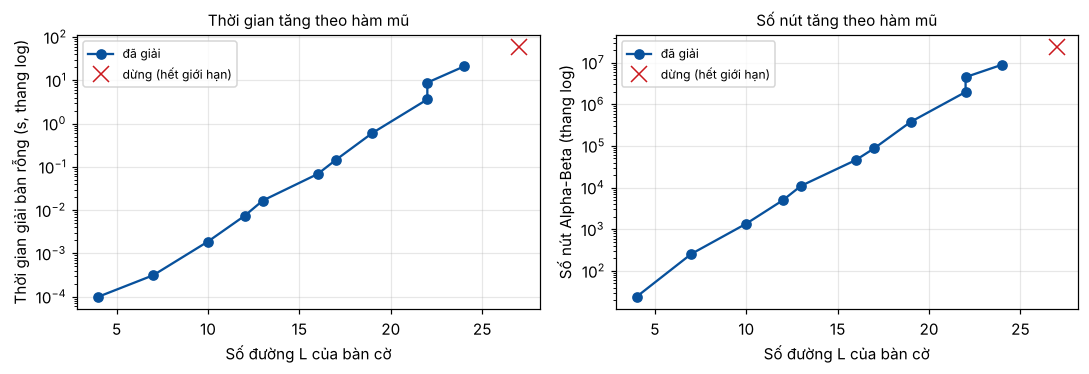

In [18]:
# Your code/ answer goes here.

# ---- Thời gian chọn nước đi đầu tiên (bàn rỗng = trường hợp khó nhất) khi tăng kích thước bàn ----
SIZE_LIST = [(2, 2), (2, 3), (2, 4), (3, 3), (2, 5), (2, 6), (3, 4), (2, 7), (2, 8), (3, 5), (4, 4), (3, 6)]            # các bàn thử (hàng chấm, cột chấm)
SIZE_LIMIT = 180          # giây tối đa cho mỗi bàn
SIZE_MAX_TT = 6000000        # số mục tối đa của bảng chuyển vị (giới hạn bộ nhớ)
size_info, size_rows = {}, []
for size in sorted(SIZE_LIST, key = lambda s: (n_lines(s), s)):
    s = ExactSolver(size, "safe", time_limit = SIZE_LIMIT, max_tt = SIZE_MAX_TT)
    t0 = time.perf_counter()
    try:
        value, solved, why = s.solve(), True, ""
    except TimeUp as e:
        value, solved, why = None, False, str(e)
    dt = time.perf_counter() - t0
    size_info[size] = dict(L = n_lines(size), B = n_boxes(size), value = value, solved = solved, nodes = s.nodes, tt = len(s.tt), time = dt, why = why)
    size_rows.append({"Bàn (chấm)": f"{size[0]} × {size[1]}", "Số đường": n_lines(size), "Số ô": n_boxes(size), "Đã giải xong": "có" if solved else f"không ({why})",
                      "Giá trị bàn rỗng (người đi trước)": f"{value:+d}" if solved else "–", "Số nút": f"{s.nodes:,}", "Mục bảng chuyển vị": f"{len(s.tt):,}", "Thời gian (s)": round(dt, 2)})
    del s
display(pd.DataFrame(size_rows))

solved_ = [(v["L"], v) for k, v in size_info.items() if v["solved"]]
fig, ax = plt.subplots(1, 2, figsize = (10, 3.5), dpi = 110)
for key, a_, ylab in (("time", ax[0], "Thời gian giải bàn rỗng (s, thang log)"), ("nodes", ax[1], "Số nút Alpha-Beta (thang log)")):
    a_.semilogy([L for L, v in solved_], [max(v[key], 1e-4) for L, v in solved_], "o-", color = "#08519c", label = "đã giải")
    unsolved = [(v["L"], v[key]) for v in size_info.values() if not v["solved"]]
    if unsolved:
        a_.semilogy([L for L, _ in unsolved], [max(y, 1e-4) for _, y in unsolved], "x", color = "#cb181d", ms = 10, label = "dừng (hết giới hạn)")
    a_.set_xlabel("Số đường L của bàn cờ"); a_.set_ylabel(ylab); a_.grid(alpha = .3); a_.legend(fontsize = 8)
ax[0].set_title("Thời gian tăng theo hàm mũ", fontsize = 10); ax[1].set_title("Số nút tăng theo hàm mũ", fontsize = 10)
plt.tight_layout(); plt.show()

In [19]:
big = [(v["L"], v["nodes"], v["time"], v["tt"], k) for k, v in size_info.items() if v["solved"] and v["L"] >= 12]
largest = max(((v["L"], k) for k, v in size_info.items() if v["solved"]))
unsolved_ = sorted((v["L"], k) for k, v in size_info.items() if not v["solved"])
slope_n = np.polyfit([b[0] for b in big], np.log10([b[1] for b in big]), 1)[0]
slope_t = np.polyfit([b[0] for b in big], np.log10([max(b[2], 1e-3) for b in big]), 1)[0]
slope_m = np.polyfit([b[0] for b in big], np.log10([b[3] for b in big]), 1)[0]
LI = size_info[largest[1]]
def extrap(L):
    d = L - largest[0]
    return LI["nodes"] * 10 ** (slope_n * d), LI["time"] * 10 ** (slope_n * d), LI["tt"] * 10 ** (slope_m * d)
n45, t45, m45 = extrap(31); n55, t55, m55 = extrap(40)
def human_time(sec):
    for name, k in (("năm", 3.15e7), ("tháng", 2.6e6), ("ngày", 86400), ("giờ", 3600), ("phút", 60)):
        if sec >= k:
            return f"{sec / k:,.0f} {name}"
    return f"{sec:.0f} giây"
first_vals = {k: v["value"] for k, v in size_info.items() if v["solved"]}
same_L = {}
for k, v in size_info.items():
    if v["solved"] and v["L"] >= 13:
        same_L.setdefault(v["L"], []).append((k, v))
pairs = [(L, sorted(items, key = lambda kv: kv[0][0])) for L, items in same_L.items() if len(items) >= 2]
shape_txt = "; ".join(f"cùng {L} đường: " + " và ".join(f"{k[0]} × {k[1]} tốn {v['nodes']:,} nút / {v['time']:.2f} s" for k, v in items) for L, items in pairs)
display(Markdown(f"""
**Nhận xét.**
* **Bàn lớn nhất giải được trong giới hạn ({SIZE_LIMIT} giây, {SIZE_MAX_TT:,} mục bảng chuyển vị): {largest[1][0]} × {largest[1][1]} chấm** ({largest[0]} đường, {LI['B']} ô) - {LI['time']:.1f} giây, {LI['nodes']:,} nút, {LI['tt']:,} mục bảng chuyển vị. {('Các bàn lớn hơn (' + ', '.join(f'{k[0]} × {k[1]}' for _, k in unsolved_) + ') không giải xong: ' + ('; '.join(sorted({size_info[k]['why'] for _, k in unsolved_}))) + '.') if unsolved_ else 'Không bàn nào trong danh sách vượt giới hạn.'}
* **Tăng theo hàm mũ với số đường:** từ 12 đường trở lên, mỗi đường thêm vào nhân số nút lên ≈ ×{10 ** slope_n:.2f}, thời gian ≈ ×{10 ** slope_t:.2f} và kích thước bảng chuyển vị ≈ ×{10 ** slope_m:.2f}. Ở bàn lớn nhất, bảng chuyển vị chứa {LI['tt'] / 2 ** LI['L']:.0%} trong số 2^L = {2 ** LI['L']:,} thế cờ (Alpha-Beta chỉ chạm tới một phần của chúng) và số nút bằng {LI['nodes'] / 2 ** LI['L']:.2f} lần 2^L, tức là mỗi thế cờ trung bình được gặp {LI['nodes'] / max(LI['tt'], 1):.1f} lần - vẫn nhỏ hơn cây ≈ L! hàng chục bậc độ lớn.
{('* **Hình dạng bàn cũng quan trọng:** ' + shape_txt + '.') if pairs else ''}
* **Ngoại suy (chỉ bậc độ lớn, từ các bàn đã giải):** bàn 4 × 5 chấm (31 đường) cần cỡ {n45:.0e} nút ≈ {human_time(t45)} và ≈ {m45:.0e} mục bảng chuyển vị; bàn 5 × 5 chấm (40 đường, bàn "chuẩn" của phần nâng cao) cỡ {n55:.0e} nút ≈ {human_time(t55)} và ≈ {m55:.0e} mục (≈ {human_bytes(m55 * 100)} nếu mỗi mục ≈ 100 byte) - **không thể giải chính xác** bằng cài đặt Python này; ta cần cắt độ sâu + heuristic (Task 4) hoặc lấy mẫu (phần nâng cao).
* Giá trị lý thuyết của ván (người đi trước): {', '.join(f"{k[0]} × {k[1]}: {v:+d}" for k, v in first_vals.items() if v is not None and n_boxes(k) >= 2)}. Dương = người đi trước thắng với hai bên tối ưu; âm = người đi sau thắng; 0 = hòa. Giá trị không đơn điệu theo kích thước bàn: nó phụ thuộc vào cấu trúc của các chuỗi ô (luật "long chain": số chấm và số dây dài quyết định ai kiểm soát cuối ván).
"""))


**Nhận xét.**
* **Bàn lớn nhất giải được trong giới hạn (180 giây, 6,000,000 mục bảng chuyển vị): 4 × 4 chấm** (24 đường, 9 ô) - 20.9 giây, 8,919,784 nút, 2,272,870 mục bảng chuyển vị. Các bàn lớn hơn (3 × 6) không giải xong: bảng chuyển vị quá lớn.
* **Tăng theo hàm mũ với số đường:** từ 12 đường trở lên, mỗi đường thêm vào nhân số nút lên ≈ ×1.88, thời gian ≈ ×1.95 và kích thước bảng chuyển vị ≈ ×1.86. Ở bàn lớn nhất, bảng chuyển vị chứa 14% trong số 2^L = 16,777,216 thế cờ (Alpha-Beta chỉ chạm tới một phần của chúng) và số nút bằng 0.53 lần 2^L, tức là mỗi thế cờ trung bình được gặp 3.9 lần - vẫn nhỏ hơn cây ≈ L! hàng chục bậc độ lớn.
* **Hình dạng bàn cũng quan trọng:** cùng 22 đường: 2 × 8 tốn 1,970,782 nút / 3.62 s và 3 × 5 tốn 4,487,880 nút / 8.85 s.
* **Ngoại suy (chỉ bậc độ lớn, từ các bàn đã giải):** bàn 4 × 5 chấm (31 đường) cần cỡ 7e+08 nút ≈ 29 phút và ≈ 2e+08 mục bảng chuyển vị; bàn 5 × 5 chấm (40 đường, bàn "chuẩn" của phần nâng cao) cỡ 2e+11 nút ≈ 6 ngày và ≈ 5e+10 mục (≈ 4.4 TiB nếu mỗi mục ≈ 100 byte) - **không thể giải chính xác** bằng cài đặt Python này; ta cần cắt độ sâu + heuristic (Task 4) hoặc lấy mẫu (phần nâng cao).
* Giá trị lý thuyết của ván (người đi trước): 2 × 3: +0, 2 × 4: -1, 3 × 3: +2, 2 × 5: +0, 2 × 6: -1, 3 × 4: -2, 2 × 7: +0, 2 × 8: -1, 3 × 5: +2, 4 × 4: -3. Dương = người đi trước thắng với hai bên tối ưu; âm = người đi sau thắng; 0 = hòa. Giá trị không đơn điệu theo kích thước bàn: nó phụ thuộc vào cấu trúc của các chuỗi ô (luật "long chain": số chấm và số dây dài quyết định ai kiểm soát cuối ván).


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

**Chiến lược sắp xếp nước đi.** Alpha-Beta cắt được nhiều nhất khi nước tốt được xét **trước**. Trong Dots and Boxes ta có ba gợi ý đơn giản, đều rẻ (vài phép bit):

1. **Nước đóng ô trước.** Đóng ô cho điểm ngay và người đóng ô còn được đi tiếp, nên các nước này thường tốt (hoặc ít nhất cho giá trị cao sớm, giúp thu hẹp cửa sổ α–β).
2. **Rồi các nước "an toàn"** - nước không tạo ra ô có 3 cạnh (nếu tạo, đối thủ đóng ô ngay và còn được đi tiếp). Các nước còn lại là nước **biếu ô**, thường tệ nên để sau cùng.
3. **Trong các nước biếu ô, nước biếu ít ô hơn đi trước** (và nước đóng nhiều ô đi trước) - gợi ý "hy sinh ít nhất".

Ngoài ra, **bảng chuyển vị** (nhớ giá trị theo tập đường đã vẽ) có tác dụng tương tự một chiến lược sắp xếp nhưng ở quy mô khác: nó không đổi thứ tự mà tránh tính lại cùng một thế cờ.

,Bàn rỗng,Chiến lược,Số nút,Thời gian (s),Mục bảng chuyển vị
0,3 × 3,Theo chỉ số đường (không sắp xếp),"9,653",0.01,"1,578"
1,3 × 3,Nước đóng ô trước,"5,757",0.01,"1,406"
2,3 × 3,Đóng ô → nước an toàn → biếu ô,"4,961",0.01,"1,369"
3,3 × 3,Như trên + biếu ít ô trước,"4,707",0.01,"1,366"
4,3 × 3,"Không sắp xếp, KHÔNG bảng chuyển vị","871,816",0.90,–
5,3 × 3,"Đóng ô → an toàn → biếu ô, KHÔNG bảng chuyển vị","157,369",0.24,–
6,3 × 4,Theo chỉ số đường (không sắp xếp),"283,354",0.36,"36,783"
7,3 × 4,Nước đóng ô trước,"107,026",0.17,"26,329"
8,3 × 4,Đóng ô → nước an toàn → biếu ô,"87,645",0.15,"22,920"
9,3 × 4,Như trên + biếu ít ô trước,"84,662",0.16,"22,650"


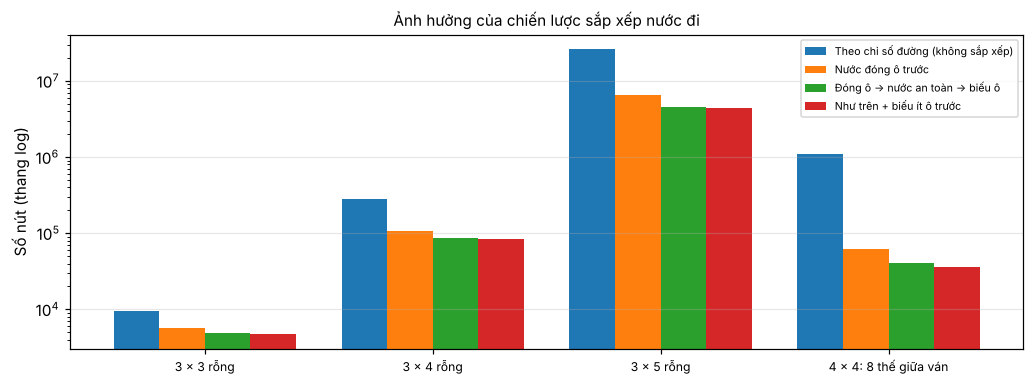

In [20]:
# Your code/ answer goes here.

ORDERINGS = [("natural", True, "Theo chỉ số đường (không sắp xếp)"), ("captures", True, "Nước đóng ô trước"), ("safe", True, "Đóng ô → nước an toàn → biếu ô"),
             ("sacrifice", True, "Như trên + biếu ít ô trước"), ("natural", False, "Không sắp xếp, KHÔNG bảng chuyển vị"), ("safe", False, "Đóng ô → an toàn → biếu ô, KHÔNG bảng chuyển vị")]
ORDER_BOARDS = [(3, 3), (3, 4), (3, 5)]        # bàn rỗng
ORDER_LIMIT = 150          # giây tối đa cho mỗi lần chạy
ORDER_NO_TT = [(3, 3)]          # các bàn nhỏ mà ta còn thử không-bảng-chuyển-vị
ORDER_MID = ((4, 4), 9, 8)              # (cỡ bàn, số đường đã vẽ, số thế cờ giữa ván)
order_rows, order_data = [], {}
def run_order(size, lines, ordering, use_tt):
    s = ExactSolver(size, ordering, use_tt, time_limit = ORDER_LIMIT, max_tt = 8_000_000)
    t0 = time.perf_counter()
    try:
        v, done = s.solve(lines), True
    except TimeUp:
        v, done = None, False
    return dict(nodes = s.nodes, time = time.perf_counter() - t0, tt = len(s.tt), done = done, value = v)

for size in ORDER_BOARDS:
    for ordering, use_tt, label in ORDERINGS:
        if not use_tt and size not in ORDER_NO_TT:
            continue
        r = run_order(size, 0, ordering, use_tt)
        order_data[(size, ordering, use_tt)] = r
        order_rows.append({"Bàn rỗng": f"{size[0]} × {size[1]}", "Chiến lược": label, "Số nút": f"{r['nodes']:,}" + ("" if r["done"] else " (dừng)"),
                           "Thời gian (s)": round(r["time"], 2) if r["done"] else f"> {ORDER_LIMIT}", "Mục bảng chuyển vị": f"{r['tt']:,}" if use_tt else "–"})
# thế cờ giữa ván (ngẫu nhiên, cố định bởi seed) trên bàn lớn hơn
mid_size, mid_drawn, mid_n = ORDER_MID
rng_m = random.Random(11)
mid_positions = []
while len(mid_positions) < mid_n:
    b = random_position(mid_size, mid_drawn, rng_m)
    mid_positions.append(geom(mid_size).mask(b))
for ordering, use_tt, label in ORDERINGS:
    if not use_tt:
        continue
    rs = [run_order(mid_size, m, ordering, use_tt) for m in mid_positions]
    order_data[("mid", ordering, use_tt)] = dict(nodes = sum(r["nodes"] for r in rs), time = sum(r["time"] for r in rs), done = all(r["done"] for r in rs))
    order_rows.append({"Bàn rỗng": f"{mid_size[0]} × {mid_size[1]}, {mid_n} thế cờ giữa ván ({mid_drawn} đường đã vẽ)", "Chiến lược": label,
                       "Số nút": f"{order_data[('mid', ordering, use_tt)]['nodes']:,}" + ("" if order_data[('mid', ordering, use_tt)]["done"] else " (dừng)"),
                       "Thời gian (s)": round(order_data[('mid', ordering, use_tt)]["time"], 2), "Mục bảng chuyển vị": "–"})
order_table = pd.DataFrame(order_rows)
display(order_table)

groups = list(dict.fromkeys(order_table["Bàn rỗng"]))
fig, ax = plt.subplots(figsize = (9.5, 3.6), dpi = 110)
labels_ = [l for o, t, l in ORDERINGS if t]
for j, (ordering, use_tt, label) in enumerate([x for x in ORDERINGS if x[1]]):
    ys = []
    for size in ORDER_BOARDS:
        ys.append(order_data[(size, ordering, True)]["nodes"])
    ys.append(order_data[("mid", ordering, True)]["nodes"])
    ax.bar(np.arange(len(ys)) + (j - 1.5) * 0.2, ys, 0.2, label = label)
ax.set_yscale("log"); ax.set_xticks(np.arange(len(ORDER_BOARDS) + 1))
ax.set_xticklabels([f"{s[0]} × {s[1]} rỗng" for s in ORDER_BOARDS] + [f"{mid_size[0]} × {mid_size[1]}: {mid_n} thế giữa ván"], fontsize = 8)
ax.set_ylabel("Số nút (thang log)"); ax.legend(fontsize = 7); ax.grid(alpha = .3, axis = "y"); ax.set_title("Ảnh hưởng của chiến lược sắp xếp nước đi", fontsize = 10)
plt.tight_layout(); plt.show()

In [21]:
def nd(size, ordering, tt = True):
    return order_data[(size, ordering, tt)]
bs = ORDER_BOARDS[-1]                                           # bàn rỗng lớn nhất
mid_ = lambda o: order_data[("mid", o, True)]
no_tt = [s for s in ORDER_NO_TT if (s, "natural", False) in order_data]
bs_small = no_tt[-1] if no_tt else None
display(Markdown(f"""
**Nhận xét (mọi chiến lược cho cùng giá trị Minimax - đã kiểm chứng ở trên).**
* **Sắp xếp nước đi giảm mạnh số nút.** Trên bàn rỗng {bs[0]} × {bs[1]} chấm: không sắp xếp {nd(bs, 'natural')['nodes']:,} nút → đóng ô trước {nd(bs, 'captures')['nodes']:,} ({nd(bs, 'natural')['nodes'] / nd(bs, 'captures')['nodes']:.1f}× ít hơn) → thêm nước an toàn trước {nd(bs, 'safe')['nodes']:,} ({nd(bs, 'natural')['nodes'] / nd(bs, 'safe')['nodes']:.1f}× ít hơn so với không sắp xếp; {nd(bs, 'natural')['time'] / max(nd(bs, 'safe')['time'], 1e-3):.1f}× nhanh hơn). Trên {mid_n} thế cờ giữa ván của bàn {mid_size[0]} × {mid_size[1]}: {mid_('natural')['nodes']:,} → {mid_('captures')['nodes']:,} → {mid_('safe')['nodes']:,} → {mid_('sacrifice')['nodes']:,} nút (không sắp xếp → đóng ô trước → thêm nước an toàn → thêm biếu ít ô trước){'' if mid_('safe')['nodes'] <= mid_('captures')['nodes'] else '; ở các thế cờ này bước "nước an toàn" không giảm thêm mà còn tăng nhẹ - thứ tự chỉ là heuristic nên hiệu quả phụ thuộc thế cờ'}.
* **Phần lớn lợi ích đến từ hai ý tưởng rất đơn giản** (đóng ô trước, tránh biếu ô). Thêm "biếu ít ô trước" chỉ thay đổi nhỏ ({nd(bs, 'safe')['nodes']:,} → {nd(bs, 'sacrifice')['nodes']:,} nút, {100 * (1 - nd(bs, 'sacrifice')['nodes'] / nd(bs, 'safe')['nodes']):+.1f} %), vì khi đã xét hết nước an toàn thì thứ tự giữa các nước biếu ô ít quan trọng hơn.
* **Bảng chuyển vị** còn quan trọng hơn thứ tự nước đi{(': trên bàn ' + str(bs_small[0]) + ' × ' + str(bs_small[1]) + ' chấm, bỏ bảng chuyển vị làm số nút tăng từ ' + format(nd(bs_small, 'safe')['nodes'], ',') + ' lên ' + format(nd(bs_small, 'safe', False)['nodes'], ',') + ' (' + format(nd(bs_small, 'safe', False)['nodes'] / nd(bs_small, 'safe')['nodes'], '.0f') + ' lần) ngay cả khi vẫn sắp xếp nước đi tốt; không sắp xếp và cũng không bảng chuyển vị thì cần ' + format(nd(bs_small, 'natural', False)['nodes'], ',') + ' nút') if bs_small else ''}. Lý do đã nêu ở Task 1: cây có cỡ L! nút nhưng chỉ có ≈ 2^L thế cờ khác nhau.
* Hai kỹ thuật bổ sung cho nhau: sắp xếp nước đi làm *mỗi nhánh* bị cắt sớm hơn, bảng chuyển vị làm *các nhánh trùng nhau* chỉ phải tính một lần.
"""))


**Nhận xét (mọi chiến lược cho cùng giá trị Minimax - đã kiểm chứng ở trên).**
* **Sắp xếp nước đi giảm mạnh số nút.** Trên bàn rỗng 3 × 5 chấm: không sắp xếp 26,115,395 nút → đóng ô trước 6,538,310 (4.0× ít hơn) → thêm nước an toàn trước 4,487,880 (5.8× ít hơn so với không sắp xếp; 3.9× nhanh hơn). Trên 8 thế cờ giữa ván của bàn 4 × 4: 1,088,283 → 61,944 → 41,213 → 35,574 nút (không sắp xếp → đóng ô trước → thêm nước an toàn → thêm biếu ít ô trước).
* **Phần lớn lợi ích đến từ hai ý tưởng rất đơn giản** (đóng ô trước, tránh biếu ô). Thêm "biếu ít ô trước" chỉ thay đổi nhỏ (4,487,880 → 4,439,999 nút, +1.1 %), vì khi đã xét hết nước an toàn thì thứ tự giữa các nước biếu ô ít quan trọng hơn.
* **Bảng chuyển vị** còn quan trọng hơn thứ tự nước đi: trên bàn 3 × 3 chấm, bỏ bảng chuyển vị làm số nút tăng từ 4,961 lên 157,369 (32 lần) ngay cả khi vẫn sắp xếp nước đi tốt; không sắp xếp và cũng không bảng chuyển vị thì cần 871,816 nút. Lý do đã nêu ở Task 1: cây có cỡ L! nút nhưng chỉ có ≈ 2^L thế cờ khác nhau.
* Hai kỹ thuật bổ sung cho nhau: sắp xếp nước đi làm *mỗi nhánh* bị cắt sớm hơn, bảng chuyển vị làm *các nhánh trùng nhau* chỉ phải tính một lần.


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

,Bàn (chấm),Số nước đầu tiên,Số lớp tương đương (đối xứng),Thời gian tính mọi nước (s),Thời gian chỉ tính đại diện mỗi lớp (s),Hai cách cho cùng giá trị,Giá trị nước đầu tốt nhất
0,3 × 3,12,2,0.02,0.01,True,2
1,3 × 4,17,6,0.49,0.31,True,-2
2,4 × 4,24,4,30.68,16.95,True,-3


Nước đầu tiên theo sách khai cuộc trên bàn 4 × 4: ('h', 0, 0) - mất 70 µs.


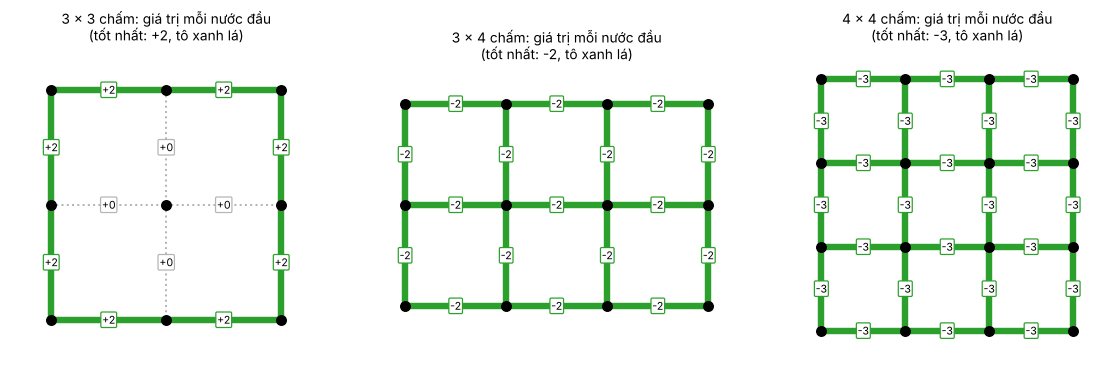

In [22]:
# Your code/ answer goes here.

# ---- Những nước đầu tiên ----
# (1) Đối xứng: bàn cờ không đổi khi lật dọc / lật ngang (và chuyển vị nếu là bàn vuông) nên nhiều nước đầu tương đương nhau -
#     chỉ cần tính giá trị của MỘT nước trong mỗi lớp tương đương.
def symmetries(size):
    """Các phép đối xứng của bàn cờ dưới dạng hoán vị chỉ số đường (gồm phép đồng nhất)."""
    R, C = size
    dots = [(r, c) for r in range(R) for c in range(C)]
    idx = {d: i for i, d in enumerate(dots)}
    gens = [lambda r, c: (R - 1 - r, c), lambda r, c: (r, C - 1 - c)] + ([lambda r, c: (c, r)] if R == C else [])
    gens = [tuple(idx[f(r, c)] for r, c in dots) for f in gens]
    group, frontier = {tuple(range(len(dots)))}, [tuple(range(len(dots)))]
    while frontier:                                            # bao đóng của nhóm sinh bởi gens
        p = frontier.pop()
        for gnr in gens:
            q = tuple(gnr[i] for i in p)
            if q not in group:
                group.add(q); frontier.append(q)
    g = geom(size)
    def line_ends(l):
        o, r, c = g.lines[l]
        return ((r, c), (r, c + 1)) if o == "h" else ((r, c), (r + 1, c))
    def line_from(a, b):
        (r0, c0), (r1, c1) = sorted([a, b])
        return ("h", r0, c0) if r0 == r1 else ("v", r0, c0)
    maps = []
    for p in group:
        m = []
        for l in range(g.L):
            a, b = line_ends(l)
            m.append(g.index[line_from(dots[p[idx[a]]], dots[p[idx[b]]])])
        maps.append(m)
    return maps

def line_orbits(size):
    """Các lớp tương đương của nước đi đầu tiên (mỗi lớp là danh sách chỉ số đường)."""
    maps, seen, orbits = symmetries(size), set(), []
    for l in range(geom(size).L):
        if l not in seen:
            orb = sorted({m[l] for m in maps})
            seen.update(orb); orbits.append(orb)
    return orbits

FIRST_SIZES = [(3, 3), (3, 4), (4, 4)]
first_rows, first_data = [], {}
for size in FIRST_SIZES:
    g = geom(size); orbits = line_orbits(size); reps = [o[0] for o in orbits]
    s_all = ExactSolver(size, "safe"); t0 = time.perf_counter()
    vals_all = s_all.action_values(0) if g.L <= 24 else None            # mọi nước đầu tiên (bỏ qua đối xứng)
    t_all = time.perf_counter() - t0 if vals_all is not None else None
    s_rep = ExactSolver(size, "safe"); t0 = time.perf_counter()
    vals_rep = s_rep.action_values(0, only = set(reps)); t_rep = time.perf_counter() - t0
    consistent = None if vals_all is None else all(vals_all[l] == vals_rep[o[0]] for o in orbits for l in o)
    best_v = max(vals_rep.values())
    first_data[size] = dict(orbits = orbits, vals_rep = vals_rep, vals_all = vals_all, best = best_v, t_all = t_all, t_rep = t_rep, nodes_rep = s_rep.nodes, consistent = consistent,
                            best_lines = [g.lines[l] for o in orbits for l in o if vals_rep[o[0]] == best_v], solver = s_rep)
    first_rows.append({"Bàn (chấm)": f"{size[0]} × {size[1]}", "Số nước đầu tiên": g.L, "Số lớp tương đương (đối xứng)": len(orbits),
                       "Thời gian tính mọi nước (s)": round(t_all, 2) if t_all is not None else "–", "Thời gian chỉ tính đại diện mỗi lớp (s)": round(t_rep, 2),
                       "Hai cách cho cùng giá trị": "–" if consistent is None else consistent, "Giá trị nước đầu tốt nhất": best_v})
display(pd.DataFrame(first_rows))

# (2) Sách khai cuộc: tính trước (offline) nước đầu tốt nhất, lúc chơi chỉ tra bảng.
OPENING_BOOK = {size: geom(size).lines[min(first_data[size]["orbits"][i][0] for i in range(len(first_data[size]["orbits"]))
                                           if first_data[size]["vals_rep"][first_data[size]["orbits"][i][0]] == first_data[size]["best"])] for size in FIRST_SIZES}

class OpeningBookPlayer(AlphaBetaPlayer):
    """Alpha-Beta + sách khai cuộc: ở bàn rỗng tra bảng (≈ 0 giây), còn lại tìm kiếm bình thường (có dùng lại bảng chuyển vị)."""
    def __init__(self, book, **kw):
        super().__init__(**kw); self.book, self.name = book, "Alpha-Beta + sách khai cuộc"
    def __call__(self, board, player = None):
        if not board["lines"] and board["size"] in self.book:
            return self.book[board["size"]]
        return super().__call__(board, player)

t0 = time.perf_counter(); book_move = OpeningBookPlayer(OPENING_BOOK)(new_board(*FIRST_SIZES[-1]), 1); t_book = time.perf_counter() - t0
print(f"Nước đầu tiên theo sách khai cuộc trên bàn {FIRST_SIZES[-1][0]} × {FIRST_SIZES[-1][1]}: {book_move} - mất {t_book * 1e6:.0f} µs.")

# Giá trị của từng nước đầu tiên trên bàn lớn nhất đã tính
size_ = FIRST_SIZES[-1]; fd = first_data[size_]; g_ = geom(size_)
vals_line = {g_.lines[l]: fd["vals_rep"][o[0]] for o in fd["orbits"] for l in o}
fig, axes = plt.subplots(1, len(FIRST_SIZES), figsize = (3.6 * len(FIRST_SIZES), 3.4), dpi = 110)
for ax, size in zip(np.atleast_1d(axes), FIRST_SIZES):
    g = geom(size); fd = first_data[size]
    vl = {g.lines[l]: fd["vals_rep"][o[0]] for o in fd["orbits"] for l in o}
    draw_board(new_board(*size), ax = ax, values = vl, mark = {a: "#2ca02c" for a in fd["best_lines"]}, fontsize = 8,
               title = f"{size[0]} × {size[1]} chấm: giá trị mỗi nước đầu\n(tốt nhất: {fd['best']:+d}, tô xanh lá)")
plt.tight_layout(); plt.show()

In [23]:
sz = FIRST_SIZES[-1]; fd = first_data[sz]
n_cls = len(fd["orbits"])
rows_ = [(s, d) for s, d in first_data.items() if d["t_all"] is not None]
val_list = ", ".join(f"{s[0]} × {s[1]}: {d['best']:+d}" for s, d in first_data.items())
all_best = [s for s, d in first_data.items() if len(d["best_lines"]) == geom(s).L]
display(Markdown(f"""
**Bàn rỗng là trường hợp khó nhất** vì chưa có đường nào tạo ra cắt nhánh sớm: Alpha-Beta phải chứng minh giá trị của *mọi* nước đầu tiên. Ở phần trên, bàn rỗng {sz[0]} × {sz[1]} chấm mất {size_info[sz]['time']:.1f} s và {size_info[sz]['nodes']:,} nút, trong khi một nước ở giữa ván chỉ mất vài mili-giây. Những cách xử lý:
1. **Bảng chuyển vị dùng lại giữa các nước (đã dùng ở trên).** Bộ giải là một đối tượng giữ bảng: sau khi tính nước đầu, mọi thế cờ mà nó đã duyệt không phải tính lại ở các nước sau. Vì vậy `AlphaBetaPlayer` chỉ "đắt" ở nước đầu tiên của bàn đó (xem Playtime bên dưới).
2. **Đối xứng ở gốc.** Bàn {sz[0]} × {sz[1]} chấm có {geom(sz).L} nước đầu tiên nhưng chỉ **{n_cls} lớp tương đương** do lật/xoay{' (bảng trên kiểm tra: giá trị của mọi nước trong cùng một lớp bằng nhau)' if all(d['consistent'] for d in first_data.values() if d['consistent'] is not None) else ''}. Chỉ tính một đại diện mỗi lớp: {', '.join(f"bàn {s[0]} × {s[1]}: {d['t_all']:.2f} s → {d['t_rep']:.2f} s ({d['t_all'] / max(d['t_rep'], 1e-3):.1f}× nhanh hơn)" for s, d in rows_)}.
3. **Sách khai cuộc.** Nước đầu tiên chỉ phụ thuộc vào kích thước bàn nên có thể **tính sẵn một lần (offline)** rồi tra bảng: chọn nước đầu trên bàn {sz[0]} × {sz[1]} chấm mất ≈ {t_book * 1e6:.0f} µs thay vì {fd['t_rep']:.1f} s. Giá trị của nước đầu tốt nhất theo kích thước: {val_list} (người đi trước, hai bên tối ưu).
4. **Với bàn quá lớn để giải** (như 5 × 5 chấm): không còn cách tính chính xác, nên thay vì tìm tới cuối ván ta **cắt độ sâu và dùng hàm heuristic** (Task 4), hoặc ước lượng bằng mô phỏng (Pure Monte Carlo, phần nâng cao).

**Nước đầu tiên nào tốt?** {('Ở mọi bàn đã giải, ' if len(all_best) == len(first_data) else '')}hình trên ghi giá trị của từng nước đầu: nước tốt nhất có giá trị {fd['best']:+d} và có {len(fd['best_lines'])}/{geom(sz).L} đường đạt giá trị này ở bàn {sz[0]} × {sz[1]} chấm{'' if len(fd['best_lines']) < geom(sz).L else ' - tức là **mọi nước đầu đều có cùng giá trị lý thuyết**, nước đầu không quyết định kết quả. Điều này hợp lý: ở giai đoạn đầu mọi nước đều "an toàn" (chưa tạo ô 3 cạnh) và người thắng được quyết định về sau, bởi chẵn/lẻ số nước an toàn còn lại - tức là ai phải mở dây đầu tiên'}.
"""))


**Bàn rỗng là trường hợp khó nhất** vì chưa có đường nào tạo ra cắt nhánh sớm: Alpha-Beta phải chứng minh giá trị của *mọi* nước đầu tiên. Ở phần trên, bàn rỗng 4 × 4 chấm mất 20.9 s và 8,919,784 nút, trong khi một nước ở giữa ván chỉ mất vài mili-giây. Những cách xử lý:
1. **Bảng chuyển vị dùng lại giữa các nước (đã dùng ở trên).** Bộ giải là một đối tượng giữ bảng: sau khi tính nước đầu, mọi thế cờ mà nó đã duyệt không phải tính lại ở các nước sau. Vì vậy `AlphaBetaPlayer` chỉ "đắt" ở nước đầu tiên của bàn đó (xem Playtime bên dưới).
2. **Đối xứng ở gốc.** Bàn 4 × 4 chấm có 24 nước đầu tiên nhưng chỉ **4 lớp tương đương** do lật/xoay (bảng trên kiểm tra: giá trị của mọi nước trong cùng một lớp bằng nhau). Chỉ tính một đại diện mỗi lớp: bàn 3 × 3: 0.02 s → 0.01 s (3.1× nhanh hơn), bàn 3 × 4: 0.49 s → 0.31 s (1.6× nhanh hơn), bàn 4 × 4: 30.68 s → 16.95 s (1.8× nhanh hơn).
3. **Sách khai cuộc.** Nước đầu tiên chỉ phụ thuộc vào kích thước bàn nên có thể **tính sẵn một lần (offline)** rồi tra bảng: chọn nước đầu trên bàn 4 × 4 chấm mất ≈ 70 µs thay vì 16.9 s. Giá trị của nước đầu tốt nhất theo kích thước: 3 × 3: +2, 3 × 4: -2, 4 × 4: -3 (người đi trước, hai bên tối ưu).
4. **Với bàn quá lớn để giải** (như 5 × 5 chấm): không còn cách tính chính xác, nên thay vì tìm tới cuối ván ta **cắt độ sâu và dùng hàm heuristic** (Task 4), hoặc ước lượng bằng mô phỏng (Pure Monte Carlo, phần nâng cao).

**Nước đầu tiên nào tốt?** hình trên ghi giá trị của từng nước đầu: nước tốt nhất có giá trị -3 và có 24/24 đường đạt giá trị này ở bàn 4 × 4 chấm - tức là **mọi nước đầu đều có cùng giá trị lý thuyết**, nước đầu không quyết định kết quả. Điều này hợp lý: ở giai đoạn đầu mọi nước đều "an toàn" (chưa tạo ô 3 cạnh) và người thắng được quyết định về sau, bởi chẵn/lẻ số nước an toàn còn lại - tức là ai phải mở dây đầu tiên.


### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [24]:
# Your code/ answer goes here.

# ---- Alpha-Beta chính xác đấu với Random (và với agent tham lam) ----
PLAY_SETUP = [((3, 3), 100), ((3, 4), 100), ((4, 4), 30)]             # [(cỡ bàn, số ván mỗi vai)]
play_rows, play_data = [], {}
for size, n in PLAY_SETUP:
    ab = AlphaBetaPlayer()                                               # một agent cho cả hai vai: bảng chuyển vị được dùng lại
    t_solve = time.perf_counter()
    value0 = ab.solver(size).solve() if n_lines(size) <= 24 else None    # giá trị lý thuyết của người đi trước (cũng làm đầy bảng chuyển vị của agent)
    t_solve = time.perf_counter() - t_solve                              # thời gian giải bàn rỗng - tính RIÊNG, không nằm trong ms/nước
    for opp_name, make_opp in (("Random", lambda: random_player), ("Tham lam", lambda: GreedyPlayer(seed = 5))):
        for role in (1, -1):
            opp = make_opp()
            random.seed(100 + role)
            games = [play(ab, opp, size) if role == 1 else play(opp, ab, size) for _ in range(n)]
            wins = sum(g["winner"] == role for g in games); losses = sum(g["winner"] == -role for g in games); draws = n - wins - losses
            ms = [1000 * (g["t1"] if role == 1 else g["t2"]) / (g["n1"] if role == 1 else g["n2"]) for g in games]
            first_ms = 1000 * (games[0]["t1"] if role == 1 else games[0]["t2"]) / (games[0]["n1"] if role == 1 else games[0]["n2"])
            play_data[(size, opp_name, role)] = dict(wins = wins, draws = draws, losses = losses, n = n, margin = float(np.mean([g["margin"] * role for g in games])), ms = float(np.mean(ms)), value0 = value0, t_solve = t_solve)
            play_rows.append({"Bàn (chấm)": f"{size[0]} × {size[1]}", "Giá trị lý thuyết (người đi trước)": "–" if value0 is None else f"{value0:+d}", "Đối thủ": opp_name,
                              "Alpha-Beta đi": "trước" if role == 1 else "sau", "Số ván": n, "Thắng": wins, "Hòa": draws, "Thua": losses, "% thắng": round(100 * wins / n),
                              "Hiệu số ô TB": round(play_data[(size, opp_name, role)]["margin"], 2), "ms/nước TB": round(play_data[(size, opp_name, role)]["ms"], 2)})
display(pd.DataFrame(play_rows))

,Bàn (chấm),Giá trị lý thuyết (người đi trước),Đối thủ,Alpha-Beta đi,Số ván,Thắng,Hòa,Thua,% thắng,Hiệu số ô TB,ms/nước TB
0,3 × 3,+2,Random,trước,100,100,0,0,100,3.86,0.02
1,3 × 3,+2,Random,sau,100,64,34,2,64,1.70,0.04
2,3 × 3,+2,Tham lam,trước,100,100,0,0,100,3.08,0.02
3,3 × 3,+2,Tham lam,sau,100,21,64,15,21,0.52,0.03
4,3 × 4,-2,Random,trước,100,95,4,1,95,3.62,0.09
5,3 × 4,-2,Random,sau,100,100,0,0,100,5.80,0.25
6,3 × 4,-2,Tham lam,trước,100,78,14,8,78,1.76,0.05
7,3 × 4,-2,Tham lam,sau,100,100,0,0,100,4.62,0.07
8,4 × 4,-3,Random,trước,30,30,0,0,100,7.33,2.14
9,4 × 4,-3,Random,sau,30,30,0,0,100,8.60,16.81


In [25]:
def adv(d, role):
    """Alpha-Beta có lợi thế lý thuyết ở vai này không? (None nếu không biết)"""
    if d["value0"] is None:
        return None
    return (d["value0"] > 0) if role == 1 else (d["value0"] < 0)
rows_ = [(k, d) for k, d in play_data.items()]
with_adv = [(k, d) for k, d in rows_ if adv(d, k[2]) is True]
no_adv = [(k, d) for k, d in rows_ if adv(d, k[2]) is False and d["value0"] != 0]
lost_adv = sum(d["losses"] for k, d in with_adv)
rand_ = [(k, d) for k, d in rows_ if k[1] == "Random"]; greedy_ = [(k, d) for k, d in rows_ if k[1] == "Tham lam"]
win_rand = sum(d["wins"] for k, d in rand_) / sum(d["n"] for k, d in rand_)
win_gr = sum(d["wins"] for k, d in greedy_) / sum(d["n"] for k, d in greedy_)
adv_rand = [(k, d) for k, d in with_adv if k[1] == "Random"]; dis_rand = [(k, d) for k, d in no_adv if k[1] == "Random"]
display(Markdown(f"""
**Phân tích** ({sum(d['n'] for k, d in rows_)} ván tất cả).
* **Khi có lợi thế lý thuyết, Alpha-Beta không thể thua:** ở {len(with_adv)} cấu hình (bàn, vai, đối thủ) mà thế cờ đầu là thắng cho Alpha-Beta, tổng số ván thua là **{lost_adv}** trên {sum(d['n'] for k, d in with_adv)} ván - đúng như kỳ vọng vì tìm kiếm đi tới cuối ván nên nó giữ được giá trị tối ưu ở mọi nước.{'' if not adv_rand else ' Trước Random, tỷ lệ thắng ở các cấu hình này là ' + ', '.join(f"{100 * d['wins'] / d['n']:.0f} % ({k[0][0]} × {k[0][1]}, đi {'trước' if k[2] == 1 else 'sau'})" for k, d in adv_rand) + '.'}
* **Khi bất lợi về lý thuyết** (thế cờ đầu là thua nếu đối thủ chơi tối ưu), Alpha-Beta vẫn có thể thắng vì Random mắc sai lầm{'' if not dis_rand else ': ' + ', '.join(f"{100 * d['wins'] / d['n']:.0f} % thắng / {100 * d['losses'] / d['n']:.0f} % thua ({k[0][0]} × {k[0][1]}, đi {'trước' if k[2] == 1 else 'sau'})" for k, d in dis_rand)}. Minimax giả sử đối thủ chơi tối ưu nên chỉ cố hạn chế mức thua trong trường hợp xấu nhất; nó không "đặt bẫy" để tăng khả năng đối thủ yếu mắc sai lầm - đây là hạn chế của giá trị Minimax so với việc tối đa hóa xác suất thắng trước một đối thủ cụ thể.
* **Hòa:** chỉ xảy ra ở bàn có số ô chẵn (3 × 3 chấm: 4 ô; 3 × 4 chấm: 6 ô); ở bàn 4 × 4 chấm (9 ô) không thể hòa.
* **So với đối thủ:** Alpha-Beta thắng Random {100 * win_rand:.0f} % và thắng agent tham lam {100 * win_gr:.0f} % số ván (tính cả hai vai); agent tham lam là đối thủ khó hơn Random vì nó không biếu ô vô cớ.
* **Thời gian:** {', '.join(f"{k[0][0]} × {k[0][1]}: {d['ms']:.2f} ms/nước" for k, d in rows_ if k[1] == 'Random' and k[2] == 1)} (trung bình mỗi nước khi đi trước trước Random). Con số **không gồm** lần giải bàn rỗng ban đầu - làm một lần cho mỗi cỡ bàn và để lại bảng chuyển vị cho các ván sau: {', '.join(f"{k[0][0]} × {k[0][1]}: {d['t_solve']:.2f} s" for k, d in rows_ if k[1] == 'Random' and k[2] == 1 and d['value0'] is not None)}.
"""))


**Phân tích** (920 ván tất cả).
* **Khi có lợi thế lý thuyết, Alpha-Beta không thể thua:** ở 6 cấu hình (bàn, vai, đối thủ) mà thế cờ đầu là thắng cho Alpha-Beta, tổng số ván thua là **0** trên 460 ván - đúng như kỳ vọng vì tìm kiếm đi tới cuối ván nên nó giữ được giá trị tối ưu ở mọi nước. Trước Random, tỷ lệ thắng ở các cấu hình này là 100 % (3 × 3, đi trước), 100 % (3 × 4, đi sau), 100 % (4 × 4, đi sau).
* **Khi bất lợi về lý thuyết** (thế cờ đầu là thua nếu đối thủ chơi tối ưu), Alpha-Beta vẫn có thể thắng vì Random mắc sai lầm: 64 % thắng / 2 % thua (3 × 3, đi sau), 95 % thắng / 1 % thua (3 × 4, đi trước), 100 % thắng / 0 % thua (4 × 4, đi trước). Minimax giả sử đối thủ chơi tối ưu nên chỉ cố hạn chế mức thua trong trường hợp xấu nhất; nó không "đặt bẫy" để tăng khả năng đối thủ yếu mắc sai lầm - đây là hạn chế của giá trị Minimax so với việc tối đa hóa xác suất thắng trước một đối thủ cụ thể.
* **Hòa:** chỉ xảy ra ở bàn có số ô chẵn (3 × 3 chấm: 4 ô; 3 × 4 chấm: 6 ô); ở bàn 4 × 4 chấm (9 ô) không thể hòa.
* **So với đối thủ:** Alpha-Beta thắng Random 91 % và thắng agent tham lam 78 % số ván (tính cả hai vai); agent tham lam là đối thủ khó hơn Random vì nó không biếu ô vô cớ.
* **Thời gian:** 3 × 3: 0.02 ms/nước, 3 × 4: 0.09 ms/nước, 4 × 4: 2.14 ms/nước (trung bình mỗi nước khi đi trước trước Random). Con số **không gồm** lần giải bàn rỗng ban đầu - làm một lần cho mỗi cỡ bàn và để lại bảng chuyển vị cho các ván sau: 3 × 3: 0.01 s, 3 × 4: 0.16 s, 4 × 4: 20.29 s.


## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

**Thiết kế hàm đánh giá.** Khi tìm kiếm bị cắt ở độ sâu giới hạn, thế cờ ở nút lá thường chưa kết thúc và cần một con số thay cho giá trị Minimax thật. Ta dùng **cùng đơn vị với Minimax** (số ô, nhìn từ người sắp đi):

> h(thế cờ) ≈ (số ô người sắp đi sẽ thu thêm) − (số ô đối thủ sẽ thu thêm)

nên h có thể cộng thẳng với số ô đã đóng được dọc theo nhánh tìm kiếm. Ba ý tưởng chiến thuật được thêm dần vào, cho ra bốn hàm để so sánh:

| Hàm | Công thức | Ý nghĩa |
|---|---|---|
| **H0** | h = 0 | đối chứng: chỉ tính các ô đã đóng thật trong phạm vi tìm kiếm |
| **H1** | h = *g* | *g* = số ô người sắp đi **đóng được ngay** (đóng liên tiếp cả chuỗi ô đang có 3 cạnh) |
| **H2** | h = *g* ± *w* | thêm **chẵn/lẻ số nước an toàn**: +*w* nếu còn một số *lẻ* nước an toàn (người sắp đi sẽ đi nước an toàn *cuối cùng*, đối thủ phải biếu ô trước), −*w* nếu số đó *chẵn* (kể cả 0) |
| **H3** | như H2, nhưng khi **hết nước an toàn** thì h = *g* − *k* | *k* = số ô ít nhất mà đối thủ đóng được sau nước biếu rẻ nhất |

*Nước an toàn* là nước không tạo ra ô có 3 cạnh (không biếu ô). Người bị buộc phải mở chuỗi dài đầu tiên thường thua (quy tắc chuỗi dài của Berlekamp), nên chẵn/lẻ số nước an toàn còn lại là tín hiệu có ích. Ta đếm bằng cách đi liên tiếp các nước an toàn theo thứ tự chỉ số đường cho tới khi hết (một dãy cực đại), với trọng số *w* = 1. Đây chỉ là **xấp xỉ**: người chơi có thể chọn nước làm mất hai nước an toàn cùng lúc để đổi chẵn/lẻ. Giá trị luôn được kẹp trong [−*r*, *r*] với *r* là số ô chưa đóng, vì không ai thu được nhiều hơn số ô còn lại.

In [26]:
# Your code/ answer goes here.

# ---- Hàm đánh giá heuristic h(g, lines): nhìn từ NGƯỜI SẮP ĐI, đơn vị = số ô ----
def count_done(g, lines):
    """Số ô đã đóng đủ 4 cạnh."""
    return sum(1 for m in g.box_mask if lines & m == m)

def free_captures(g, lines):
    """Người sắp đi đóng liên tiếp mọi ô đang có đúng 3 cạnh (kể cả cả một chuỗi). Trả về (số ô đóng được, thế cờ sau khi đóng)."""
    gained, changed = 0, True
    while changed:
        changed = False
        for m in g.box_mask:
            x = lines & m
            if x != m and popcount(x) == 3:
                lines |= m; gained += 1; changed = True
    return gained, lines

def is_safe(g, lines, l):
    """Vẽ đường l (chưa vẽ) có tránh được việc tạo ô 3 cạnh không? True = nước an toàn."""
    nl = lines | (1 << l)
    return all(popcount(nl & m) < 3 for m in g.adj[l])

def safe_run(g, lines):
    """Số nước an toàn đi được liên tiếp: duyệt các đường theo chỉ số và vẽ đường nào còn an toàn (một dãy cực đại)."""
    n = 0
    for l in range(g.L):
        if not (lines >> l) & 1 and is_safe(g, lines, l):
            lines |= 1 << l; n += 1
    return n

def cheapest_sacrifice(g, lines):
    """Số ô ít nhất mà đối thủ đóng được ngay sau MỘT nước đi của người sắp đi (dùng khi đã hết nước an toàn)."""
    best = g.B
    for l in range(g.L):
        if not (lines >> l) & 1:
            best = min(best, free_captures(g, lines | (1 << l))[0])
    return best

def make_heuristic(kind, w = 1.0):
    """kind = 0, 1, 2, 3 ứng với H0..H3 (xem bảng ở trên); w = trọng số của chẵn/lẻ nước an toàn."""
    def h(g, lines):
        if kind == 0:
            return 0
        gain, after = free_captures(g, lines)
        if kind == 1 or after == g.full:
            v = gain
        else:
            s = safe_run(g, after)
            if kind == 3 and s == 0:
                v = gain - cheapest_sacrifice(g, after)
            else:
                v = gain + (w if s % 2 else -w)
        r = g.B - count_done(g, lines)
        return max(-r, min(r, v))
    return h

HEURISTICS = {"H0": make_heuristic(0), "H1": make_heuristic(1), "H2": make_heuristic(2), "H3": make_heuristic(3)}
HEUR_DESC = {"H0": "h = 0 (đối chứng)", "H1": "ô đóng được ngay", "H2": "H1 ± chẵn/lẻ số nước an toàn", "H3": "H2 + chi phí biếu rẻ nhất khi hết nước an toàn"}

# Ví dụ: giá trị của bốn hàm trên 4 bàn thử của Task 3, đặt cạnh giá trị Minimax chính xác của thế cờ
demo_rows = []
for tb in TEST_BOARDS:
    g_ = geom(tb["size"]); lines_ = g_.mask(board_from_lines(tb["size"], tb["lines"]))
    row = {"Bàn thử": tb["name"], "Giá trị chính xác": ExactSolver(tb["size"]).solve(lines_)}
    row.update({k: h(g_, lines_) for k, h in HEURISTICS.items()})
    demo_rows.append(row)
display(pd.DataFrame(demo_rows))

,Bàn thử,Giá trị chính xác,H0,H1,H2,H3
0,1. Đóng ô miễn phí,5,0,5,5.0,5.0
1,2. Nhường ô (double-dealing),1,0,2,1.0,-1.0
2,3. Nước an toàn đúng lượt,4,0,0,-1.0,-1.0
3,4. Hy sinh để thắng,2,0,0,-1.0,-1.0


,Hàm,Ý nghĩa,Hệ số tương quan với giá trị chính xác,Sai số tuyệt đối TB (ô),Đúng dấu (% thế cờ có người thắng)
0,H0,h = 0 (đối chứng),–,3.85,0.0
1,H1,ô đóng được ngay,0.53,2.76,32.3
2,H2,H1 ± chẵn/lẻ số nước an toàn,0.556,2.65,62.1
3,H3,H2 + chi phí biếu rẻ nhất khi hết nước an toàn,0.673,2.18,65.7


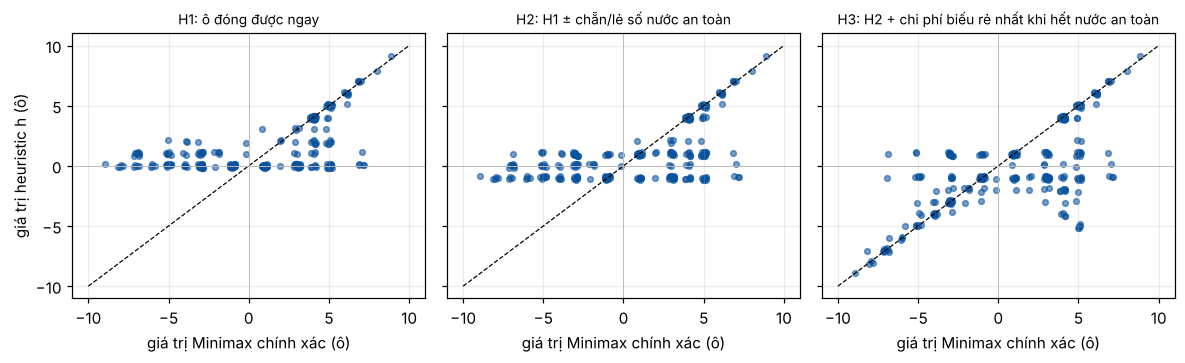

In [27]:
# ---- Hàm heuristic ước lượng tốt đến đâu? So với giá trị Minimax CHÍNH XÁC trên các thế cờ giữa ván ----
HEUR_SIZE, HEUR_POS = (4, 4), 250

def sample_positions(size, n, lo, hi, seed, quiet = True):
    """n thế cờ 'điển hình' giữa ván. Cho hai người chơi 'hợp lý' (đóng ô nếu được; nếu không thì vẽ một nước an toàn ngẫu nhiên; hết nước an toàn thì biếu ít ô nhất) tự đấu;
    mỗi ván lấy ngẫu nhiên MỘT thế cờ có lo..hi đường đã vẽ. quiet = True: chỉ lấy thế cờ mà người đi chưa có ô nào đóng được ngay (để quyết định không tầm thường)."""
    g, rng, out = geom(size), random.Random(seed), []
    while len(out) < n:
        lines, cands = 0, []
        while lines != g.full:
            free = [l for l in range(g.L) if not (lines >> l) & 1]
            caps = [l for l in free if any((lines | (1 << l)) & m == m for m in g.adj[l])]
            if (not quiet or not caps) and lo <= popcount(lines) <= hi:
                cands.append(lines)
            if caps:
                l = rng.choice(caps)
            else:
                safe = [l for l in free if is_safe(g, lines, l)]
                l = rng.choice(safe) if safe else min(free, key = lambda x: (free_captures(g, lines | (1 << x))[0], rng.random()))
            lines |= 1 << l
        if cands:
            out.append(rng.choice(cands))
    return out

g_main = geom(HEUR_SIZE)
ex_main = ExactSolver(HEUR_SIZE)
# (a) Thế cờ "tĩnh" (có thể có ô đóng được ngay) để kiểm tra h có ước lượng đúng giá trị Minimax không
static_pos = sample_positions(HEUR_SIZE, HEUR_POS, 6, 20, seed = 11, quiet = False)
t0 = time.perf_counter()
exact_val = np.array([ex_main.solve(p) for p in static_pos], dtype = float)
# (b) Thế cờ "quyết định" (người đi chưa có ô nào đóng ngay) để kiểm tra việc CHỌN NƯỚC ĐI ở phần sau; cần giá trị chính xác của MỌI nước
positions = sample_positions(HEUR_SIZE, HEUR_POS, 6, 18, seed = 21)
exact_av = [ex_main.action_values(p) for p in positions]
t_exact = time.perf_counter() - t0
n_hard = sum(max(av.values()) != min(av.values()) for av in exact_av)         # số thế cờ mà các nước đi KHÔNG cùng giá trị (chọn sai là mất ô)
n_free = sum(any(h_ > 0 for h_ in [HEURISTICS["H1"](g_main, p)]) for p in static_pos)       # số thế cờ tĩnh mà người đi có ô đóng được ngay

rows, hv = [], {}
for name, h in HEURISTICS.items():
    hv[name] = np.array([h(g_main, p) for p in static_pos], dtype = float)
    nz = exact_val != 0
    rows.append({"Hàm": name, "Ý nghĩa": HEUR_DESC[name],
                 "Hệ số tương quan với giá trị chính xác": round(float(np.corrcoef(hv[name], exact_val)[0, 1]), 3) if hv[name].std() > 0 else "–",
                 "Sai số tuyệt đối TB (ô)": round(float(np.abs(hv[name] - exact_val).mean()), 2),
                 "Đúng dấu (% thế cờ có người thắng)": round(100 * float((np.sign(hv[name][nz]) == np.sign(exact_val[nz])).mean()), 1)})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize = (11, 3.4), dpi = 110, sharex = True, sharey = True)
jit = np.random.default_rng(0).uniform(-0.18, 0.18, size = (2, len(static_pos)))
for ax, name in zip(axes, ["H1", "H2", "H3"]):
    ax.scatter(exact_val + jit[0], hv[name] + jit[1], s = 14, alpha = 0.55, color = "#08519c")
    lim = int(max(np.abs(exact_val).max(), np.abs(hv[name]).max())) + 1
    ax.plot([-lim, lim], [-lim, lim], "k--", lw = 0.8); ax.axhline(0, color = "#bbb", lw = 0.6); ax.axvline(0, color = "#bbb", lw = 0.6)
    ax.set_title(f"{name}: {HEUR_DESC[name]}", fontsize = 9); ax.set_xlabel("giá trị Minimax chính xác (ô)"); ax.grid(alpha = .25)
axes[0].set_ylabel("giá trị heuristic h (ô)")
plt.tight_layout(); plt.show()

In [28]:
r_ = {k: float(np.corrcoef(hv[k], exact_val)[0, 1]) if hv[k].std() > 0 else float("nan") for k in ["H1", "H2", "H3"]}
mae_ = {k: float(np.abs(hv[k] - exact_val).mean()) for k in HEURISTICS}
best_r = max((k for k in r_ if r_[k] == r_[k]), key = r_.get)
display(Markdown(f"""
**Nhận xét.** Ta so sánh h với giá trị Minimax **chính xác** (tính bằng Alpha-Beta tới cuối ván, Task 3) trên {len(static_pos)} thế cờ giữa ván của bàn {HEUR_SIZE[0]} × {HEUR_SIZE[1]} chấm (có {min(popcount(p) for p in static_pos)}-{max(popcount(p) for p in static_pos)} đường đã vẽ; {n_free} thế cờ có ô đóng được ngay). Ngoài ra ta chuẩn bị {len(positions)} thế cờ "quyết định" (người đi chưa có ô nào đóng ngay) và giá trị chính xác của mọi nước đi ở đó, dùng cho phần chọn nước bên dưới; ở {n_hard}/{len(positions)} thế cờ này các nước đi **không** cùng giá trị nên chọn sai là mất ô. Tính toàn bộ nghiệm chính xác mất {t_exact:.1f} s.
* **H0 không mang thông tin:** sai số tuyệt đối trung bình {mae_['H0']:.2f} ô chính là độ lớn trung bình của giá trị chính xác.
* **H1 (ô đóng được ngay)** có tương quan r = {r_['H1']:.2f} và sai số {mae_['H1']:.2f} ô; **H2** (thêm chẵn/lẻ nước an toàn) có r = {r_['H2']:.2f} và sai số {mae_['H2']:.2f}; **H3** (thêm chi phí biếu rẻ nhất) có r = {r_['H3']:.2f} và sai số {mae_['H3']:.2f}. Hàm có tương quan cao nhất là **{best_r}**.
* {'Mỗi thành phần thêm vào đều làm hàm ước lượng sát hơn.' if r_['H1'] < r_['H2'] < r_['H3'] else 'Không phải thành phần nào thêm vào cũng làm hàm sát hơn theo hệ số tương quan - xem thêm phần thử nghiệm chọn nước đi bên dưới, vì ta quan tâm chọn đúng nước hơn là ước lượng đúng giá trị.'}
* Điểm yếu chung (xem hình): ở những thế cờ còn nhiều nước an toàn, giá trị chính xác phụ thuộc vào ai phải mở chuỗi đầu tiên - thứ mà chẵn/lẻ chỉ xấp xỉ - nên h thường lệch vài ô, và khoảng lệch này chính là lý do tìm kiếm cần đi sâu thêm thay vì tin hoàn toàn vào h.
"""))


**Nhận xét.** Ta so sánh h với giá trị Minimax **chính xác** (tính bằng Alpha-Beta tới cuối ván, Task 3) trên 250 thế cờ giữa ván của bàn 4 × 4 chấm (có 6-20 đường đã vẽ; 112 thế cờ có ô đóng được ngay). Ngoài ra ta chuẩn bị 250 thế cờ "quyết định" (người đi chưa có ô nào đóng ngay) và giá trị chính xác của mọi nước đi ở đó, dùng cho phần chọn nước bên dưới; ở 217/250 thế cờ này các nước đi **không** cùng giá trị nên chọn sai là mất ô. Tính toàn bộ nghiệm chính xác mất 11.5 s.
* **H0 không mang thông tin:** sai số tuyệt đối trung bình 3.85 ô chính là độ lớn trung bình của giá trị chính xác.
* **H1 (ô đóng được ngay)** có tương quan r = 0.53 và sai số 2.76 ô; **H2** (thêm chẵn/lẻ nước an toàn) có r = 0.56 và sai số 2.65; **H3** (thêm chi phí biếu rẻ nhất) có r = 0.67 và sai số 2.18. Hàm có tương quan cao nhất là **H3**.
* Mỗi thành phần thêm vào đều làm hàm ước lượng sát hơn.
* Điểm yếu chung (xem hình): ở những thế cờ còn nhiều nước an toàn, giá trị chính xác phụ thuộc vào ai phải mở chuỗi đầu tiên - thứ mà chẵn/lẻ chỉ xấp xỉ - nên h thường lệch vài ô, và khoảng lệch này chính là lý do tìm kiếm cần đi sâu thêm thay vì tin hoàn toàn vào h.


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

**Cài đặt.** `CutoffSolver` kế thừa `ExactSolver` của Task 3 (cùng sắp xếp nước đi, cùng bảng chuyển vị, cùng quy ước "đóng ô thì đi tiếp") và chỉ thay đổi hai điều: (1) hàm tìm kiếm có thêm tham số *d* = số đường còn được phép vẽ; (2) khi *d* = 0 mà ván chưa kết thúc thì trả về **h(thế cờ)** thay vì tiếp tục. *Độ sâu* được tính bằng số **đường vẽ** (một nước đóng ô cũng tính là một nước). Hai chi tiết cần lưu ý:
* Trong **một** lần tìm kiếm, *d* của một thế cờ được xác định hoàn toàn bởi thế cờ đó (mỗi nước vẽ đúng một đường), nên bảng chuyển vị chỉ cần khóa theo `lines`; ta xóa bảng trước mỗi lần chọn nước để số nút đo được là chi phí thật của một nước đi.
* Khi *d* ≥ số đường còn lại, h không bao giờ được gọi và `CutoffSolver` cho đúng giá trị Minimax (kiểm tra bên dưới).

**Thí nghiệm.** Với mỗi hàm heuristic và mỗi độ sâu cắt, ta cho agent chọn nước ở từng thế cờ mẫu (khi có nhiều nước cùng giá trị thì chọn ngẫu nhiên) và đo **độ hối tiếc** = (giá trị chính xác của nước tốt nhất) − (giá trị chính xác của nước đã chọn), đơn vị là ô; bằng 0 nghĩa là chọn nước tối ưu.

In [29]:
# Your code/ answer goes here.

# ---- Alpha-Beta cắt độ sâu + hàm heuristic ----
class CutoffSolver(ExactSolver):
    """ExactSolver + cắt độ sâu: dsearch(lines, d, alpha, beta) đi tối đa d đường rồi trả về h(thế cờ)."""
    def __init__(self, size, depth, heuristic, ordering = "safe", time_limit = None):
        assert depth >= 1
        super().__init__(size, ordering, True, time_limit)
        self.depth, self.h = depth, heuristic

    def dsearch(self, lines, d, alpha, beta):
        self.nodes += 1
        if self.nodes & 8191 == 0:
            self.check()
        g = self.g
        if lines == g.full:
            return 0
        if d == 0:                                      # cắt: dùng heuristic thay cho giá trị thật
            return self.h(g, lines)
        e = self.tt.get(lines)
        if e is not None:
            flag, val = e                               # 0 chính xác, 1 cận dưới, 2 cận trên (giá trị có thể là số thực)
            if flag == 0:
                return val
            if flag == 1:
                if val >= beta:
                    return val
                alpha = max(alpha, val)
            else:
                if val <= alpha:
                    return val
                beta = min(beta, val)
            if alpha >= beta:
                return val
        a0, best = alpha, -99
        for l, gain in self.moves(lines):
            nl = lines | (1 << l)
            v = gain + self.dsearch(nl, d - 1, alpha - gain, beta - gain) if gain else -self.dsearch(nl, d - 1, -beta, -alpha)
            if v > best:
                best = v
                if v > alpha:
                    alpha = v
                    if alpha >= beta:
                        break
        self.tt[lines] = (2 if best <= a0 else (1 if best >= beta else 0), best)
        return best

    def best_move(self, lines, rng = None):
        """(chỉ số đường, giá trị) của nước tốt nhất sau khi tìm `depth` đường. Nhiều nước cùng giá trị: chọn nước đầu tiên theo thứ tự duyệt, hoặc ngẫu nhiên nếu có `rng`."""
        self.nodes = 0; self.tt.clear(); self._start()
        eps, best_v, cand = 1e-6, -99, []
        for l, gain in self.moves(lines):
            nl = lines | (1 << l)
            lo = best_v - 2 * eps if rng is not None else best_v         # có rng: nới cửa sổ một chút để nhận ra chính xác các nước hòa
            v = gain + self.dsearch(nl, self.depth - 1, lo - gain, 99 - gain) if gain else -self.dsearch(nl, self.depth - 1, -99, -lo)
            if v > best_v + eps:
                best_v, cand = v, [l]
            elif rng is not None and abs(v - best_v) < eps:
                cand.append(l)
        return (rng.choice(cand) if rng is not None else cand[0]), best_v

class CutoffPlayer:
    """Agent Alpha-Beta cắt độ sâu `depth` với hàm heuristic `heuristic` (tên trong HEURISTICS). Không dùng ngẫu nhiên (trừ khi cho `seed`) nên mỗi cặp agent chỉ có một ván."""
    def __init__(self, depth, heuristic = "H3", name = None, seed = None):
        self.depth, self.hname, self.h = depth, heuristic, HEURISTICS[heuristic]
        self.rng = random.Random(seed) if seed is not None else None
        self.name = name or f"{heuristic}, độ sâu {depth}"
        self.solvers, self.last_nodes, self.last_value = {}, 0, None

    def __call__(self, board, player = None):
        size = board["size"]
        if size not in self.solvers:
            self.solvers[size] = CutoffSolver(size, self.depth, self.h)
        s = self.solvers[size]
        l, v = s.best_move(s.g.mask(board), self.rng)
        self.last_nodes, self.last_value = s.nodes, v
        return s.g.lines[l]

# Kiểm tra: khi độ sâu >= số đường còn lại thì CutoffSolver cho đúng giá trị Minimax (với mọi hàm heuristic)
late = sample_positions(HEUR_SIZE, 12, 15, 19, seed = 5)
for hname, h in HEURISTICS.items():
    for p in late:
        _, v = CutoffSolver(HEUR_SIZE, g_main.L - popcount(p), h).best_move(p)
        assert v == ExactSolver(HEUR_SIZE).solve(p), (hname, p)
print(f"OK: với độ sâu = số đường còn lại, CutoffSolver cho đúng giá trị Minimax trên {len(late)} thế cờ x 4 hàm heuristic.")

OK: với độ sâu = số đường còn lại, CutoffSolver cho đúng giá trị Minimax trên 12 thế cờ x 4 hàm heuristic.


Độ hối tiếc trung bình ± sai số chuẩn (ô; càng nhỏ càng tốt):


,H0,H1,H2,H3
độ sâu,,,,
1,3.43 ± 0.23,1.74 ± 0.15,1.65 ± 0.14,1.61 ± 0.14
2,2.32 ± 0.19,1.76 ± 0.15,1.89 ± 0.14,1.72 ± 0.13
3,1.92 ± 0.16,1.66 ± 0.14,1.64 ± 0.14,1.62 ± 0.14
4,1.66 ± 0.14,1.59 ± 0.13,1.30 ± 0.13,1.36 ± 0.13
5,1.75 ± 0.14,1.47 ± 0.13,1.34 ± 0.13,1.26 ± 0.12
6,1.62 ± 0.13,1.48 ± 0.14,1.32 ± 0.13,1.02 ± 0.10
7,1.49 ± 0.13,1.27 ± 0.13,1.18 ± 0.12,0.78 ± 0.09
8,1.34 ± 0.13,1.28 ± 0.12,0.90 ± 0.10,0.49 ± 0.07
9,1.28 ± 0.13,0.94 ± 0.10,0.85 ± 0.10,0.44 ± 0.06


Tỷ lệ nước đi tối ưu:


,H0,H1,H2,H3
độ sâu,,,,
1,33 %,54 %,55 %,56 %
2,46 %,53 %,45 %,46 %
3,51 %,54 %,52 %,54 %
4,54 %,52 %,62 %,62 %
5,50 %,59 %,61 %,60 %
6,52 %,58 %,63 %,65 %
7,58 %,62 %,64 %,73 %
8,61 %,60 %,69 %,82 %
9,62 %,68 %,72 %,82 %


Chi phí mỗi nước (trung bình số nút | mili-giây):


,H0: nút | ms,H3: nút | ms
độ sâu,,
1,14 | 0.0,14 | 0.2
2,124 | 0.1,132 | 1.3
3,269 | 0.5,334 | 2.7
4,639 | 1.3,856 | 6.6
5,"1,302 | 2.5","1,773 | 12.2"
6,"2,246 | 4.2","3,142 | 21.0"
7,"3,465 | 7.1","5,106 | 37.7"
8,"5,059 | 11.8","7,272 | 49.3"
9,"7,221 | 17.2","9,567 | 55.4"


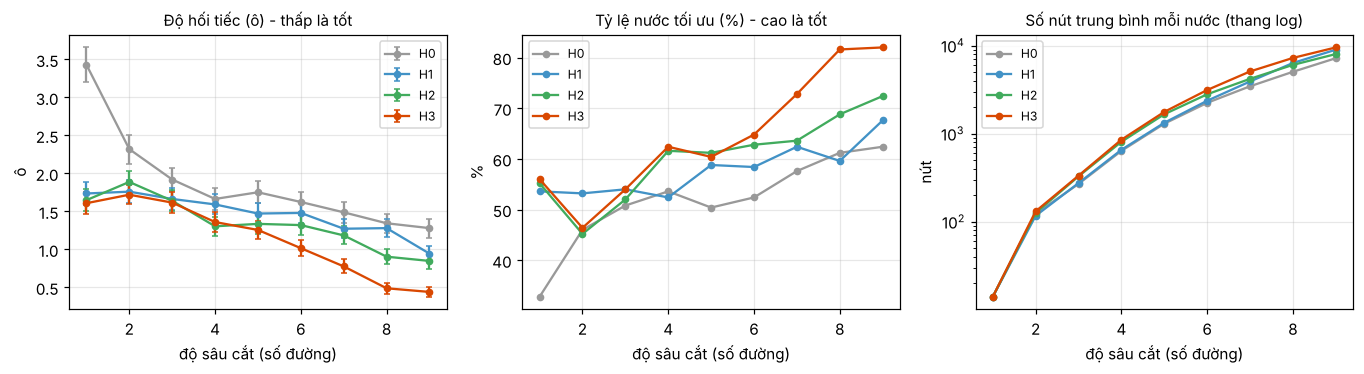

In [30]:
# ---- Độ hối tiếc theo hàm heuristic và độ sâu cắt (so với nghiệm chính xác ở trên) ----
CUT_DEPTHS = [1, 2, 3, 4, 5, 6, 7, 8, 9]
cut_res = {}
for hname, h in HEURISTICS.items():
    for d in CUT_DEPTHS:
        rng = random.Random(0); reg, nodes, secs = [], [], []
        for p, av in zip(positions, exact_av):
            s = CutoffSolver(HEUR_SIZE, d, h)
            t0 = time.perf_counter(); l, _ = s.best_move(p, rng); secs.append(time.perf_counter() - t0)
            reg.append(max(av.values()) - av[l]); nodes.append(s.nodes)
        cut_res[(hname, d)] = dict(regret = np.array(reg, dtype = float), nodes = np.array(nodes, dtype = float), sec = np.array(secs))

def se(x):
    return float(np.std(x, ddof = 1) / np.sqrt(len(x)))
tab_regret = pd.DataFrame({h: [f"{cut_res[(h, d)]['regret'].mean():.2f} ± {se(cut_res[(h, d)]['regret']):.2f}" for d in CUT_DEPTHS] for h in HEURISTICS}, index = pd.Index(CUT_DEPTHS, name = "độ sâu"))
tab_opt = pd.DataFrame({h: [f"{100 * (cut_res[(h, d)]['regret'] == 0).mean():.0f} %" for d in CUT_DEPTHS] for h in HEURISTICS}, index = pd.Index(CUT_DEPTHS, name = "độ sâu"))
tab_cost = pd.DataFrame({f"{h}: nút | ms": [f"{cut_res[(h, d)]['nodes'].mean():,.0f} | {1000 * cut_res[(h, d)]['sec'].mean():.1f}" for d in CUT_DEPTHS] for h in ["H0", "H3"]}, index = pd.Index(CUT_DEPTHS, name = "độ sâu"))
print("Độ hối tiếc trung bình ± sai số chuẩn (ô; càng nhỏ càng tốt):"); display(tab_regret)
print("Tỷ lệ nước đi tối ưu:"); display(tab_opt)
print("Chi phí mỗi nước (trung bình số nút | mili-giây):"); display(tab_cost)

colors = {"H0": "#999999", "H1": "#4292c6", "H2": "#41ab5d", "H3": "#d94801"}
fig, axes = plt.subplots(1, 3, figsize = (12.5, 3.5), dpi = 110)
for h in HEURISTICS:
    axes[0].errorbar(CUT_DEPTHS, [cut_res[(h, d)]["regret"].mean() for d in CUT_DEPTHS], yerr = [se(cut_res[(h, d)]["regret"]) for d in CUT_DEPTHS], marker = "o", ms = 4, capsize = 2, color = colors[h], label = h)
    axes[1].plot(CUT_DEPTHS, [100 * (cut_res[(h, d)]["regret"] == 0).mean() for d in CUT_DEPTHS], "o-", ms = 4, color = colors[h], label = h)
    axes[2].semilogy(CUT_DEPTHS, [cut_res[(h, d)]["nodes"].mean() for d in CUT_DEPTHS], "o-", ms = 4, color = colors[h], label = h)
for ax, t, yl in zip(axes, ["Độ hối tiếc (ô) - thấp là tốt", "Tỷ lệ nước tối ưu (%) - cao là tốt", "Số nút trung bình mỗi nước (thang log)"], ["ô", "%", "nút"]):
    ax.set_title(t, fontsize = 10); ax.set_xlabel("độ sâu cắt (số đường)"); ax.set_ylabel(yl); ax.grid(alpha = .3); ax.legend(fontsize = 8)
plt.tight_layout(); plt.show()

In [31]:
def mean_regret(h, d):
    return cut_res[(h, d)]["regret"].mean()
dmax, dmin = max(CUT_DEPTHS), min(CUT_DEPTHS)
best_hd = min(cut_res, key = lambda k: mean_regret(*k))
d_ref = CUT_DEPTHS[len(CUT_DEPTHS) // 2]
def paired(h1, h0, d):
    """Hiệu độ hối tiếc h1 - h0 trên cùng các thế cờ: (trung bình, khoảng tin cậy 95 % xấp xỉ chuẩn)."""
    x = cut_res[(h1, d)]["regret"] - cut_res[(h0, d)]["regret"]
    return x.mean(), 1.96 * se(x)
m3, c3 = paired("H3", "H0", dmax); m1, c1 = paired("H1", "H0", dmin)
growth = np.exp(np.mean(np.diff(np.log([cut_res[("H3", d)]["nodes"].mean() for d in CUT_DEPTHS])))) if len(CUT_DEPTHS) > 1 else float("nan")
per_node = {h: cut_res[(h, dmax)]["sec"].sum() / cut_res[(h, dmax)]["nodes"].sum() for h in ("H0", "H3")}               # giây trên mỗi nút ở độ sâu lớn nhất
mono = {h: all(mean_regret(h, b) <= mean_regret(h, a) + 1e-9 for a, b in zip(CUT_DEPTHS, CUT_DEPTHS[1:])) for h in HEURISTICS}
display(Markdown(f"""
**Nhận xét** ({len(positions)} thế cờ, độ sâu {dmin}-{dmax}).
* **Hàm đánh giá quan trọng nhất khi cắt nông.** Ở độ sâu {dmin}, H0 hối tiếc trung bình {mean_regret('H0', dmin):.2f} ô còn H1 chỉ {mean_regret('H1', dmin):.2f} ô (hiệu H1 − H0 = {m1:+.2f} ± {c1:.2f}, khoảng tin cậy 95 % {'không chứa' if abs(m1) > c1 else 'chứa'} 0): chỉ riêng việc biết "có ô đóng được ngay" đã {'giúp ích rõ' if m1 < -c1 else 'không tạo khác biệt rõ ràng'}.
* **Ở độ sâu {dmax}**, hối tiếc của H0, H1, H2, H3 lần lượt là {mean_regret('H0', dmax):.2f}, {mean_regret('H1', dmax):.2f}, {mean_regret('H2', dmax):.2f}, {mean_regret('H3', dmax):.2f} ô. H3 so với H0: {m3:+.2f} ± {c3:.2f} ô (khoảng tin cậy 95 % {'không chứa' if abs(m3) > c3 else 'chứa'} 0). Tổ hợp tốt nhất đo được là **{best_hd[0]} với độ sâu {best_hd[1]}** (hối tiếc {mean_regret(*best_hd):.2f} ô, {100 * (cut_res[best_hd]['regret'] == 0).mean():.0f} % nước tối ưu).
* **Độ sâu:** hối tiếc {'giảm đều' if all(mono.values()) else 'nhìn chung giảm nhưng không đơn điệu (ở một số hàm có chỗ tăng nhẹ khi thêm một đường; một phần là nhiễu mẫu, và dao động theo độ sâu cũng là hiện tượng thường gặp ở tìm kiếm cắt độ sâu vì h được áp dụng ở những thế cờ có bên đi khác nhau)'} khi tăng độ sâu. Ngay cả ở độ sâu {dmax}, hàm tốt nhất vẫn còn hối tiếc {min(mean_regret(h, dmax) for h in HEURISTICS):.2f} ô: các thế cờ mẫu còn {g_main.L - max(popcount(p) for p in positions)}-{g_main.L - min(popcount(p) for p in positions)} đường chưa vẽ, xa hơn nhiều so với độ sâu cắt, và nhiều quyết định (ai phải mở chuỗi đầu tiên) chỉ lộ ra ở cuối ván.
* **Chi phí:** mỗi đường tìm thêm nhân số nút lên khoảng {growth:.1f} lần (H3). Tìm kiếm cắt độ sâu {dmax} dùng trung bình {cut_res[('H3', dmax)]['nodes'].mean():,.0f} nút/nước ({1000 * cut_res[('H3', dmax)]['sec'].mean():.0f} ms), trong khi tìm kiếm chính xác từ thế cờ giữa ván tốn nhiều hơn rất nhiều (xem Task 3). Mỗi nút của H3 tốn khoảng {per_node['H3'] / per_node['H0']:.1f} lần thời gian so với H0 (hàm đánh giá phức tạp hơn, phải đếm nước an toàn và xét nước biếu).
* Hạn chế: các thế cờ mẫu lấy từ bàn {HEUR_SIZE[0]} × {HEUR_SIZE[1]} chấm và từ những ván "hợp lý" tự đấu, nên kết luận áp dụng cho kiểu thế cờ này; sai số chuẩn trong bảng cho thấy chênh lệch nhỏ giữa H2 và H3 có thể chỉ là nhiễu mẫu.
"""))


**Nhận xét** (250 thế cờ, độ sâu 1-9).
* **Hàm đánh giá quan trọng nhất khi cắt nông.** Ở độ sâu 1, H0 hối tiếc trung bình 3.43 ô còn H1 chỉ 1.74 ô (hiệu H1 − H0 = -1.70 ± 0.47, khoảng tin cậy 95 % không chứa 0): chỉ riêng việc biết "có ô đóng được ngay" đã giúp ích rõ.
* **Ở độ sâu 9**, hối tiếc của H0, H1, H2, H3 lần lượt là 1.28, 0.94, 0.85, 0.44 ô. H3 so với H0: -0.84 ± 0.23 ô (khoảng tin cậy 95 % không chứa 0). Tổ hợp tốt nhất đo được là **H3 với độ sâu 9** (hối tiếc 0.44 ô, 82 % nước tối ưu).
* **Độ sâu:** hối tiếc nhìn chung giảm nhưng không đơn điệu (ở một số hàm có chỗ tăng nhẹ khi thêm một đường; một phần là nhiễu mẫu, và dao động theo độ sâu cũng là hiện tượng thường gặp ở tìm kiếm cắt độ sâu vì h được áp dụng ở những thế cờ có bên đi khác nhau) khi tăng độ sâu. Ngay cả ở độ sâu 9, hàm tốt nhất vẫn còn hối tiếc 0.44 ô: các thế cờ mẫu còn 6-18 đường chưa vẽ, xa hơn nhiều so với độ sâu cắt, và nhiều quyết định (ai phải mở chuỗi đầu tiên) chỉ lộ ra ở cuối ván.
* **Chi phí:** mỗi đường tìm thêm nhân số nút lên khoảng 2.3 lần (H3). Tìm kiếm cắt độ sâu 9 dùng trung bình 9,567 nút/nước (55 ms), trong khi tìm kiếm chính xác từ thế cờ giữa ván tốn nhiều hơn rất nhiều (xem Task 3). Mỗi nút của H3 tốn khoảng 2.4 lần thời gian so với H0 (hàm đánh giá phức tạp hơn, phải đếm nước an toàn và xét nước biếu).
* Hạn chế: các thế cờ mẫu lấy từ bàn 4 × 4 chấm và từ những ván "hợp lý" tự đấu, nên kết luận áp dụng cho kiểu thế cờ này; sai số chuẩn trong bảng cho thấy chênh lệch nhỏ giữa H2 và H3 có thể chỉ là nhiễu mẫu.


How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

Nước đi đầu tiên (bàn rỗng - trường hợp rộng nhất) - H3, giới hạn 20 s mỗi nước:


,độ sâu 1,độ sâu 2,độ sâu 3,độ sâu 4,độ sâu 5
bàn,,,,,
4 × 4 chấm (24 đường),24 nút · 0.00 s,123 nút · 0.00 s,756 nút · 0.01 s,"2,166 nút · 0.02 s","10,348 nút · 0.09 s"
4 × 5 chấm (31 đường),31 nút · 0.00 s,178 nút · 0.00 s,"1,280 nút · 0.02 s","4,150 nút · 0.05 s","24,425 nút · 0.39 s"
4 × 6 chấm (38 đường),38 nút · 0.00 s,241 nút · 0.00 s,"1,943 nút · 0.03 s","7,020 nút · 0.12 s","47,202 nút · 0.77 s"
4 × 7 chấm (45 đường),45 nút · 0.00 s,312 nút · 0.01 s,"2,743 nút · 0.06 s","10,908 nút · 0.20 s","80,769 nút · 1.71 s"
4 × 8 chấm (52 đường),52 nút · 0.00 s,391 nút · 0.01 s,"3,681 nút · 0.09 s","15,911 nút · 0.32 s","127,295 nút · 3.14 s"


Giữa ván (trung bình 5 thế cờ, đã vẽ 25-45 % số đường) - H3, giới hạn 20 s mỗi nước:


,độ sâu 1,độ sâu 2,độ sâu 3,độ sâu 4,độ sâu 5
bàn,,,,,
4 × 4 chấm (24 đường),16 nút · 0.00 s,67 nút · 0.00 s,284 nút · 0.00 s,528 nút · 0.00 s,"1,207 nút · 0.01 s"
4 × 5 chấm (31 đường),20 nút · 0.00 s,92 nút · 0.00 s,355 nút · 0.00 s,693 nút · 0.01 s,"1,664 nút · 0.02 s"
4 × 6 chấm (38 đường),26 nút · 0.00 s,113 nút · 0.00 s,"1,120 nút · 0.02 s","3,064 nút · 0.04 s","17,005 nút · 0.20 s"
4 × 7 chấm (45 đường),29 nút · 0.00 s,152 nút · 0.00 s,812 nút · 0.02 s,"1,723 nút · 0.03 s","4,561 nút · 0.07 s"
4 × 8 chấm (52 đường),34 nút · 0.00 s,216 nút · 0.00 s,"1,819 nút · 0.03 s","3,049 nút · 0.05 s","15,271 nút · 0.25 s"


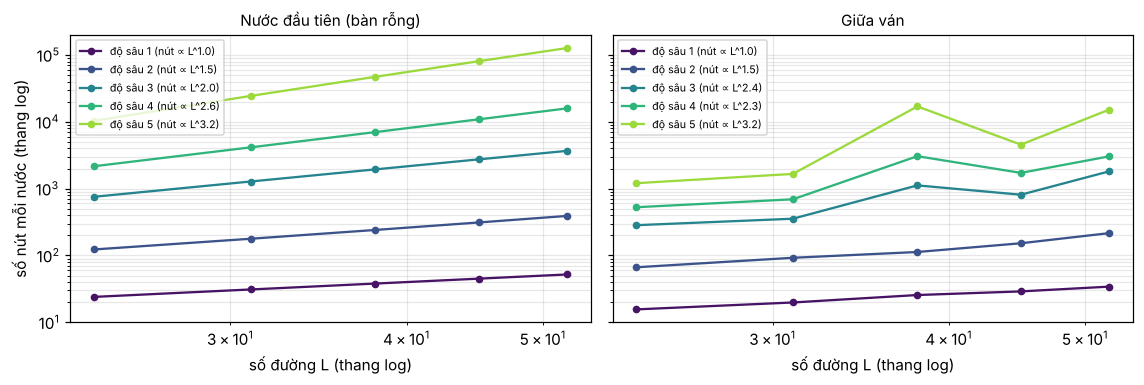

In [32]:
# Your code/ answer goes here.

# ---- Số nút và thời gian chọn một nước khi thêm cột: bàn 4 hàng chấm, 4, 5, 6, ... cột chấm ----
COLS_LIST, COLS_DEPTHS, COLS_LIMIT, COLS_MID, COLS_ROWS = [4, 5, 6, 7, 8], [1, 2, 3, 4, 5], 20, 5, 4
scale = {}                                                      # (số cột, độ sâu, 'first' | 'mid') -> (nút TB, giây TB) hoặc None nếu vượt giới hạn thời gian
for c in COLS_LIST:
    size = (COLS_ROWS, c); g = geom(size)
    mids = sample_positions(size, COLS_MID, g.L // 4, (9 * g.L) // 20, seed = 100 + c)        # thế cờ giữa ván: đã vẽ 25 % - 45 % số đường
    for d in COLS_DEPTHS:
        for kind, plist in (("first", [0]), ("mid", mids)):
            nodes, secs = [], []
            for p in plist:
                s = CutoffSolver(size, d, HEURISTICS["H3"], time_limit = COLS_LIMIT)
                t0 = time.perf_counter()
                try:
                    s.best_move(p)
                except TimeUp:
                    nodes = None; break
                secs.append(time.perf_counter() - t0); nodes.append(s.nodes)
            scale[(c, d, kind)] = (float(np.mean(nodes)), float(np.mean(secs))) if nodes else None
        if scale[(c, d, "first")] is None and scale[(c, d, "mid")] is None:             # quá giới hạn ở cả hai trường hợp: bỏ qua các độ sâu lớn hơn
            for d2 in COLS_DEPTHS:
                if d2 > d:
                    scale[(c, d2, "first")] = scale[(c, d2, "mid")] = None
            break

def cell(v):
    return "> %g s" % COLS_LIMIT if v is None else f"{v[0]:,.0f} nút · {v[1]:.2f} s"
for kind, title in (("first", "Nước đi đầu tiên (bàn rỗng - trường hợp rộng nhất)"), ("mid", f"Giữa ván (trung bình {COLS_MID} thế cờ, đã vẽ 25-45 % số đường)")):
    print(title + f" - H3, giới hạn {COLS_LIMIT} s mỗi nước:")
    display(pd.DataFrame({f"độ sâu {d}": [cell(scale.get((c, d, kind))) for c in COLS_LIST] for d in COLS_DEPTHS},
                         index = pd.Index([f"{COLS_ROWS} × {c} chấm ({n_lines((COLS_ROWS, c))} đường)" for c in COLS_LIST], name = "bàn")))

fits = {}
fig, axes = plt.subplots(1, 2, figsize = (10.5, 3.6), dpi = 110, sharey = True)
for ax, kind, title in zip(axes, ("first", "mid"), ("Nước đầu tiên (bàn rỗng)", "Giữa ván")):
    for d, col in zip(COLS_DEPTHS, plt.cm.viridis(np.linspace(0.05, 0.85, len(COLS_DEPTHS)))):
        pts = [(n_lines((COLS_ROWS, c)), scale[(c, d, kind)][0]) for c in COLS_LIST if scale.get((c, d, kind)) is not None]
        if len(pts) >= 2:
            slope = float(np.polyfit(np.log([p[0] for p in pts]), np.log([p[1] for p in pts]), 1)[0]); fits[(kind, d)] = slope
        ax.loglog([p[0] for p in pts], [p[1] for p in pts], "o-", ms = 4, color = col, label = f"độ sâu {d}" + (f" (nút ∝ L^{fits[(kind, d)]:.1f})" if (kind, d) in fits else ""))
    ax.set_title(title, fontsize = 10); ax.set_xlabel("số đường L (thang log)"); ax.grid(alpha = .3, which = "both"); ax.legend(fontsize = 7)
axes[0].set_ylabel("số nút mỗi nước (thang log)")
plt.tight_layout(); plt.show()

In [33]:
def feasible(kind, d):
    return [c for c in COLS_LIST if scale.get((c, d, kind)) is not None]
growth_txt = []
for d in COLS_DEPTHS:
    cs = feasible("first", d)
    if len(cs) >= 2:
        a, b = scale[(cs[0], d, "first")], scale[(cs[-1], d, "first")]
        growth_txt.append(f"độ sâu {d}: {cs[0]} → {cs[-1]} cột, {a[0]:,.0f} → {b[0]:,.0f} nút ({b[0] / a[0]:.1f} lần), {a[1]:.2f} → {b[1]:.2f} s")
slopes_ = {d: fits[("first", d)] for d in COLS_DEPTHS if ("first", d) in fits}
per_depth = []                                                   # hệ số nhân số nút khi tăng độ sâu thêm 1 (nước đầu tiên, mỗi bàn)
for c in COLS_LIST:
    for d in COLS_DEPTHS:
        a, b = scale.get((c, d, "first")), scale.get((c, d + 1, "first"))
        if a is not None and b is not None and a[0] > 0:
            per_depth.append(b[0] / a[0])
both = [(c, d) for c in COLS_LIST for d in COLS_DEPTHS if scale.get((c, d, "first")) is not None and scale.get((c, d, "mid")) is not None]
first_costlier = np.mean([scale[(c, d, "first")][0] > scale[(c, d, "mid")][0] for c, d in both]) if both else float("nan")
too_slow = sorted({d for c in COLS_LIST for d in COLS_DEPTHS if scale.get((c, d, "first")) is None and scale.get((c, d, "mid")) is None})
cmp_exact = ""
if (4, 4) in size_info and size_info[(4, 4)]["solved"] and 4 in COLS_LIST and scale.get((4, max(COLS_DEPTHS), "first")) is not None:
    e_ = size_info[(4, 4)]; s_ = scale[(4, max(COLS_DEPTHS), "first")]
    cmp_exact = f"* **So với tìm kiếm chính xác** (Task 3): giải bàn rỗng 4 × 4 chấm cần {e_['nodes']:,} nút / {e_['time']:.1f} s, còn cắt ở độ sâu {max(COLS_DEPTHS)} chỉ cần {s_[0]:,.0f} nút / {s_[1]:.2f} s để chọn nước đầu tiên (ít hơn {e_['nodes'] / s_[0]:,.0f} lần); ngược lại nước chọn ra không còn đảm bảo tối ưu."
display(Markdown(f"""
**Nhận xét** (H3, bàn {COLS_ROWS} hàng chấm, thêm dần cột; mọi số liệu đo trực tiếp trên các nước đi này).
* **Với độ sâu cố định, chi phí chỉ tăng theo đa thức của số đường L:** số nút khi tìm *d* đường bị chặn bởi L^d, và đo được xấp xỉ ∝ L^α với α ≈ {', '.join(f'{a:.1f} (độ sâu {d})' for d, a in slopes_.items()) if slopes_ else '(chưa đủ điểm để ước lượng)'} - khác hẳn tìm kiếm chính xác, nơi mỗi đường thêm nhân số nút lên khoảng 1,9 lần (Task 3). {'Thêm cột: ' + '; '.join(growth_txt) + '.' if growth_txt else ''}
* **Mỗi độ sâu thêm vào nhân số nút lên khoảng {np.exp(np.mean(np.log(per_depth))) if per_depth else float('nan'):.1f} lần** (trung bình hình học trên các bàn đo được; gần với số nước còn lại, giảm bớt nhờ cắt tỉa). {'Độ sâu ' + ', '.join(str(d) for d in too_slow) + ' vượt giới hạn ' + str(COLS_LIMIT) + ' s mỗi nước ở các bàn lớn (ô "> ' + str(COLS_LIMIT) + ' s" trong bảng).' if too_slow else 'Trong phạm vi thử, mọi cấu hình đều nằm trong giới hạn thời gian.'}
* **Nước đầu tiên và nước giữa ván:** nước đầu tiên (bàn rỗng) tốn nhiều nút hơn nước giữa ván trong {100 * first_costlier:.0f} % số cặp (bàn, độ sâu) đo được ở cả hai trường hợp; bàn rỗng có nhiều nước đi nhất và các nước đầu gần như ngang giá trị nên cắt tỉa kém hiệu quả.
{cmp_exact}
* Vì vậy muốn chơi trên bàn lớn hơn (như 5 × 5 chấm) ta chấp nhận cắt nông (độ sâu 3-4) hoặc cho nhiều thời gian hơn; đổi lại nước đi không còn đảm bảo tối ưu (xem phần hối tiếc ở trên).
"""))


**Nhận xét** (H3, bàn 4 hàng chấm, thêm dần cột; mọi số liệu đo trực tiếp trên các nước đi này).
* **Với độ sâu cố định, chi phí chỉ tăng theo đa thức của số đường L:** số nút khi tìm *d* đường bị chặn bởi L^d, và đo được xấp xỉ ∝ L^α với α ≈ 1.0 (độ sâu 1), 1.5 (độ sâu 2), 2.0 (độ sâu 3), 2.6 (độ sâu 4), 3.2 (độ sâu 5) - khác hẳn tìm kiếm chính xác, nơi mỗi đường thêm nhân số nút lên khoảng 1,9 lần (Task 3). Thêm cột: độ sâu 1: 4 → 8 cột, 24 → 52 nút (2.2 lần), 0.00 → 0.00 s; độ sâu 2: 4 → 8 cột, 123 → 391 nút (3.2 lần), 0.00 → 0.01 s; độ sâu 3: 4 → 8 cột, 756 → 3,681 nút (4.9 lần), 0.01 → 0.09 s; độ sâu 4: 4 → 8 cột, 2,166 → 15,911 nút (7.3 lần), 0.02 → 0.32 s; độ sâu 5: 4 → 8 cột, 10,348 → 127,295 nút (12.3 lần), 0.09 → 3.14 s.
* **Mỗi độ sâu thêm vào nhân số nút lên khoảng 5.8 lần** (trung bình hình học trên các bàn đo được; gần với số nước còn lại, giảm bớt nhờ cắt tỉa). Trong phạm vi thử, mọi cấu hình đều nằm trong giới hạn thời gian.
* **Nước đầu tiên và nước giữa ván:** nước đầu tiên (bàn rỗng) tốn nhiều nút hơn nước giữa ván trong 100 % số cặp (bàn, độ sâu) đo được ở cả hai trường hợp; bàn rỗng có nhiều nước đi nhất và các nước đầu gần như ngang giá trị nên cắt tỉa kém hiệu quả.
* **So với tìm kiếm chính xác** (Task 3): giải bàn rỗng 4 × 4 chấm cần 8,919,784 nút / 20.9 s, còn cắt ở độ sâu 5 chỉ cần 10,348 nút / 0.09 s để chọn nước đầu tiên (ít hơn 862 lần); ngược lại nước chọn ra không còn đảm bảo tối ưu.
* Vì vậy muốn chơi trên bàn lớn hơn (như 5 × 5 chấm) ta chấp nhận cắt nông (độ sâu 3-4) hoặc cho nhiều thời gian hơn; đổi lại nước đi không còn đảm bảo tối ưu (xem phần hối tiếc ở trên).


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

A = H3, độ sâu 4;  B = H1, độ sâu 2;  bàn 5 × 5 chấm (16 ô)


,Người đi trước,Ô của A,Ô của B,Kết quả,Số nước của A,ms/nước của A,Số nước của B,ms/nước của B
0,"A (H3, độ sâu 4)",9,7,A thắng,21,34.9,19,0.4
1,"B (H1, độ sâu 2)",9,7,A thắng,21,85.7,19,0.5


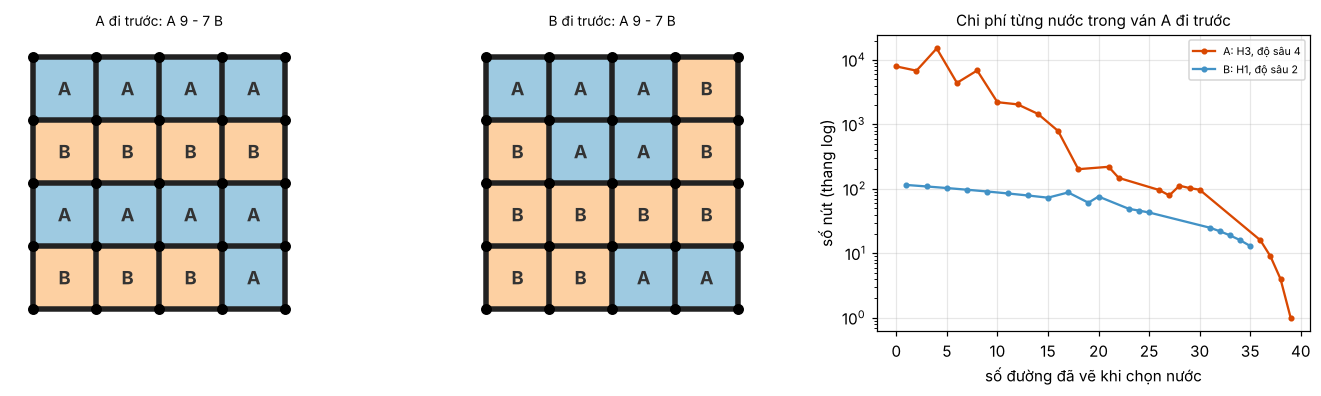

Vòng tròn trên bàn 4 × 4 chấm: mỗi cặp đấu hai ván (đổi vai), 30 ván trong 24 s.


,Agent,Thắng,Hòa,Thua,Tổng hiệu số ô
0,Chính xác (Task 3),10,0,0,32
1,"H2, d=3",7,0,3,6
2,"H3, d=5",6,0,4,10
3,"H1, d=2",4,0,6,-6
4,"H3, d=3",2,0,8,-14
5,"H0, d=2",1,0,9,-28


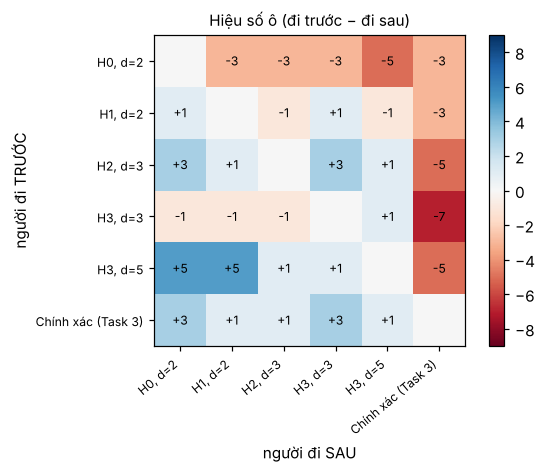

In [34]:
# Your code/ answer goes here.

# ---- Hai agent heuristic đấu với nhau (không có ngẫu nhiên nên mỗi vai chỉ cần một ván) ----
PLAY_SIZE = (5, 5)
A_SPEC, B_SPEC = ("H3", 4), ("H1", 2)            # (hàm heuristic, độ sâu cắt): khác cả hàm lẫn độ sâu
class Logged:
    """Bọc một agent để ghi lại (số đường đã vẽ, số nút, giây) của từng nước."""
    def __init__(self, agent):
        self.agent, self.name, self.log = agent, agent.name, []
    def __call__(self, board, player = None):
        t0 = time.perf_counter(); a = self.agent(board, player)
        self.log.append((len(board["lines"]), self.agent.last_nodes, time.perf_counter() - t0))
        return a

def boxes_of(game, who):
    return sum(1 for v in game["board"]["boxes"].values() if v == who)

duel = {}
for first in ("A", "B"):
    A, B = Logged(CutoffPlayer(A_SPEC[1], A_SPEC[0])), Logged(CutoffPlayer(B_SPEC[1], B_SPEC[0]))
    t0 = time.perf_counter()
    game = play(A, B, PLAY_SIZE) if first == "A" else play(B, A, PLAY_SIZE)
    duel[first] = dict(game = game, A = A, B = B, sec = time.perf_counter() - t0)

rows = []
for first, d in duel.items():
    g_, A, B = d["game"], d["A"], d["B"]
    a_box, b_box = (boxes_of(g_, 1), boxes_of(g_, -1)) if first == "A" else (boxes_of(g_, -1), boxes_of(g_, 1))
    d["a"], d["b"] = a_box, b_box
    rows.append({"Người đi trước": f"A ({A.name})" if first == "A" else f"B ({B.name})", "Ô của A": a_box, "Ô của B": b_box, "Kết quả": "A thắng" if a_box > b_box else ("B thắng" if b_box > a_box else "hòa"),
                 "Số nước của A": len(A.log), "ms/nước của A": round(1000 * sum(t for _, _, t in A.log) / len(A.log), 1), "Số nước của B": len(B.log), "ms/nước của B": round(1000 * sum(t for _, _, t in B.log) / len(B.log), 1)})
print(f"A = {duel['A']['A'].name};  B = {duel['A']['B'].name};  bàn {PLAY_SIZE[0]} × {PLAY_SIZE[1]} chấm ({n_boxes(PLAY_SIZE)} ô)")
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize = (12.5, 3.7), dpi = 110, gridspec_kw = dict(width_ratios = [1, 1, 1.15]))
for ax, first in zip(axes[:2], ("A", "B")):
    d = duel[first]
    draw_board(d["game"]["board"], ax = ax, fontsize = 8, title = f"{first} đi trước: A {d['a']} - {d['b']} B")
for who, col in (("A", "#d94801"), ("B", "#4292c6")):
    lg = duel["A"][who].log
    axes[2].semilogy([n for n, _, _ in lg], [max(nd, 1) for _, nd, _ in lg], "o-", ms = 3, color = col, label = f"{who}: {duel['A'][who].name}")
axes[2].set_xlabel("số đường đã vẽ khi chọn nước"); axes[2].set_ylabel("số nút (thang log)"); axes[2].set_title("Chi phí từng nước trong ván A đi trước", fontsize = 10); axes[2].grid(alpha = .3); axes[2].legend(fontsize = 7)
plt.tight_layout(); plt.show()

# ---- Giải đấu vòng tròn nhỏ trên bàn nhỏ hơn, có cả agent chính xác của Task 3 làm mốc ----
RR_SIZE, RR_SPECS = (4, 4), [("H0", 2), ("H1", 2), ("H2", 3), ("H3", 3), ("H3", 5)]
rr_agents = [(f"{h}, d={d}", CutoffPlayer(d, h)) for h, d in RR_SPECS] + [("Chính xác (Task 3)", AlphaBetaPlayer())]
nA = len(rr_agents)
rr = np.zeros((nA, nA)); rr_games = {}
t0 = time.perf_counter()
for i, (ni, ai) in enumerate(rr_agents):
    for j, (nj, aj) in enumerate(rr_agents):
        if i != j:
            g_ = play(ai, aj, RR_SIZE); rr_games[(i, j)] = g_; rr[i, j] = g_["margin"]          # hiệu số ô của i (đi trước) trừ j (đi sau)
t_rr = time.perf_counter() - t0
summary = []
for i, (ni, _) in enumerate(rr_agents):
    wins = sum(rr[i, j] > 0 for j in range(nA) if j != i) + sum(rr[j, i] < 0 for j in range(nA) if j != i)
    draws = sum(rr[i, j] == 0 for j in range(nA) if j != i) + sum(rr[j, i] == 0 for j in range(nA) if j != i)
    net = sum(rr[i, j] for j in range(nA) if j != i) - sum(rr[j, i] for j in range(nA) if j != i)
    summary.append({"Agent": ni, "Thắng": int(wins), "Hòa": int(draws), "Thua": int(2 * (nA - 1) - wins - draws), "Tổng hiệu số ô": int(net)})
rr_table = pd.DataFrame(summary).sort_values(["Thắng", "Tổng hiệu số ô"], ascending = False).reset_index(drop = True)
print(f"Vòng tròn trên bàn {RR_SIZE[0]} × {RR_SIZE[1]} chấm: mỗi cặp đấu hai ván (đổi vai), {nA * (nA - 1)} ván trong {t_rr:.0f} s.")
display(rr_table)
fig, ax = plt.subplots(figsize = (5.6, 4.4), dpi = 110)
im = ax.imshow(rr, cmap = "RdBu", vmin = -n_boxes(RR_SIZE), vmax = n_boxes(RR_SIZE))
for i in range(nA):
    for j in range(nA):
        if i != j:
            ax.text(j, i, f"{int(rr[i, j]):+d}", ha = "center", va = "center", fontsize = 8)
ax.set_xticks(range(nA)); ax.set_xticklabels([n for n, _ in rr_agents], rotation = 40, ha = "right", fontsize = 8)
ax.set_yticks(range(nA)); ax.set_yticklabels([n for n, _ in rr_agents], fontsize = 8)
ax.set_xlabel("người đi SAU"); ax.set_ylabel("người đi TRƯỚC"); ax.set_title("Hiệu số ô (đi trước − đi sau)", fontsize = 10)
plt.colorbar(im, fraction = 0.046); plt.tight_layout(); plt.show()

In [35]:
dA, dB = duel["A"], duel["B"]
res_A = (dA["a"] - dA["b"], dB["a"] - dB["b"])        # hiệu số ô của A khi A đi trước / đi sau
verdict = ("A thắng cả hai ván" if min(res_A) > 0 else "B thắng cả hai ván" if max(res_A) < 0 else "kết quả phụ thuộc vào ai đi trước" if min(res_A) * max(res_A) < 0 else "ít nhất một ván hòa")
exact_row = rr_table[rr_table["Agent"] == "Chính xác (Task 3)"].iloc[0]
top = rr_table.iloc[0]
ex_i = [n for n, _ in rr_agents].index("Chính xác (Task 3)")
ex_first = [int(rr[ex_i, j]) for j in range(nA) if j != ex_i]; ex_second = [int(-rr[j, ex_i]) for j in range(nA) if j != ex_i]
ra, rb = cut_res.get((A_SPEC[0], A_SPEC[1])), cut_res.get((B_SPEC[0], B_SPEC[1]))
expect = ""
if ra is not None and rb is not None:
    exp_A = ra["regret"].mean() < rb["regret"].mean(); got_A = sum(res_A) > 0
    expect = (f" Theo phần hối tiếc, A ({A_SPEC[0]}, độ sâu {A_SPEC[1]}) mất trung bình {ra['regret'].mean():.2f} ô mỗi nước còn B ({B_SPEC[0]}, độ sâu {B_SPEC[1]}) mất {rb['regret'].mean():.2f} ô, nên ta kỳ vọng {'A' if exp_A else 'B'} chơi tốt hơn; "
              f"{'kết quả hai ván phù hợp với kỳ vọng đó' if got_A == exp_A and sum(res_A) != 0 else 'kết quả hai ván không phù hợp với kỳ vọng đó (hai ván là quá ít để kết luận; hối tiếc đo trên bàn 4 × 4 chấm, còn ván đấu ở bàn ' + str(PLAY_SIZE[0]) + ' × ' + str(PLAY_SIZE[1]) + ')'}.")
display(Markdown(f"""
**Nhận xét.**
* **Trận chính** (bàn {PLAY_SIZE[0]} × {PLAY_SIZE[1]} chấm, A = {duel['A']['A'].name}, B = {duel['A']['B'].name}): khi A đi trước, A có {dA['a']} ô và B có {dA['b']} ô; khi B đi trước, A có {dB['a']} ô và B có {dB['b']} ô. Tóm lại: **{verdict}** (hiệu số ô của A: {res_A[0]:+d} khi đi trước, {res_A[1]:+d} khi đi sau). Ván A đi trước tốn {dA['sec']:.1f} s và ván B đi trước tốn {dB['sec']:.1f} s (cả hai agent); vì không có ngẫu nhiên nên kết quả lặp lại y hệt ở mỗi lần chạy.
* **Giải đấu vòng tròn** trên bàn {RR_SIZE[0]} × {RR_SIZE[1]} chấm: xếp hạng cao nhất là **{top['Agent']}** ({top['Thắng']} thắng, {top['Hòa']} hòa, {top['Thua']} thua trên {2 * (nA - 1)} ván). Agent chính xác của Task 3 có {exact_row['Thắng']} thắng / {exact_row['Hòa']} hòa / {exact_row['Thua']} thua, hiệu số ô khi đi trước đối với từng đối thủ: {ex_first}, khi đi sau: {ex_second}; đây là mốc để thấy các agent cắt độ sâu còn cách "chơi hoàn hảo" bao xa.
* Một ván duy nhất giữa hai agent chỉ cho biết **ai thắng ở cặp (hàm, độ sâu) đó**, không phải chứng cứ thống kê; bằng chứng thống kê nằm ở phần hối tiếc trên {len(positions)} thế cờ ở trên.{expect}
"""))


**Nhận xét.**
* **Trận chính** (bàn 5 × 5 chấm, A = H3, độ sâu 4, B = H1, độ sâu 2): khi A đi trước, A có 9 ô và B có 7 ô; khi B đi trước, A có 9 ô và B có 7 ô. Tóm lại: **A thắng cả hai ván** (hiệu số ô của A: +2 khi đi trước, +2 khi đi sau). Ván A đi trước tốn 0.7 s và ván B đi trước tốn 1.8 s (cả hai agent); vì không có ngẫu nhiên nên kết quả lặp lại y hệt ở mỗi lần chạy.
* **Giải đấu vòng tròn** trên bàn 4 × 4 chấm: xếp hạng cao nhất là **Chính xác (Task 3)** (10 thắng, 0 hòa, 0 thua trên 10 ván). Agent chính xác của Task 3 có 10 thắng / 0 hòa / 0 thua, hiệu số ô khi đi trước đối với từng đối thủ: [3, 1, 1, 3, 1], khi đi sau: [3, 3, 5, 7, 5]; đây là mốc để thấy các agent cắt độ sâu còn cách "chơi hoàn hảo" bao xa.
* Một ván duy nhất giữa hai agent chỉ cho biết **ai thắng ở cặp (hàm, độ sâu) đó**, không phải chứng cứ thống kê; bằng chứng thống kê nằm ở phần hối tiếc trên 250 thế cờ ở trên. Theo phần hối tiếc, A (H3, độ sâu 4) mất trung bình 1.36 ô mỗi nước còn B (H1, độ sâu 2) mất 1.76 ô, nên ta kỳ vọng A chơi tốt hơn; kết quả hai ván phù hợp với kỳ vọng đó.


## Tournament task [+1 to 5% bonus on your course grade; will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

**Pure Monte Carlo Search (PMCS).** Giống ví dụ tic-tac-toe của đề: với mỗi nước đi hợp lệ *a*, chạy *N* ván mô phỏng (playout) từ thế cờ sau *a* cho đến hết ván, rồi lấy **trung bình hiệu số ô** mà người đi thu thêm (đã tính luật "đóng ô thì đi tiếp"); chọn nước có trung bình lớn nhất. PMCS không cần hàm heuristic hay cây tìm kiếm, và sai số ngẫu nhiên giảm như 1/√*N*. Điều cần kiểm tra là **chính sách mô phỏng** - cách hai bên chọn nước trong các ván mô phỏng - vì ước lượng hội tụ về giá trị *khi cả hai chơi theo chính sách đó*, không phải giá trị Minimax. Ta thử hai chính sách:
1. **Ngẫu nhiên:** mỗi bước chọn đều một đường chưa vẽ (tương đương duyệt các đường theo một hoán vị ngẫu nhiên).
2. **Tham lam:** mỗi bên ưu tiên *đóng ô nếu được*, rồi *nước an toàn* (không tạo ô 3 cạnh), rồi *nước biếu ít ô nhất*; trong cùng nhóm thì chọn theo một hoán vị ngẫu nhiên của các đường. Đây là cùng quy tắc với agent tham lam ở Task 3.

In [36]:
# Your code/ answer goes here.

# ---- Pure Monte Carlo Search ----
def boxes_of_line_index(g):
    """Với mỗi đường: danh sách chỉ số các ô kề nó (tính một lần cho mỗi bàn, nhớ trong g)."""
    if not hasattr(g, "boxes_idx"):
        g.boxes_idx = [[b for b, m in enumerate(g.box_mask) if (m >> l) & 1] for l in range(g.L)]
    return g.boxes_idx

def playout_random(g, lines, rng):
    """Mô phỏng ngẫu nhiên tới hết ván từ thế cờ `lines`. Trả về (ô người đang đến lượt thu thêm) - (ô đối thủ thu thêm) trong phần còn lại của ván."""
    und = [l for l in range(g.L) if not (lines >> l) & 1]
    rng.shuffle(und)                       # chọn đều một đường chưa vẽ ở mỗi bước = duyệt các đường theo một hoán vị ngẫu nhiên
    adj, me, score = g.adj, True, 0
    for l in und:
        lines |= 1 << l
        k = 0
        for m in adj[l]:
            if lines & m == m:
                k += 1
        if k:                              # đóng ô -> được đi tiếp, không đổi lượt
            score += k if me else -k
        else:
            me = not me
    return score

def playout_greedy(g, lines, rng):
    """Như trên nhưng mỗi bên chơi tham lam: nước đóng ô > nước an toàn > nước biếu ít ô nhất; trong cùng nhóm lấy theo hoán vị ngẫu nhiên của các đường."""
    boxes_of = boxes_of_line_index(g)
    cnt = [popcount(lines & m) for m in g.box_mask]               # số cạnh đã vẽ của mỗi ô
    und = [l for l in range(g.L) if not (lines >> l) & 1]
    rng.shuffle(und)
    me, score = True, 0
    while und:
        pick = safe_pick = bad_pick = None; best_bad = 9
        for i, l in enumerate(und):
            gain = b3 = 0
            for b in boxes_of[l]:
                c = cnt[b]
                if c == 3:
                    gain += 1                                      # vẽ đường này sẽ đóng ô b
                elif c == 2:
                    b3 += 1                                        # ... hoặc biến ô b thành 3 cạnh
            if gain:
                pick = i; break
            if not b3:
                if safe_pick is None:
                    safe_pick = i
            elif b3 < best_bad:
                best_bad, bad_pick = b3, i
        if pick is None:
            pick = safe_pick if safe_pick is not None else bad_pick
        l = und.pop(pick)
        k = 0
        for b in boxes_of[l]:
            cnt[b] += 1
            if cnt[b] == 4:
                k += 1
        if k:
            score += k if me else -k
        else:
            me = not me
    return score

PLAYOUTS = {"ngẫu nhiên": playout_random, "tham lam": playout_greedy}

class PureMonteCarlo:
    """PMCS: với mỗi nước, trung bình `n` ván mô phỏng theo chính sách `rollout`. Dùng như agent: __call__(board, player) -> đường."""
    def __init__(self, n, rollout = "ngẫu nhiên", seed = None):
        self.n, self.rollout, self.playout = n, rollout, PLAYOUTS[rollout]
        self.rng, self.name, self.last_values = random.Random(seed), f"PMCS ({rollout}, N = {n})", None

    def estimate(self, g, lines, l, n = None):
        """(trung bình, sai số chuẩn) của hiệu số ô người đi thu thêm nếu vẽ đường l, từ n ván mô phỏng."""
        n = n or self.n; nl = lines | (1 << l)
        gain = sum(1 for m in g.adj[l] if nl & m == m)             # đóng ô thì vẫn là lượt của chính người đó
        s = s2 = 0.0
        for _ in range(n):
            x = self.playout(g, nl, self.rng)
            x = gain + x if gain else -x
            s += x; s2 += x * x
        mean = s / n
        return mean, math.sqrt(max(s2 / n - mean * mean, 0.0) / n)

    def values(self, g, lines):
        return {l: self.estimate(g, lines, l) for l in range(g.L) if not (lines >> l) & 1}

    def best(self, g, lines):
        """(đường được chọn, {đường: (trung bình, sai số chuẩn)}); nhiều nước cùng trung bình thì chọn ngẫu nhiên."""
        v = self.values(g, lines)
        m = max(x[0] for x in v.values())
        return self.rng.choice([l for l, x in v.items() if x[0] >= m - 1e-12]), v

    def __call__(self, board, player = None):
        g = geom(board["size"])
        l, self.last_values = self.best(g, g.mask(board))
        return g.lines[l]

# Thử nhanh trên bàn thử số 4 ("Hy sinh để thắng") với N = 1000 ván mô phỏng cho mỗi nước
tb_ = TEST_BOARDS[3]; g_ = geom(tb_["size"]); b_ = board_from_lines(tb_["size"], tb_["lines"])
for rollout in PLAYOUTS:
    t0 = time.perf_counter(); pm_ = PureMonteCarlo(1000, rollout, seed = 0); a_ = pm_(b_, 1)
    print(f"{pm_.name}: chọn {a_} trong {time.perf_counter() - t0:.2f} s; ước lượng " + ", ".join(f"{g_.lines[l][0]}{g_.lines[l][1]}{g_.lines[l][2]}: {m:+.2f}" for l, (m, _) in pm_.last_values.items()))

PMCS (ngẫu nhiên, N = 1000): chọn ('h', 1, 1) trong 0.02 s; ước lượng h00: -0.99, h10: -0.68, h11: -0.67, h21: -1.22, v01: -0.80, v11: -0.70


PMCS (tham lam, N = 1000): chọn ('h', 1, 0) trong 0.03 s; ước lượng h00: -4.00, h10: +2.00, h11: +2.00, h21: -4.00, v01: +2.00, v11: +2.00


Chính sách mô phỏng ngẫu nhiên: % số lần chọn đúng nước tối ưu (40 lần lặp) theo số ván mô phỏng N mỗi nước


,N = 10,N = 30,N = 100,N = 300,N = 1000,N = 3000
1. Đóng ô miễn phí,0 %,0 %,0 %,0 %,0 %,0 %
2. Nhường ô (double-dealing),0 %,2 %,0 %,0 %,0 %,0 %
3. Nước an toàn đúng lượt,15 %,10 %,5 %,0 %,0 %,0 %
4. Hy sinh để thắng,78 %,95 %,90 %,100 %,100 %,100 %


Chính sách mô phỏng tham lam: % số lần chọn đúng nước tối ưu (40 lần lặp) theo số ván mô phỏng N mỗi nước


,N = 10,N = 30,N = 100,N = 300,N = 1000
1. Đóng ô miễn phí,100 %,100 %,100 %,100 %,100 %
2. Nhường ô (double-dealing),100 %,100 %,100 %,100 %,100 %
3. Nước an toàn đúng lượt,100 %,100 %,100 %,100 %,100 %
4. Hy sinh để thắng,100 %,100 %,100 %,100 %,100 %


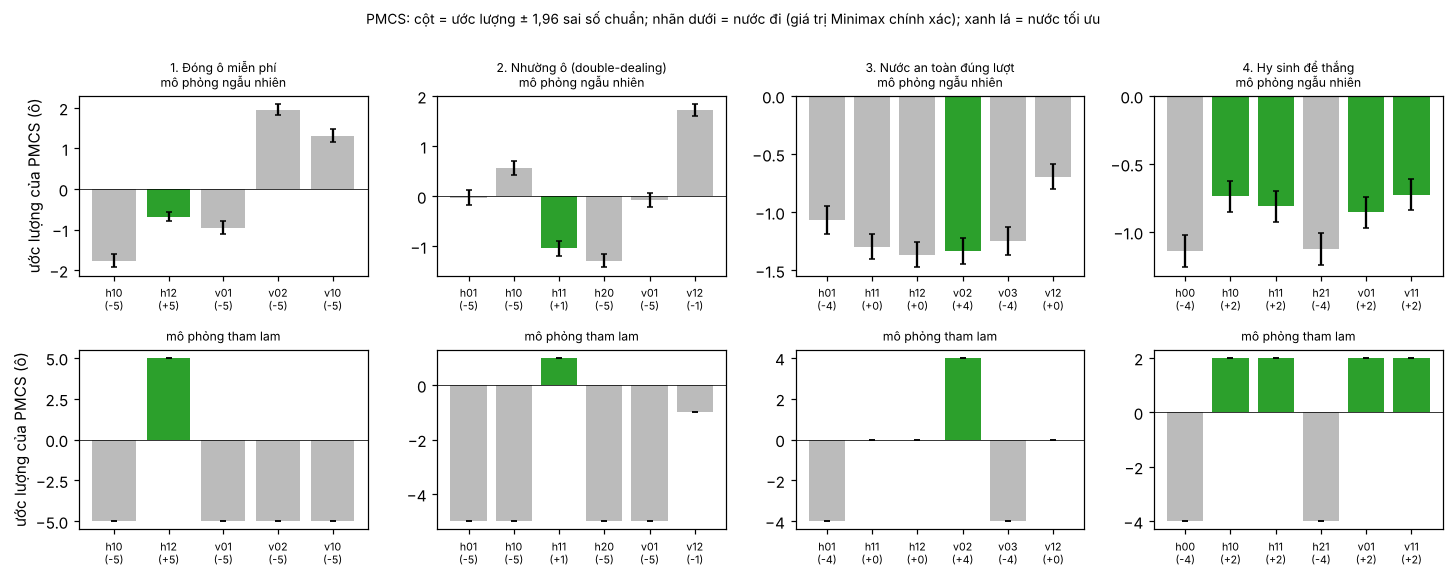

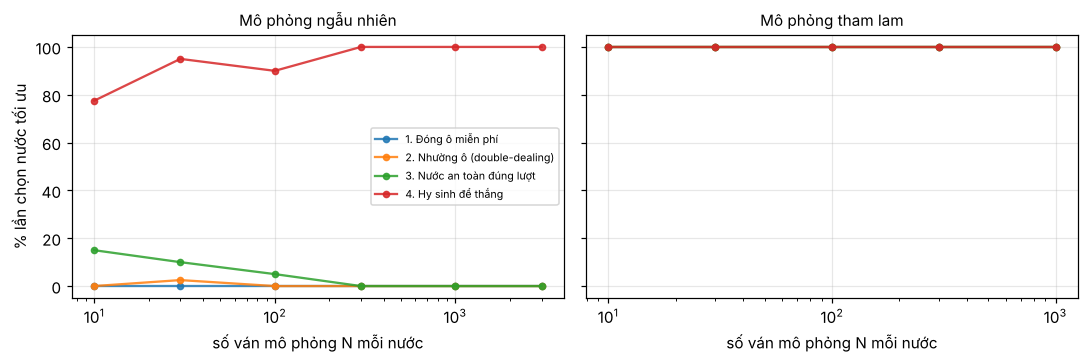

In [37]:
# ---- PMCS trên 4 bàn thử của Task 3: có chọn đúng nước tối ưu không, và cần bao nhiêu ván mô phỏng? ----
PM_N_RAND, PM_N_GREEDY, PM_TRIALS = [10, 30, 100, 300, 1000, 3000], [10, 30, 100, 300, 1000], 40
pm_tb = []
for tb in TEST_BOARDS:
    g = geom(tb["size"]); lines = g.mask(board_from_lines(tb["size"], tb["lines"]))
    ex = ExactSolver(tb["size"]).action_values(lines); best = max(ex.values())
    res = {}
    for rollout, Ns in (("ngẫu nhiên", PM_N_RAND), ("tham lam", PM_N_GREEDY)):
        for N in Ns:
            pm = PureMonteCarlo(N, rollout, seed = 1); ok = reg = 0
            for _ in range(PM_TRIALS):                       # lặp lại để đo xác suất chọn đúng (PMCS có ngẫu nhiên)
                l, _v = pm.best(g, lines); ok += ex[l] == best; reg += best - ex[l]
            res[(rollout, N)] = (ok / PM_TRIALS, reg / PM_TRIALS)
    est = {r: PureMonteCarlo(max(Ns), r, seed = 2).values(g, lines) for r, Ns in (("ngẫu nhiên", PM_N_RAND), ("tham lam", PM_N_GREEDY))}
    pm_tb.append(dict(name = tb["name"], g = g, lines = lines, ex = ex, best = best, res = res, est = est))

for rollout, Ns in (("ngẫu nhiên", PM_N_RAND), ("tham lam", PM_N_GREEDY)):
    print(f"Chính sách mô phỏng {rollout}: % số lần chọn đúng nước tối ưu ({PM_TRIALS} lần lặp) theo số ván mô phỏng N mỗi nước")
    display(pd.DataFrame({f"N = {N}": [f"{100 * d['res'][(rollout, N)][0]:.0f} %" for d in pm_tb] for N in Ns}, index = [d["name"] for d in pm_tb]))

# Hình 1: ước lượng của PMCS cho từng nước đi; xanh lá = nước tối ưu theo Alpha-Beta chính xác
fig, axes = plt.subplots(2, len(pm_tb), figsize = (3.3 * len(pm_tb), 5.2), dpi = 110)
for j, d in enumerate(pm_tb):
    for i, rollout in enumerate(("ngẫu nhiên", "tham lam")):
        ax = axes[i, j]; ls = sorted(d["est"][rollout]);
        ax.bar(range(len(ls)), [d["est"][rollout][l][0] for l in ls], yerr = [1.96 * d["est"][rollout][l][1] for l in ls], capsize = 2,
               color = ["#2ca02c" if d["ex"][l] == d["best"] else "#bbbbbb" for l in ls])
        ax.set_xticks(range(len(ls))); ax.set_xticklabels([f"{d['g'].lines[l][0]}{d['g'].lines[l][1]}{d['g'].lines[l][2]}\n({d['ex'][l]:+d})" for l in ls], fontsize = 7)
        ax.axhline(0, color = "k", lw = 0.5)
        ax.set_title((d["name"] + "\n" if i == 0 else "") + f"mô phỏng {rollout}", fontsize = 8)
        if j == 0:
            ax.set_ylabel("ước lượng của PMCS (ô)")
plt.suptitle("PMCS: cột = ước lượng ± 1,96 sai số chuẩn; nhãn dưới = nước đi (giá trị Minimax chính xác); xanh lá = nước tối ưu", fontsize = 9, y = 1.0)
plt.tight_layout(); plt.show()

# Hình 2: xác suất chọn đúng theo N
fig, axes = plt.subplots(1, 2, figsize = (10, 3.4), dpi = 110, sharey = True)
for ax, (rollout, Ns) in zip(axes, (("ngẫu nhiên", PM_N_RAND), ("tham lam", PM_N_GREEDY))):
    for k, d in enumerate(pm_tb):
        ax.semilogx(Ns, [100 * d["res"][(rollout, N)][0] for N in Ns], "o-", ms = 4, label = d["name"], alpha = 0.85)
    ax.set_title(f"Mô phỏng {rollout}", fontsize = 10); ax.set_xlabel("số ván mô phỏng N mỗi nước"); ax.grid(alpha = .3); ax.set_ylim(-5, 105)
axes[0].set_ylabel("% lần chọn nước tối ưu"); axes[0].legend(fontsize = 7)
plt.tight_layout(); plt.show()

In [38]:
def acc(d, rollout, N):
    return d["res"][(rollout, N)][0]
nmax_r, nmax_g = max(PM_N_RAND), max(PM_N_GREEDY)
good_r = [d["name"] for d in pm_tb if acc(d, "ngẫu nhiên", nmax_r) >= 0.9]; bad_r = [d for d in pm_tb if acc(d, "ngẫu nhiên", nmax_r) < 0.9]
good_g = [d["name"] for d in pm_tb if acc(d, "tham lam", nmax_g) >= 0.9]
need_g = {d["name"]: next((N for N in PM_N_GREEDY if acc(d, "tham lam", N) >= 0.9), None) for d in pm_tb}
need_r = {d["name"]: next((N for N in PM_N_RAND if acc(d, "ngẫu nhiên", N) >= 0.9), None) for d in pm_tb}
n_gr_alone = sum(i["gr_val"] == i["best"] for i in manual_info)                # agent tham lam đứng một mình đúng mấy bàn (Task 3)
flat_r = [d for d in bad_r if abs(acc(d, "ngẫu nhiên", nmax_r) - acc(d, "ngẫu nhiên", PM_N_RAND[len(PM_N_RAND) // 2])) < 0.15]
ex_bad = ""
if bad_r:
    d = bad_r[0]; l_best = [l for l in d["ex"] if d["ex"][l] == d["best"]][0]
    other = max((l for l in d["est"]["ngẫu nhiên"] if d["ex"][l] != d["best"]), key = lambda l: d["est"]["ngẫu nhiên"][l][0])
    ex_bad = (f" Ví dụ ở \"{d['name']}\": nước tối ưu có giá trị Minimax {d['ex'][l_best]:+d} nhưng PMCS ngẫu nhiên ước lượng chỉ {d['est']['ngẫu nhiên'][l_best][0]:+.2f} (± {1.96 * d['est']['ngẫu nhiên'][l_best][1]:.2f}), "
              f"thấp hơn nước {d['g'].lines[other]} (giá trị Minimax {d['ex'][other]:+d}) được ước lượng {d['est']['ngẫu nhiên'][other][0]:+.2f}: trong mô phỏng ngẫu nhiên, ván không tiếp tục đúng cách (không đóng hết chuỗi / không giữ quyền kiểm soát) nên lợi thế của nước tối ưu bị 'pha loãng'.")
display(Markdown(f"""
**Nhận xét** (chạy {PM_TRIALS} lần cho mỗi cấu hình để đo xác suất chọn đúng; các bàn thử chỉ còn 5-6 đường nên mỗi ván mô phỏng rất ngắn).
* **Mô phỏng ngẫu nhiên:** với N = {nmax_r:,} ván mỗi nước, PMCS chọn đúng nước tối ưu (≥ 90 % số lần) ở {len(good_r)}/{len(pm_tb)} bàn{(': ' + ', '.join(good_r)) if good_r else ''}; ở {len(bad_r)} bàn còn lại tỷ lệ chọn đúng là {', '.join(f"{100 * acc(d, 'ngẫu nhiên', nmax_r):.0f} %" for d in bad_r) if bad_r else '-'}. {('Tăng N **không cải thiện** các bàn này' + (' (tỷ lệ gần như không đổi từ N = ' + str(PM_N_RAND[len(PM_N_RAND) // 2]) + ' đến N = ' + str(nmax_r) + ')' if len(flat_r) == len(bad_r) else '') + ': sai số ngẫu nhiên đã nhỏ nhưng ước lượng hội tụ về giá trị "khi cả hai chơi ngẫu nhiên", không phải giá trị Minimax - đây là **độ chệch của chính sách mô phỏng**, không sửa được bằng cách chạy nhiều hơn.') if bad_r else ''}{ex_bad}
* **Mô phỏng tham lam:** PMCS chọn đúng ≥ 90 % số lần ở {len(good_g)}/{len(pm_tb)} bàn với N = {nmax_g:,}{(' (chỉ cần N = ' + str(max(need_g.values())) + ' ván mỗi nước ở mọi bàn)') if all(v is not None for v in need_g.values()) else ''}. Điều đáng chú ý là agent tham lam *đứng một mình* chỉ chọn đúng {n_gr_alone}/{len(manual_info)} bàn (Task 3), nhưng khi dùng nó làm chính sách mô phỏng thì PMCS đúng {'nhiều hơn' if len(good_g) > n_gr_alone else 'không nhiều hơn'}: ước lượng "trung bình của các ván tham lam sau nước a" nhìn trước được hậu quả của nước đó chứ không chỉ chọn nước theo quy tắc cứng.
* **Giới hạn của kết luận:** các bàn thử rất nhỏ (5-6 đường chưa vẽ nên chỉ có vài trăm thứ tự đi), vì vậy PMCS gần như duyệt hết cây. Ở phần dưới ta thử trên các thế cờ giữa ván lớn hơn của bàn 4 × 4 chấm.
"""))


**Nhận xét** (chạy 40 lần cho mỗi cấu hình để đo xác suất chọn đúng; các bàn thử chỉ còn 5-6 đường nên mỗi ván mô phỏng rất ngắn).
* **Mô phỏng ngẫu nhiên:** với N = 3,000 ván mỗi nước, PMCS chọn đúng nước tối ưu (≥ 90 % số lần) ở 1/4 bàn: 4. Hy sinh để thắng; ở 3 bàn còn lại tỷ lệ chọn đúng là 0 %, 0 %, 0 %. Tăng N **không cải thiện** các bàn này (tỷ lệ gần như không đổi từ N = 300 đến N = 3000): sai số ngẫu nhiên đã nhỏ nhưng ước lượng hội tụ về giá trị "khi cả hai chơi ngẫu nhiên", không phải giá trị Minimax - đây là **độ chệch của chính sách mô phỏng**, không sửa được bằng cách chạy nhiều hơn. Ví dụ ở "1. Đóng ô miễn phí": nước tối ưu có giá trị Minimax +5 nhưng PMCS ngẫu nhiên ước lượng chỉ -0.69 (± 0.11), thấp hơn nước ('v', 0, 2) (giá trị Minimax -5) được ước lượng +1.96: trong mô phỏng ngẫu nhiên, ván không tiếp tục đúng cách (không đóng hết chuỗi / không giữ quyền kiểm soát) nên lợi thế của nước tối ưu bị 'pha loãng'.
* **Mô phỏng tham lam:** PMCS chọn đúng ≥ 90 % số lần ở 4/4 bàn với N = 1,000 (chỉ cần N = 10 ván mỗi nước ở mọi bàn). Điều đáng chú ý là agent tham lam *đứng một mình* chỉ chọn đúng 1/4 bàn (Task 3), nhưng khi dùng nó làm chính sách mô phỏng thì PMCS đúng nhiều hơn: ước lượng "trung bình của các ván tham lam sau nước a" nhìn trước được hậu quả của nước đó chứ không chỉ chọn nước theo quy tắc cứng.
* **Giới hạn của kết luận:** các bàn thử rất nhỏ (5-6 đường chưa vẽ nên chỉ có vài trăm thứ tự đi), vì vậy PMCS gần như duyệt hết cây. Ở phần dưới ta thử trên các thế cờ giữa ván lớn hơn của bàn 4 × 4 chấm.


Hối tiếc TB ± sai số chuẩn (ô) | % nước tối ưu | ms mỗi nước - trên 60 thế cờ giữa ván của bàn 4 × 4 chấm:


,Phương pháp,Kết quả
0,"PMCS, mô phỏng ngẫu nhiên, N = 30",2.87 ± 0.41 | 35 % | 2.9
1,"PMCS, mô phỏng ngẫu nhiên, N = 100",3.47 ± 0.46 | 28 % | 8.9
2,"PMCS, mô phỏng ngẫu nhiên, N = 300",3.47 ± 0.45 | 27 % | 29.0
3,"PMCS, mô phỏng ngẫu nhiên, N = 1000",3.30 ± 0.47 | 33 % | 93.5
4,"PMCS, mô phỏng tham lam, N = 10",2.03 ± 0.32 | 43 % | 3.0
5,"PMCS, mô phỏng tham lam, N = 30",1.93 ± 0.34 | 50 % | 9.1
6,"PMCS, mô phỏng tham lam, N = 100",1.50 ± 0.30 | 58 % | 29.3
7,"PMCS, mô phỏng tham lam, N = 300",1.70 ± 0.29 | 50 % | 85.9
8,"Alpha-Beta cắt độ sâu 1, H0",3.77 ± 0.46 | 22 % | 0.0
9,"Alpha-Beta cắt độ sâu 3, H0",2.10 ± 0.34 | 48 % | 0.5


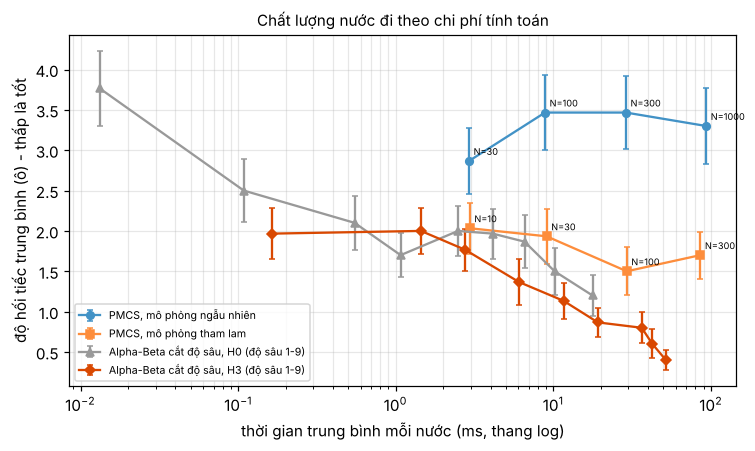

In [39]:
# ---- PMCS và Alpha-Beta cắt độ sâu trên cùng các thế cờ giữa ván của bàn 4 × 4 chấm (nghiệm chính xác ở Task 4) ----
HARD_M, HARD_NR, HARD_NG = 60, [30, 100, 300, 1000], [10, 30, 100, 300]
M = min(HARD_M, len(positions))
hard = {}
for rollout, Ns in (("ngẫu nhiên", HARD_NR), ("tham lam", HARD_NG)):
    for N in Ns:
        pm = PureMonteCarlo(N, rollout, seed = 3); reg, secs = [], []
        for p, av in zip(positions[:M], exact_av[:M]):
            t0 = time.perf_counter(); l, _v = pm.best(g_main, p); secs.append(time.perf_counter() - t0)
            reg.append(max(av.values()) - av[l])
        hard[(rollout, N)] = dict(regret = np.array(reg, dtype = float), sec = np.array(secs))

def cell_(r):
    return f"{r['regret'].mean():.2f} ± {se(r['regret']):.2f} | {100 * (r['regret'] == 0).mean():.0f} % | {1000 * r['sec'].mean():.1f}"
print(f"Hối tiếc TB ± sai số chuẩn (ô) | % nước tối ưu | ms mỗi nước - trên {M} thế cờ giữa ván của bàn {HEUR_SIZE[0]} × {HEUR_SIZE[1]} chấm:")
rows = [{"Phương pháp": f"PMCS, mô phỏng {r}, N = {N}", "Kết quả": cell_(v)} for (r, N), v in hard.items()]
sub = lambda h, d: dict(regret = cut_res[(h, d)]["regret"][:M], sec = cut_res[(h, d)]["sec"][:M])
ref_depths = [d for d in CUT_DEPTHS if d in (1, 3, 5, 7)] or CUT_DEPTHS[-1:]
rows += [{"Phương pháp": f"Alpha-Beta cắt độ sâu {d}, {h}", "Kết quả": cell_(sub(h, d))} for h in ("H0", "H3") for d in ref_depths]
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize = (7, 4.2), dpi = 110)
for (name, col, mk), keys in ((("PMCS, mô phỏng ngẫu nhiên", "#4292c6", "o"), [("ngẫu nhiên", N) for N in HARD_NR]), (("PMCS, mô phỏng tham lam", "#fd8d3c", "s"), [("tham lam", N) for N in HARD_NG])):
    ax.errorbar([1000 * hard[k]["sec"].mean() for k in keys], [hard[k]["regret"].mean() for k in keys], yerr = [se(hard[k]["regret"]) for k in keys], fmt = mk + "-", color = col, ms = 5, capsize = 2, label = name)
    for k in keys:
        ax.annotate(f"N={k[1]}", (1000 * hard[k]["sec"].mean(), hard[k]["regret"].mean()), fontsize = 6, xytext = (3, 4), textcoords = "offset points")
for h, col, mk in (("H0", "#999999", "^"), ("H3", "#d94801", "D")):
    r = [sub(h, d) for d in CUT_DEPTHS]
    ax.errorbar([1000 * x["sec"].mean() for x in r], [x["regret"].mean() for x in r], yerr = [se(x["regret"]) for x in r], fmt = mk + "-", color = col, ms = 5, capsize = 2, label = f"Alpha-Beta cắt độ sâu, {h} (độ sâu {CUT_DEPTHS[0]}-{CUT_DEPTHS[-1]})")
ax.set_xscale("log"); ax.set_xlabel("thời gian trung bình mỗi nước (ms, thang log)"); ax.set_ylabel("độ hối tiếc trung bình (ô) - thấp là tốt")
ax.set_title("Chất lượng nước đi theo chi phí tính toán", fontsize = 10); ax.grid(alpha = .3, which = "both"); ax.legend(fontsize = 7)
plt.tight_layout(); plt.show()

In [40]:
best_pm = min(hard, key = lambda k: hard[k]["regret"].mean())
t_best = 1000 * hard[best_pm]["sec"].mean(); r_best = hard[best_pm]["regret"].mean()
def cut_near(h, t_ms):
    """Cấu hình Alpha-Beta cắt độ sâu của hàm h có thời gian mỗi nước gần t_ms nhất."""
    d = min(CUT_DEPTHS, key = lambda d: abs(np.log(1000 * sub(h, d)["sec"].mean() / t_ms)))
    return d, sub(h, d)
d_c, r_c = cut_near("H3", t_best)
reg_small = float(np.mean([d["res"][("tham lam", max(PM_N_GREEDY))][1] for d in pm_tb]))
best_by_family = {r: min((k for k in hard if k[0] == r), key = lambda k: hard[k]["regret"].mean()) for r in ("ngẫu nhiên", "tham lam")}
fam_txt = "; ".join(f"mô phỏng {r}: tốt nhất N = {k[1]} (hối tiếc {hard[k]['regret'].mean():.2f} ô, {1000 * hard[k]['sec'].mean():.0f} ms/nước)" for r, k in best_by_family.items())
display(Markdown(f"""
**Nhận xét** ({M} thế cờ giữa ván, còn {g_main.L - max(popcount(p) for p in positions[:M])}-{g_main.L - min(popcount(p) for p in positions[:M])} đường chưa vẽ - khó hơn nhiều so với 4 bàn thử).
* Hối tiếc của PMCS ở đây là {r_best:.2f} ô mỗi nước ngay cả ở cấu hình tốt nhất, so với {reg_small:.2f} ô trung bình của PMCS tham lam ở 4 bàn thử nhỏ: {fam_txt}.
* **So với Alpha-Beta cắt độ sâu ở chi phí tương đương:** cấu hình PMCS tốt nhất ({best_pm[0]}, N = {best_pm[1]}) mất {t_best:.0f} ms/nước với hối tiếc {r_best:.2f} ô; Alpha-Beta cắt độ sâu {d_c} với H3 mất {1000 * r_c['sec'].mean():.0f} ms/nước với hối tiếc {r_c['regret'].mean():.2f} ô ({'Alpha-Beta tốt hơn' if r_c['regret'].mean() < r_best else 'PMCS tốt hơn'} ở mức chi phí này, chênh lệch {abs(r_c['regret'].mean() - r_best):.2f} ô, sai số chuẩn khoảng {max(se(r_c['regret']), se(hard[best_pm]['regret'])):.2f}).
* **Điểm khác nhau về bản chất:** Alpha-Beta cắt độ sâu cần một hàm heuristic được thiết kế riêng cho trò chơi (Task 4), còn PMCS chỉ cần luật chơi; nhưng chất lượng của PMCS lại bị chặn bởi chính sách mô phỏng (xem phần trên) chứ không chỉ bởi N.
"""))


**Nhận xét** (60 thế cờ giữa ván, còn 8-18 đường chưa vẽ - khó hơn nhiều so với 4 bàn thử).
* Hối tiếc của PMCS ở đây là 1.50 ô mỗi nước ngay cả ở cấu hình tốt nhất, so với 0.00 ô trung bình của PMCS tham lam ở 4 bàn thử nhỏ: mô phỏng ngẫu nhiên: tốt nhất N = 30 (hối tiếc 2.87 ô, 3 ms/nước); mô phỏng tham lam: tốt nhất N = 100 (hối tiếc 1.50 ô, 29 ms/nước).
* **So với Alpha-Beta cắt độ sâu ở chi phí tương đương:** cấu hình PMCS tốt nhất (tham lam, N = 100) mất 29 ms/nước với hối tiếc 1.50 ô; Alpha-Beta cắt độ sâu 7 với H3 mất 36 ms/nước với hối tiếc 0.80 ô (Alpha-Beta tốt hơn ở mức chi phí này, chênh lệch 0.70 ô, sai số chuẩn khoảng 0.30).
* **Điểm khác nhau về bản chất:** Alpha-Beta cắt độ sâu cần một hàm heuristic được thiết kế riêng cho trò chơi (Task 4), còn PMCS chỉ cần luật chơi; nhưng chất lượng của PMCS lại bị chặn bởi chính sách mô phỏng (xem phần trên) chứ không chỉ bởi N.


### Best First Move

How would you determine what the best first move for a standard board ($5 \times 5$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

**Cách tiếp cận.** Bàn chuẩn 5 × 5 chấm (4 × 4 ô, 40 đường) quá lớn để giải chính xác bằng bộ giải của ta (ước lượng ở Task 3). Ta làm theo bốn bước:
1. **Đối xứng:** bàn không đổi khi lật/xoay (8 phép) nên 40 nước đầu chỉ thuộc một vài *lớp tương đương*; chỉ cần đánh giá một đại diện mỗi lớp.
2. **Đánh giá từng lớp** bằng các phương pháp đã cài: PMCS với mô phỏng ngẫu nhiên, PMCS với mô phỏng tham lam, và Alpha-Beta cắt độ sâu với H3.
3. **Kiểm định phương pháp trên bàn đã biết đáp án:** ở các bàn nhỏ (3 × 3 và 3 × 5 chấm) ta tính được giá trị chính xác của mọi nước đầu bằng Task 3 và các giá trị đó **không đều nhau**, nên có thể thử xem phương pháp nào xếp hạng các lớp đúng.
4. **Chỉ tin kết quả ở bàn 5 × 5 đến mức phương pháp đã đúng ở bước 3**, và báo cáo kèm sai số.

Kiểm định trên bàn 3 × 3 chấm (12 đường, 2 lớp nước đầu; PMCS: N = 20,000 ngẫu nhiên / 3,000 tham lam; ± là khoảng 95 %):


,Lớp,Đại diện,Số đường trong lớp,Giá trị chính xác,PMCS ngẫu nhiên,PMCS tham lam,"Alpha-Beta H3, độ sâu 4"
0,1,h00,8,2,-0.13 ± 0.04,+1.52 ± 0.10,-1.0
1,2,h10,4,0,+0.31 ± 0.04,+1.28 ± 0.07,-1.0


Kiểm định trên bàn 3 × 5 chấm (22 đường, 7 lớp nước đầu; PMCS: N = 10,000 ngẫu nhiên / 1,500 tham lam; ± là khoảng 95 %):


,Lớp,Đại diện,Số đường trong lớp,Giá trị chính xác,PMCS ngẫu nhiên,PMCS tham lam,"Alpha-Beta H3, độ sâu 4"
0,1,h00,4,2,-0.03 ± 0.10,+1.28 ± 0.20,-1.0
1,2,h01,4,2,-0.07 ± 0.10,+1.42 ± 0.21,-1.0
2,3,h10,2,2,-0.22 ± 0.10,+1.37 ± 0.18,-1.0
3,4,h11,2,0,-0.03 ± 0.10,+1.61 ± 0.19,-1.0
4,5,v00,4,2,+0.03 ± 0.10,+1.44 ± 0.19,-1.0
5,6,v01,4,2,-0.10 ± 0.10,+1.18 ± 0.18,-1.0
6,7,v02,2,0,-0.07 ± 0.10,+1.18 ± 0.17,-1.0


Bàn chuẩn 5 × 5 chấm (40 đường, 6 lớp nước đầu; PMCS: N = 20,000 ngẫu nhiên / 3,000 tham lam mỗi lớp; tổng 5 s):


,Lớp,Đại diện,Số đường trong lớp,PMCS ngẫu nhiên,PMCS tham lam,"Alpha-Beta H3, độ sâu 4"
0,1,h00,8,-0.01 ± 0.12,+1.22 ± 0.24,-1.0
1,2,h01,8,+0.08 ± 0.12,+1.27 ± 0.25,-1.0
2,3,h10,8,-0.01 ± 0.12,+1.26 ± 0.24,-1.0
3,4,h11,8,+0.03 ± 0.12,+1.40 ± 0.24,-1.0
4,5,h20,4,-0.04 ± 0.12,+1.36 ± 0.23,-1.0
5,6,h21,4,-0.04 ± 0.12,+1.54 ± 0.24,-1.0


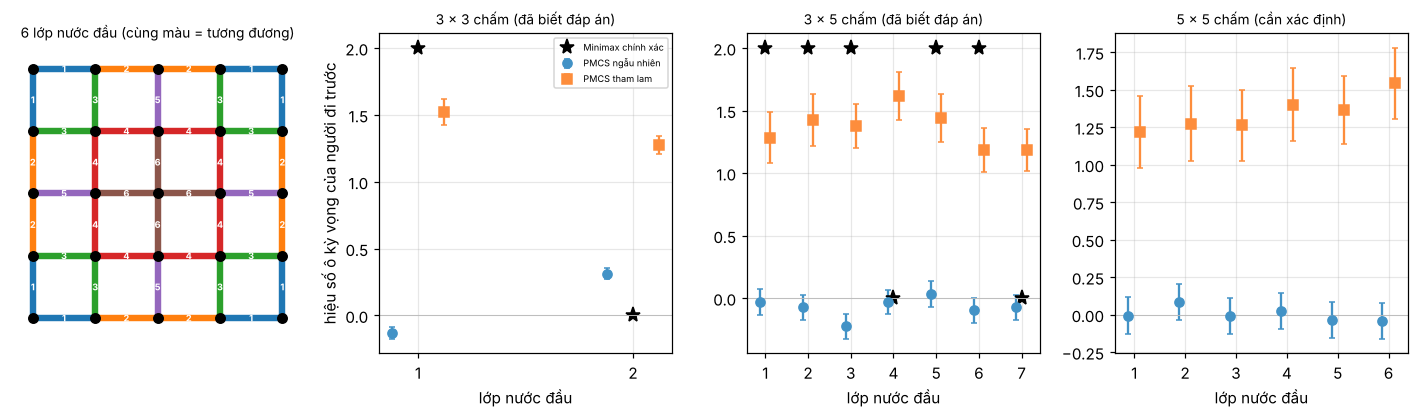

In [41]:
# Your code/ answer goes here.

# ---- Nước đi đầu tiên tốt nhất ----
BF_SIZE, BF_CAL = (5, 5), [(3, 3), (3, 5)]
BF_CAL_NR, BF_CAL_NG, BF_NR, BF_NG, BF_DEPTH = [20000, 10000], [3000, 1500], 20000, 3000, 4

def ranks(x):
    """Hạng (có xử lý hòa bằng hạng trung bình)."""
    x = np.asarray(x, dtype = float); order = np.argsort(x); r = np.empty(len(x))
    i = 0
    while i < len(x):
        j = i
        while j + 1 < len(x) and x[order[j + 1]] == x[order[i]]:
            j += 1
        r[order[i:j + 1]] = (i + j) / 2; i = j + 1
    return r

def spearman(a, b):
    ra, rb = ranks(a), ranks(b)
    return float(np.corrcoef(ra, rb)[0, 1]) if ra.std() > 0 and rb.std() > 0 else float("nan")

def first_move_table(size, n_rand, n_greedy, depth, exact):
    """Đánh giá đại diện của mỗi lớp nước đầu tiên bằng PMCS (hai chính sách) và Alpha-Beta cắt độ sâu (H3); `exact` = có tính thêm giá trị chính xác."""
    g = geom(size); orbits = line_orbits(size); reps = [o[0] for o in orbits]
    ex = ExactSolver(size).action_values(0, only = set(reps)) if exact else None
    pr, pg = PureMonteCarlo(n_rand, "ngẫu nhiên", seed = 11), PureMonteCarlo(n_greedy, "tham lam", seed = 12)
    cs = CutoffSolver(size, depth, HEURISTICS["H3"]); rows = []
    for i, (o, l) in enumerate(zip(orbits, reps)):
        rows.append(dict(cls = i + 1, rep = g.lines[l], n = len(o), exact = ex[l] if exact else None, rand = pr.estimate(g, 0, l), greedy = pg.estimate(g, 0, l),
                         h3 = float(-cs.dsearch(1 << l, depth - 1, -99, 99))))      # nước đầu không đóng ô nên đổi dấu
    return rows

cal = {}
for size, nr, ng in zip(BF_CAL, BF_CAL_NR, BF_CAL_NG):
    t0 = time.perf_counter(); cal[size] = first_move_table(size, nr, ng, BF_DEPTH, True); cal[size + ("t",)] = time.perf_counter() - t0
t0 = time.perf_counter()
bf = first_move_table(BF_SIZE, BF_NR, BF_NG, BF_DEPTH, False); t_bf = time.perf_counter() - t0

def fmt(v):
    return f"{v[0]:+.2f} ± {1.96 * v[1]:.2f}"
for size in BF_CAL:
    print(f"Kiểm định trên bàn {size[0]} × {size[1]} chấm ({n_lines(size)} đường, {len(cal[size])} lớp nước đầu; PMCS: N = {BF_CAL_NR[BF_CAL.index(size)]:,} ngẫu nhiên / {BF_CAL_NG[BF_CAL.index(size)]:,} tham lam; ± là khoảng 95 %):")
    display(pd.DataFrame([{"Lớp": r["cls"], "Đại diện": "%s%d%d" % r["rep"], "Số đường trong lớp": r["n"], "Giá trị chính xác": r["exact"], "PMCS ngẫu nhiên": fmt(r["rand"]), "PMCS tham lam": fmt(r["greedy"]), f"Alpha-Beta H3, độ sâu {BF_DEPTH}": f"{r['h3']:+.1f}"} for r in cal[size]]))
print(f"Bàn chuẩn {BF_SIZE[0]} × {BF_SIZE[1]} chấm ({n_lines(BF_SIZE)} đường, {len(bf)} lớp nước đầu; PMCS: N = {BF_NR:,} ngẫu nhiên / {BF_NG:,} tham lam mỗi lớp; tổng {t_bf:.0f} s):")
display(pd.DataFrame([{"Lớp": r["cls"], "Đại diện": "%s%d%d" % r["rep"], "Số đường trong lớp": r["n"], "PMCS ngẫu nhiên": fmt(r["rand"]), "PMCS tham lam": fmt(r["greedy"]), f"Alpha-Beta H3, độ sâu {BF_DEPTH}": f"{r['h3']:+.1f}"} for r in bf]))

# Hình: các lớp trên bàn 5 × 5 và ước lượng theo lớp
from matplotlib import colors as mcolors
pal = plt.cm.tab10(np.arange(len(bf)))
fig = plt.figure(figsize = (13, 3.9), dpi = 110)
ax0 = fig.add_subplot(1, 4, 1); gb = geom(BF_SIZE)
draw_board(new_board(*BF_SIZE), ax = ax0, mark = {gb.lines[l]: mcolors.to_hex(pal[i]) for i, o in enumerate(line_orbits(BF_SIZE)) for l in o}, fontsize = 8, title = f"{len(bf)} lớp nước đầu (cùng màu = tương đương)")
for i, o in enumerate(line_orbits(BF_SIZE)):
    for l in o:
        kind, ri_, ci_ = gb.lines[l]; x, y = ((ci_ + 0.5, -ri_) if kind == "h" else (ci_, -ri_ - 0.5)); ax0.text(x, y, str(i + 1), ha = "center", va = "center", fontsize = 6, color = "white", fontweight = "bold", zorder = 6)
for k, (size, rows_) in enumerate([(s, cal[s]) for s in BF_CAL] + [(BF_SIZE, bf)]):
    ax = fig.add_subplot(1, 4, k + 2); xs = np.arange(len(rows_))
    ax.errorbar(xs - 0.12, [r["rand"][0] for r in rows_], yerr = [1.96 * r["rand"][1] for r in rows_], fmt = "o", color = "#4292c6", capsize = 2, label = "PMCS ngẫu nhiên")
    ax.errorbar(xs + 0.12, [r["greedy"][0] for r in rows_], yerr = [1.96 * r["greedy"][1] for r in rows_], fmt = "s", color = "#fd8d3c", capsize = 2, label = "PMCS tham lam")
    if rows_[0]["exact"] is not None:
        ax.plot(xs, [r["exact"] for r in rows_], "k*", ms = 10, label = "Minimax chính xác")
    ax.axhline(0, color = "#bbb", lw = 0.6); ax.set_xticks(xs); ax.set_xticklabels([r["cls"] for r in rows_]); ax.set_xlabel("lớp nước đầu"); ax.grid(alpha = .3)
    ax.set_title(f"{size[0]} × {size[1]} chấm" + (" (đã biết đáp án)" if rows_[0]["exact"] is not None else " (cần xác định)"), fontsize = 9)
    if k == 0:
        ax.set_ylabel("hiệu số ô kỳ vọng của người đi trước"); ax.legend(fontsize = 6)
plt.tight_layout(); plt.show()

In [42]:
def agree(rows, key):
    """(hạng Spearman với giá trị chính xác, lớp được xếp cao nhất có phải lớp tối ưu không)."""
    ex_ = [r["exact"] for r in rows]; v_ = [r[key][0] if isinstance(r[key], tuple) else r[key] for r in rows]
    top = [i for i, v in enumerate(v_) if v == max(v_)]                  # các lớp đứng đầu (kể cả đồng hạng)
    return spearman(ex_, v_), all(ex_[i] == max(ex_) for i in top)       # đúng chỉ khi MỌI lớp đồng hạng nhất đều tối ưu
cal_txt = []
for size in BF_CAL:
    parts = []
    for key, nm in (("rand", "PMCS ngẫu nhiên"), ("greedy", "PMCS tham lam"), ("h3", "Alpha-Beta H3")):
        rho, hit = agree(cal[size], key)
        parts.append(f"{nm}: " + (f"ρ = {rho:+.2f}" if rho == rho else "ρ không xác định (mọi lớp cùng giá trị)") + f", lớp đứng đầu {'đúng' if hit else 'sai'}")
    ex_vals = sorted({r["exact"] for r in cal[size]})
    cal_txt.append(f"bàn {size[0]} × {size[1]} (giá trị chính xác của các lớp: {', '.join(f'{v:+d}' for v in ex_vals)}) - " + "; ".join(parts))
def sep(rows, key):
    """Các lớp ở bàn 5 × 5 có khác nhau có ý nghĩa thống kê không (so lớp cao nhất với lớp thấp nhất, khoảng tin cậy 95 %)?"""
    hi, lo = max(rows, key = lambda r: r[key][0]), min(rows, key = lambda r: r[key][0])
    diff = hi[key][0] - lo[key][0]; err = 1.96 * math.hypot(hi[key][1], lo[key][1])
    return hi, lo, diff, err
hi_r, lo_r, d_r, e_r = sep(bf, "rand"); hi_g, lo_g, d_g, e_g = sep(bf, "greedy")
reliable = [nm for key, nm in (("rand", "PMCS ngẫu nhiên"), ("greedy", "PMCS tham lam")) if all(agree(cal[s], key)[1] and agree(cal[s], key)[0] > 0.5 for s in BF_CAL)]
best_cls = hi_g if "PMCS tham lam" in reliable else (hi_r if reliable else None)
human55 = f" (Task 3 ước lượng cỡ {human_time(t55)} cho bàn này)" if "t55" in globals() else ""
if reliable:
    sig_ = (d_g > e_g) if "PMCS tham lam" in reliable else (d_r > e_r)
    concl = (f"chỉ {' và '.join(reliable)} xếp đúng lớp tốt nhất ở mọi bàn kiểm định (top-1 đúng và ρ > 0,5), nên ta tin chúng hơn; theo đó nước đầu tốt nhất cho bàn 5 × 5 chấm thuộc lớp {best_cls['cls']} "
             f"(ví dụ nước {'%s%d%d' % best_cls['rep']}), nhưng khác biệt giữa các lớp {'có' if sig_ else 'chưa có'} ý nghĩa thống kê.")
else:
    concl = ("không phương pháp nào xếp đúng lớp tốt nhất ở cả hai bàn kiểm định (xem ρ và cột 'Giá trị chính xác' ở trên), nên ta **không thể** khẳng định lớp nào là tốt nhất ở bàn 5 × 5 chấm; "
             "các bảng trên chỉ cho biết lớp nào được ưa thích dưới từng mô hình đối thủ.")
display(Markdown(f"""
**Nhận xét.**
* **Kiểm định phương pháp (bàn đã biết đáp án):** {'; '.join(cal_txt)}. ρ là hệ số tương quan hạng Spearman giữa giá trị chính xác và ước lượng của các lớp.
* **Bàn 5 × 5 chấm:** PMCS ngẫu nhiên xếp lớp {hi_r['cls']} ({'%s%d%d' % hi_r['rep']}) cao nhất ({hi_r['rand'][0]:+.2f}) và lớp {lo_r['cls']} thấp nhất ({lo_r['rand'][0]:+.2f}); chênh lệch {d_r:.2f} ô, khoảng tin cậy 95 % ± {e_r:.2f} → {'khác nhau có ý nghĩa thống kê' if d_r > e_r else 'chưa khác nhau có ý nghĩa thống kê'}. PMCS tham lam xếp lớp {hi_g['cls']} ({'%s%d%d' % hi_g['rep']}) cao nhất ({hi_g['greedy'][0]:+.2f}) và lớp {lo_g['cls']} thấp nhất ({lo_g['greedy'][0]:+.2f}); chênh lệch {d_g:.2f} ô, ± {e_g:.2f} → {'khác nhau có ý nghĩa thống kê' if d_g > e_g else 'chưa khác nhau có ý nghĩa thống kê'}. Hai phương pháp {'cùng chọn lớp ' + str(hi_r['cls']) if hi_r['cls'] == hi_g['cls'] else 'chọn hai lớp khác nhau'}.
* **Kết luận phải thận trọng:** {concl}
* **Cách xác định đúng:** giải chính xác giá trị của từng lớp nước đầu bằng tìm kiếm chuyên dụng. Theo Barker & Korf (AAAI 2012), bàn 4 × 4 ô đã được giải từ trước bằng phân tích ngược của Wilson, còn chính họ giải thêm bàn 4 × 5 ô (hòa nếu hai bên chơi tối ưu); những lời giải đó cần phân tích chuỗi, đối xứng và bảng chuyển vị rất lớn{human55}, vượt xa bộ giải Python của ta. Các phương pháp lấy mẫu như PMCS trả lời một câu hỏi khác: nước đi nào tốt nhất **khi đối thủ chơi theo chính sách mô phỏng**, không phải khi đối thủ tối ưu.
* Về lý thuyết, với 4 × 4 ô người đi trước muốn số chuỗi dài là số lẻ (quy tắc chuỗi dài của Berlekamp); nước đầu tiên chỉ ảnh hưởng gián tiếp thông qua việc nó dẫn tới cấu trúc chuỗi nào, điều mà PMCS và heuristic của ta chỉ nắm bắt rất thô.
"""))


**Nhận xét.**
* **Kiểm định phương pháp (bàn đã biết đáp án):** bàn 3 × 3 (giá trị chính xác của các lớp: +0, +2) - PMCS ngẫu nhiên: ρ = -1.00, lớp đứng đầu sai; PMCS tham lam: ρ = +1.00, lớp đứng đầu đúng; Alpha-Beta H3: ρ không xác định (mọi lớp cùng giá trị), lớp đứng đầu sai; bàn 3 × 5 (giá trị chính xác của các lớp: +0, +2) - PMCS ngẫu nhiên: ρ = -0.32, lớp đứng đầu đúng; PMCS tham lam: ρ = +0.00, lớp đứng đầu sai; Alpha-Beta H3: ρ không xác định (mọi lớp cùng giá trị), lớp đứng đầu sai. ρ là hệ số tương quan hạng Spearman giữa giá trị chính xác và ước lượng của các lớp.
* **Bàn 5 × 5 chấm:** PMCS ngẫu nhiên xếp lớp 2 (h01) cao nhất (+0.08) và lớp 6 thấp nhất (-0.04); chênh lệch 0.12 ô, khoảng tin cậy 95 % ± 0.17 → chưa khác nhau có ý nghĩa thống kê. PMCS tham lam xếp lớp 6 (h21) cao nhất (+1.54) và lớp 1 thấp nhất (+1.22); chênh lệch 0.32 ô, ± 0.34 → chưa khác nhau có ý nghĩa thống kê. Hai phương pháp chọn hai lớp khác nhau.
* **Kết luận phải thận trọng:** không phương pháp nào xếp đúng lớp tốt nhất ở cả hai bàn kiểm định (xem ρ và cột 'Giá trị chính xác' ở trên), nên ta **không thể** khẳng định lớp nào là tốt nhất ở bàn 5 × 5 chấm; các bảng trên chỉ cho biết lớp nào được ưa thích dưới từng mô hình đối thủ.
* **Cách xác định đúng:** giải chính xác giá trị của từng lớp nước đầu bằng tìm kiếm chuyên dụng. Theo Barker & Korf (AAAI 2012), bàn 4 × 4 ô đã được giải từ trước bằng phân tích ngược của Wilson, còn chính họ giải thêm bàn 4 × 5 ô (hòa nếu hai bên chơi tối ưu); những lời giải đó cần phân tích chuỗi, đối xứng và bảng chuyển vị rất lớn (Task 3 ước lượng cỡ 6 ngày cho bàn này), vượt xa bộ giải Python của ta. Các phương pháp lấy mẫu như PMCS trả lời một câu hỏi khác: nước đi nào tốt nhất **khi đối thủ chơi theo chính sách mô phỏng**, không phải khi đối thủ tối ưu.
* Về lý thuyết, với 4 × 4 ô người đi trước muốn số chuỗi dài là số lẻ (quy tắc chuỗi dài của Berlekamp); nước đầu tiên chỉ ảnh hưởng gián tiếp thông qua việc nó dẫn tới cấu trúc chuỗi nào, điều mà PMCS và heuristic của ta chỉ nắm bắt rất thô.


In [43]:
# ---- Tổng kết: mọi con số lấy từ các ô ở trên ----
rs44 = random_summary[(4, 4)]
big_ = max((v["L"], k) for k, v in size_info.items() if v["solved"]); LI = size_info[big_[1]]
play_ = lambda opp: [d for k, d in play_data.items() if k[1] == opp]
win_rate = lambda opp: 100 * sum(d["wins"] for d in play_(opp)) / sum(d["n"] for d in play_(opp))
dmax = CUT_DEPTHS[-1]
reg_ = lambda h, d: cut_res[(h, d)]["regret"].mean()
ms_ = lambda h, d: 1000 * cut_res[(h, d)]["sec"].mean()
pm_acc = lambda r, Ns: 100 * np.mean([d["res"][(r, max(Ns))][0] for d in pm_tb])
rr_top = rr_table.iloc[0]["Agent"]

def fold(x):
    """Diễn đạt tỷ số x = (số nút trước) / (số nút sau) bằng lời, đúng chiều thay đổi."""
    if not x == x:
        return "thay đổi không xác định được"
    if x >= 1.05:
        return f"giảm {x:.1f} lần"
    if x <= 1 / 1.05:
        return f"tăng {1 / x:.1f} lần"
    return "gần như không đổi"

ord_gain = order_data[(ORDER_BOARDS[-1], "natural", True)]["nodes"] / order_data[(ORDER_BOARDS[-1], "safe", True)]["nodes"]
tt_key = (ORDER_NO_TT[-1], "safe", False) if ORDER_NO_TT else None
if tt_key in order_data:
    tt_gain = order_data[tt_key]["nodes"] / order_data[(ORDER_NO_TT[-1], "safe", True)]["nodes"]
    tt_txt = f"bảng chuyển vị làm số nút {fold(tt_gain)} trên bàn {ORDER_NO_TT[-1][0]} × {ORDER_NO_TT[-1][1]} chấm"
else:
    tt_txt = "bảng chuyển vị được dùng trong mọi thí nghiệm"

# --- heuristic: kết luận theo khoảng tin cậy 95 % của hiệu hối tiếc H3 - H0 ở độ sâu lớn nhất ---
m3_, c3_ = paired("H3", "H0", dmax)
if m3_ + c3_ < 0:
    h_verdict = f"H3 hối tiếc ít hơn H0 {-m3_:.2f} ± {c3_:.2f} ô (khoảng tin cậy 95 % không chứa 0)"
elif m3_ - c3_ > 0:
    h_verdict = f"H3 hối tiếc nhiều hơn H0 {m3_:.2f} ± {c3_:.2f} ô (khoảng tin cậy 95 % không chứa 0)"
else:
    h_verdict = f"hiệu H3 - H0 = {m3_:+.2f} ± {c3_:.2f} ô, khoảng tin cậy 95 % chứa 0 nên chưa phân biệt được"
corr_order = sorted((k for k in r_ if r_[k] == r_[k]), key = r_.get, reverse = True)

# --- PMCS ---
pr_, pg_ = pm_acc("ngẫu nhiên", PM_N_RAND), pm_acc("tham lam", PM_N_GREEDY)
if pg_ - pr_ >= 10:
    gap_txt = f"Chênh lệch {pg_ - pr_:.0f} điểm phần trăm giữa hai chính sách cho thấy chất lượng PMCS bị chặn bởi chính sách mô phỏng: ước lượng hội tụ về giá trị \"khi cả hai bên chơi theo chính sách đó\", không phải giá trị Minimax, nên chạy thêm ván không sửa được."
elif pr_ - pg_ >= 10:
    gap_txt = f"Ở các bàn nhỏ này mô phỏng ngẫu nhiên lại chọn đúng nhiều hơn mô phỏng tham lam {pr_ - pg_:.0f} điểm phần trăm."
else:
    gap_txt = "Ở các bàn nhỏ này hai chính sách mô phỏng cho kết quả gần nhau."
ab_r, pm_r = r_c["regret"].mean(), r_best
diff_, err_ = abs(ab_r - pm_r), max(se(r_c["regret"]), se(hard[best_pm]["regret"]))
if diff_ <= 2 * err_:
    who_ = f"chênh lệch {diff_:.2f} ô chưa vượt hai sai số chuẩn ({2 * err_:.2f}) nên chưa phân biệt được hai phương pháp"
else:
    who_ = f"{'Alpha-Beta cắt độ sâu có heuristic' if ab_r < pm_r else 'PMCS'} tốt hơn {diff_:.2f} ô (lớn hơn hai sai số chuẩn, {2 * err_:.2f})"

# --- nước đi đầu tiên cho bàn 5 x 5 chấm ---
if reliable:
    sig_ = (d_g > e_g) if "PMCS tham lam" in reliable else (d_r > e_r)
    bf_txt = (f"{' và '.join(reliable)} xếp đúng lớp tốt nhất ở các bàn kiểm định nhỏ nên được tin hơn; theo đó lớp {best_cls['cls']} (ví dụ nước {'%s%d%d' % best_cls['rep']}) được ưa thích ở bàn 5 × 5 chấm, "
              f"nhưng khác biệt giữa {len(bf)} lớp {'có' if sig_ else 'chưa có'} ý nghĩa thống kê")
else:
    bf_txt = (f"không phương pháp nào xếp đúng lớp tốt nhất ở cả hai bàn kiểm định nhỏ; ở bàn 5 × 5 chấm chênh lệch giữa lớp cao nhất và thấp nhất là {d_r:.2f} ± {e_r:.2f} ô (PMCS ngẫu nhiên) và {d_g:.2f} ± {e_g:.2f} ô (PMCS tham lam), "
              f"{'có' if (d_r > e_r or d_g > e_g) else 'chưa có'} ý nghĩa thống kê ở ít nhất một phương pháp")

display(Markdown(f"""
## Tổng kết

| Thuật toán | Cách dùng trong bài này | Chi phí mỗi nước | Chất lượng đo được |
|---|---|---|---|
| Random (đường cơ sở) | chọn đều một đường chưa vẽ | ≈ 0 | Random vs. Random trên 4 × 4 chấm: người đi trước thắng {100 * rs44['win1'] / rs44['n']:.0f} %, người đi sau {100 * rs44['win2'] / rs44['n']:.0f} % ({rs44['n']} ván) |
| Alpha-Beta chính xác (Task 3) | negamax + Alpha-Beta + bảng chuyển vị, sắp xếp: đóng ô → nước an toàn → biếu ô | giải xong bàn rỗng lớn nhất ({big_[1][0]} × {big_[1][1]} chấm, {LI['L']} đường) trong {LI['time']:.0f} s; mỗi đường thêm nhân số nút lên ≈ {10 ** slope_n:.2f} | tối ưu tuyệt đối; thắng Random {win_rate('Random'):.0f} % và agent tham lam {win_rate('Tham lam'):.0f} % số ván (hai vai) |
| Alpha-Beta cắt độ sâu + heuristic (Task 4) | cắt sau `d` đường, lá đánh giá bằng H0-H3 | H3: {ms_('H3', CUT_DEPTHS[0]):.1f} ms (d = {CUT_DEPTHS[0]}) → {ms_('H3', dmax):.0f} ms (d = {dmax}) trên bàn 4 × 4 chấm | hối tiếc trung bình {reg_('H3', dmax):.2f} ô (H3, d = {dmax}) so với {reg_('H0', dmax):.2f} ô (H0, d = {dmax}) và {reg_('H0', CUT_DEPTHS[0]):.2f} ô (H0, d = {CUT_DEPTHS[0]}) |
| Pure Monte Carlo (nâng cao) | N ván mô phỏng cho mỗi nước (ngẫu nhiên / tham lam) | {1000 * hard[best_pm]['sec'].mean():.0f} ms (cấu hình tốt nhất: {best_pm[0]}, N = {best_pm[1]}) | {len(pm_tb)} bàn thử nhỏ: chọn đúng {pr_:.0f} % (ngẫu nhiên, N = {max(PM_N_RAND):,}) / {pg_:.0f} % (tham lam, N = {max(PM_N_GREEDY):,}); thế cờ giữa ván: hối tiếc {hard[best_pm]['regret'].mean():.2f} ô |

**Nhận xét chung**

1. **Luật "đóng ô thì đi tiếp" làm Dots and Boxes khác các trò chơi luân phiên.** Giá trị không đổi dấu khi đóng ô (`v = g + search(con)`), nên độ sâu theo số nước không còn tương ứng với số lượt, và thứ tự nước đi có vai trò lớn: đưa nước đóng ô và nước an toàn lên trước làm số nút {fold(ord_gain)} trên bàn rỗng {ORDER_BOARDS[-1][0]} × {ORDER_BOARDS[-1][1]} chấm, còn {tt_txt} (cây có cỡ L! nút nhưng chỉ có ≈ 2^L thế cờ khác nhau, xem Task 1).
2. **Giải chính xác bị chặn bởi hàm mũ.** Bàn lớn nhất giải được là {big_[1][0]} × {big_[1][1]} chấm; ngoại suy từ các bàn đã giải (chỉ là bậc độ lớn), bàn "chuẩn" 5 × 5 chấm cần cỡ {human_time(t55)} với cài đặt này, nên phải chuyển sang cắt độ sâu hoặc lấy mẫu. Với độ sâu `d` cố định, tìm kiếm cắt độ sâu duyệt tối đa cỡ L^d nút, tức chỉ tăng đa thức theo kích thước bàn (Task 4).
3. **Heuristic:** hệ số tương quan của h với giá trị chính xác xếp {' > '.join(f"{k} ({r_[k]:.2f})" for k in corr_order)}; khi cắt ở độ sâu {dmax}, {h_verdict}. Kết quả một ván đấu giữa hai agent ({duel['A']['A'].name} và {duel['A']['B'].name}) và thứ hạng vòng tròn ({rr_top} đứng đầu) chỉ là bằng chứng giai thoại; bằng chứng thống kê là phần hối tiếc trên {len(positions)} thế cờ.
4. **PMCS bị chặn bởi chính sách mô phỏng hơn là bởi N.** Với N lớn nhất, mô phỏng ngẫu nhiên chọn đúng {pr_:.0f} % và mô phỏng tham lam {pg_:.0f} % trên {len(pm_tb)} bàn thử nhỏ. {gap_txt} Trên {M} thế cờ giữa ván của bàn 4 × 4 chấm, cấu hình PMCS tốt nhất ({best_pm[0]}, N = {best_pm[1]}) hối tiếc {r_best:.2f} ô trong {t_best:.0f} ms/nước, còn Alpha-Beta cắt độ sâu {d_c} với H3 hối tiếc {ab_r:.2f} ô trong {1000 * r_c['sec'].mean():.0f} ms/nước: {who_}. PMCS không cần viết heuristic nhưng phải chọn chính sách mô phỏng.
5. **Nước đi đầu tiên cho bàn 5 × 5 chấm chỉ ước lượng được, không chứng minh được bằng các công cụ này:** {bf_txt}. Đáp án đáng tin cậy chỉ đến từ bộ giải chính xác chuyên dụng (xem phần Best First Move).

**Hạn chế.** Thời gian chạy phụ thuộc máy; số thế cờ mẫu và số ván giữa các agent hữu hạn nên mọi so sánh nhỏ hơn sai số chuẩn (ghi dưới mỗi bảng) là nhiễu; các ván giữa hai agent tất định chỉ có một ván cho mỗi vai; "kích thước bàn" luôn tính bằng số chấm (bàn 5 × 5 chấm = 4 × 4 ô); các giá trị ngoại suy ở bàn lớn chỉ là bậc độ lớn.
"""))


## Tổng kết

| Thuật toán | Cách dùng trong bài này | Chi phí mỗi nước | Chất lượng đo được |
|---|---|---|---|
| Random (đường cơ sở) | chọn đều một đường chưa vẽ | ≈ 0 | Random vs. Random trên 4 × 4 chấm: người đi trước thắng 51 %, người đi sau 49 % (1000 ván) |
| Alpha-Beta chính xác (Task 3) | negamax + Alpha-Beta + bảng chuyển vị, sắp xếp: đóng ô → nước an toàn → biếu ô | giải xong bàn rỗng lớn nhất (4 × 4 chấm, 24 đường) trong 21 s; mỗi đường thêm nhân số nút lên ≈ 1.88 | tối ưu tuyệt đối; thắng Random 91 % và agent tham lam 78 % số ván (hai vai) |
| Alpha-Beta cắt độ sâu + heuristic (Task 4) | cắt sau `d` đường, lá đánh giá bằng H0-H3 | H3: 0.2 ms (d = 1) → 55 ms (d = 9) trên bàn 4 × 4 chấm | hối tiếc trung bình 0.44 ô (H3, d = 9) so với 1.28 ô (H0, d = 9) và 3.43 ô (H0, d = 1) |
| Pure Monte Carlo (nâng cao) | N ván mô phỏng cho mỗi nước (ngẫu nhiên / tham lam) | 29 ms (cấu hình tốt nhất: tham lam, N = 100) | 4 bàn thử nhỏ: chọn đúng 25 % (ngẫu nhiên, N = 3,000) / 100 % (tham lam, N = 1,000); thế cờ giữa ván: hối tiếc 1.50 ô |

**Nhận xét chung**

1. **Luật "đóng ô thì đi tiếp" làm Dots and Boxes khác các trò chơi luân phiên.** Giá trị không đổi dấu khi đóng ô (`v = g + search(con)`), nên độ sâu theo số nước không còn tương ứng với số lượt, và thứ tự nước đi có vai trò lớn: đưa nước đóng ô và nước an toàn lên trước làm số nút giảm 5.8 lần trên bàn rỗng 3 × 5 chấm, còn bảng chuyển vị làm số nút giảm 31.7 lần trên bàn 3 × 3 chấm (cây có cỡ L! nút nhưng chỉ có ≈ 2^L thế cờ khác nhau, xem Task 1).
2. **Giải chính xác bị chặn bởi hàm mũ.** Bàn lớn nhất giải được là 4 × 4 chấm; ngoại suy từ các bàn đã giải (chỉ là bậc độ lớn), bàn "chuẩn" 5 × 5 chấm cần cỡ 6 ngày với cài đặt này, nên phải chuyển sang cắt độ sâu hoặc lấy mẫu. Với độ sâu `d` cố định, tìm kiếm cắt độ sâu duyệt tối đa cỡ L^d nút, tức chỉ tăng đa thức theo kích thước bàn (Task 4).
3. **Heuristic:** hệ số tương quan của h với giá trị chính xác xếp H3 (0.67) > H2 (0.56) > H1 (0.53); khi cắt ở độ sâu 9, H3 hối tiếc ít hơn H0 0.84 ± 0.23 ô (khoảng tin cậy 95 % không chứa 0). Kết quả một ván đấu giữa hai agent (H3, độ sâu 4 và H1, độ sâu 2) và thứ hạng vòng tròn (Chính xác (Task 3) đứng đầu) chỉ là bằng chứng giai thoại; bằng chứng thống kê là phần hối tiếc trên 250 thế cờ.
4. **PMCS bị chặn bởi chính sách mô phỏng hơn là bởi N.** Với N lớn nhất, mô phỏng ngẫu nhiên chọn đúng 25 % và mô phỏng tham lam 100 % trên 4 bàn thử nhỏ. Chênh lệch 75 điểm phần trăm giữa hai chính sách cho thấy chất lượng PMCS bị chặn bởi chính sách mô phỏng: ước lượng hội tụ về giá trị "khi cả hai bên chơi theo chính sách đó", không phải giá trị Minimax, nên chạy thêm ván không sửa được. Trên 60 thế cờ giữa ván của bàn 4 × 4 chấm, cấu hình PMCS tốt nhất (tham lam, N = 100) hối tiếc 1.50 ô trong 29 ms/nước, còn Alpha-Beta cắt độ sâu 7 với H3 hối tiếc 0.80 ô trong 36 ms/nước: Alpha-Beta cắt độ sâu có heuristic tốt hơn 0.70 ô (lớn hơn hai sai số chuẩn, 0.59). PMCS không cần viết heuristic nhưng phải chọn chính sách mô phỏng.
5. **Nước đi đầu tiên cho bàn 5 × 5 chấm chỉ ước lượng được, không chứng minh được bằng các công cụ này:** không phương pháp nào xếp đúng lớp tốt nhất ở cả hai bàn kiểm định nhỏ; ở bàn 5 × 5 chấm chênh lệch giữa lớp cao nhất và thấp nhất là 0.12 ± 0.17 ô (PMCS ngẫu nhiên) và 0.32 ± 0.34 ô (PMCS tham lam), chưa có ý nghĩa thống kê ở ít nhất một phương pháp. Đáp án đáng tin cậy chỉ đến từ bộ giải chính xác chuyên dụng (xem phần Best First Move).

**Hạn chế.** Thời gian chạy phụ thuộc máy; số thế cờ mẫu và số ván giữa các agent hữu hạn nên mọi so sánh nhỏ hơn sai số chuẩn (ghi dưới mỗi bảng) là nhiễu; các ván giữa hai agent tất định chỉ có một ván cho mỗi vai; "kích thước bàn" luôn tính bằng số chấm (bàn 5 × 5 chấm = 4 × 4 ô); các giá trị ngoại suy ở bàn lớn chỉ là bậc độ lớn.
